In [27]:
library(ggplot2)
library(dplyr)

In [1]:
library(tidyverse)
library(skimr)
hotels <- read_csv("hotels.csv")

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Rows: 119390 Columns: 32
── Column specification ────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: ","
chr  (13): hotel, arrival_date_month, meal, country, market_segment, distrib...
dbl  (18): is_canceled, lead_time, arrival_date_year, arrival_date_week_numb...
date  (1): reservation_status_date

ℹ Use `spec()` to retrieve the full col

In [36]:
hotels <- hotels %>%
  mutate(agent   = na_if(agent, "NULL"),
         company = na_if(company, "NULL"),
         country = na_if(country, "NULL"))

**Pays fréquents (>= 0,5 %) pour le regroupement country_group**

In [37]:
# Pays fréquents (>= 0,5 %) pour le regroupement country_group
pays_frequents <- hotels %>%
  count(country) %>%
  mutate(part = n / sum(n)) %>%
  filter(part >= 0.005) %>%
  pull(country)

In [3]:
mois <- c("January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December")

hotels <- hotels %>%
  mutate(
    # La cible, en clair
    is_canceled = factor(is_canceled, levels = c(0, 1),
                         labels = c("Non annulée", "Annulée")),
    # Mois ordonné dans l'ordre du calendrier
    arrival_date_month = factor(arrival_date_month, levels = mois,
                                ordered = TRUE),
    # Variables dérivées du notebook
    total_nights  = stays_in_weekend_nights + stays_in_week_nights,
    has_agent     = if_else(is.na(agent),   "Non", "Oui"),
    has_company   = if_else(is.na(company), "Non", "Oui"),
    country_group = if_else(country %in% pays_frequents, country, "Other"),
    # Variables dérivées complémentaires
    children0     = replace_na(children, 0),
    total_guests  = adults + children0 + babies,
    has_children  = if_else(children0 + babies > 0, "Oui", "Non"),
    room_changed  = if_else(reserved_room_type != assigned_room_type,
                            "Oui", "Non"),
    saison = case_when(
      arrival_date_month %in% c("December", "January", "February") ~ "Hiver",
      arrival_date_month %in% c("March", "April", "May")           ~ "Printemps",
      arrival_date_month %in% c("June", "July", "August")          ~ "Été",
      TRUE                                                         ~ "Automne"),
    saison = factor(saison,
                    levels = c("Printemps", "Été", "Automne", "Hiver"),
                    ordered = TRUE),
    is_repeated_guest = factor(is_repeated_guest, levels = c(0, 1),
                               labels = c("Non", "Oui")),
    arrival_date_year = factor(arrival_date_year)
  )

In [4]:
# Petit contrôle qualité (affiché dans la console)
cat("Dimensions :", nrow(hotels), "lignes x", ncol(hotels), "colonnes\n")
cat("Lignes dupliquées :", sum(duplicated(hotels)), "\n")
hotels %>% summarise(across(everything(), ~ sum(is.na(.)))) %>%
  pivot_longer(everything(), names_to = "variable", values_to = "n_manquants") %>%
  filter(n_manquants > 0) %>%
  print(n = Inf)

Dimensions : 119390 lignes x 41 colonnes
Lignes dupliquées : 31994 
# A tibble: 1 × 2
  variable n_manquants
  <chr>          <int>
1 children           4


In [5]:
# ---------------------------------------------------------------------
# 2. Les variables explicatives à étudier
#    (reservation_status est exclue : elle redonne la cible —
#     "Canceled" <=> annulée, "Check-Out" <=> non annulée.
#     agent et company brutes sont remplacées par has_agent/has_company,
#     country par country_group : trop de modalités pour être lues.)
# ---------------------------------------------------------------------
vars_quali <- c("hotel", "arrival_date_year", "arrival_date_month", "saison",
                "meal", "country_group", "market_segment",
                "distribution_channel", "is_repeated_guest",
                "reserved_room_type", "assigned_room_type", "room_changed",
                "deposit_type", "has_agent", "has_company", "customer_type",
                "has_children")

vars_quanti <- c("lead_time", "arrival_date_week_number",
                 "arrival_date_day_of_month", "stays_in_weekend_nights",
                 "stays_in_week_nights", "total_nights", "adults", "children",
                 "babies", "total_guests", "previous_cancellations",
                 "previous_bookings_not_canceled", "booking_changes",
                 "days_in_waiting_list", "adr",
                 "required_car_parking_spaces", "total_of_special_requests")


# A tibble: 2 × 3
  is_canceled     n pourcentage
  <fct>       <int>       <dbl>
1 Non annulée 75166        63.0
2 Annulée     44224        37.0
Taux d'annulation global : 37.04 %


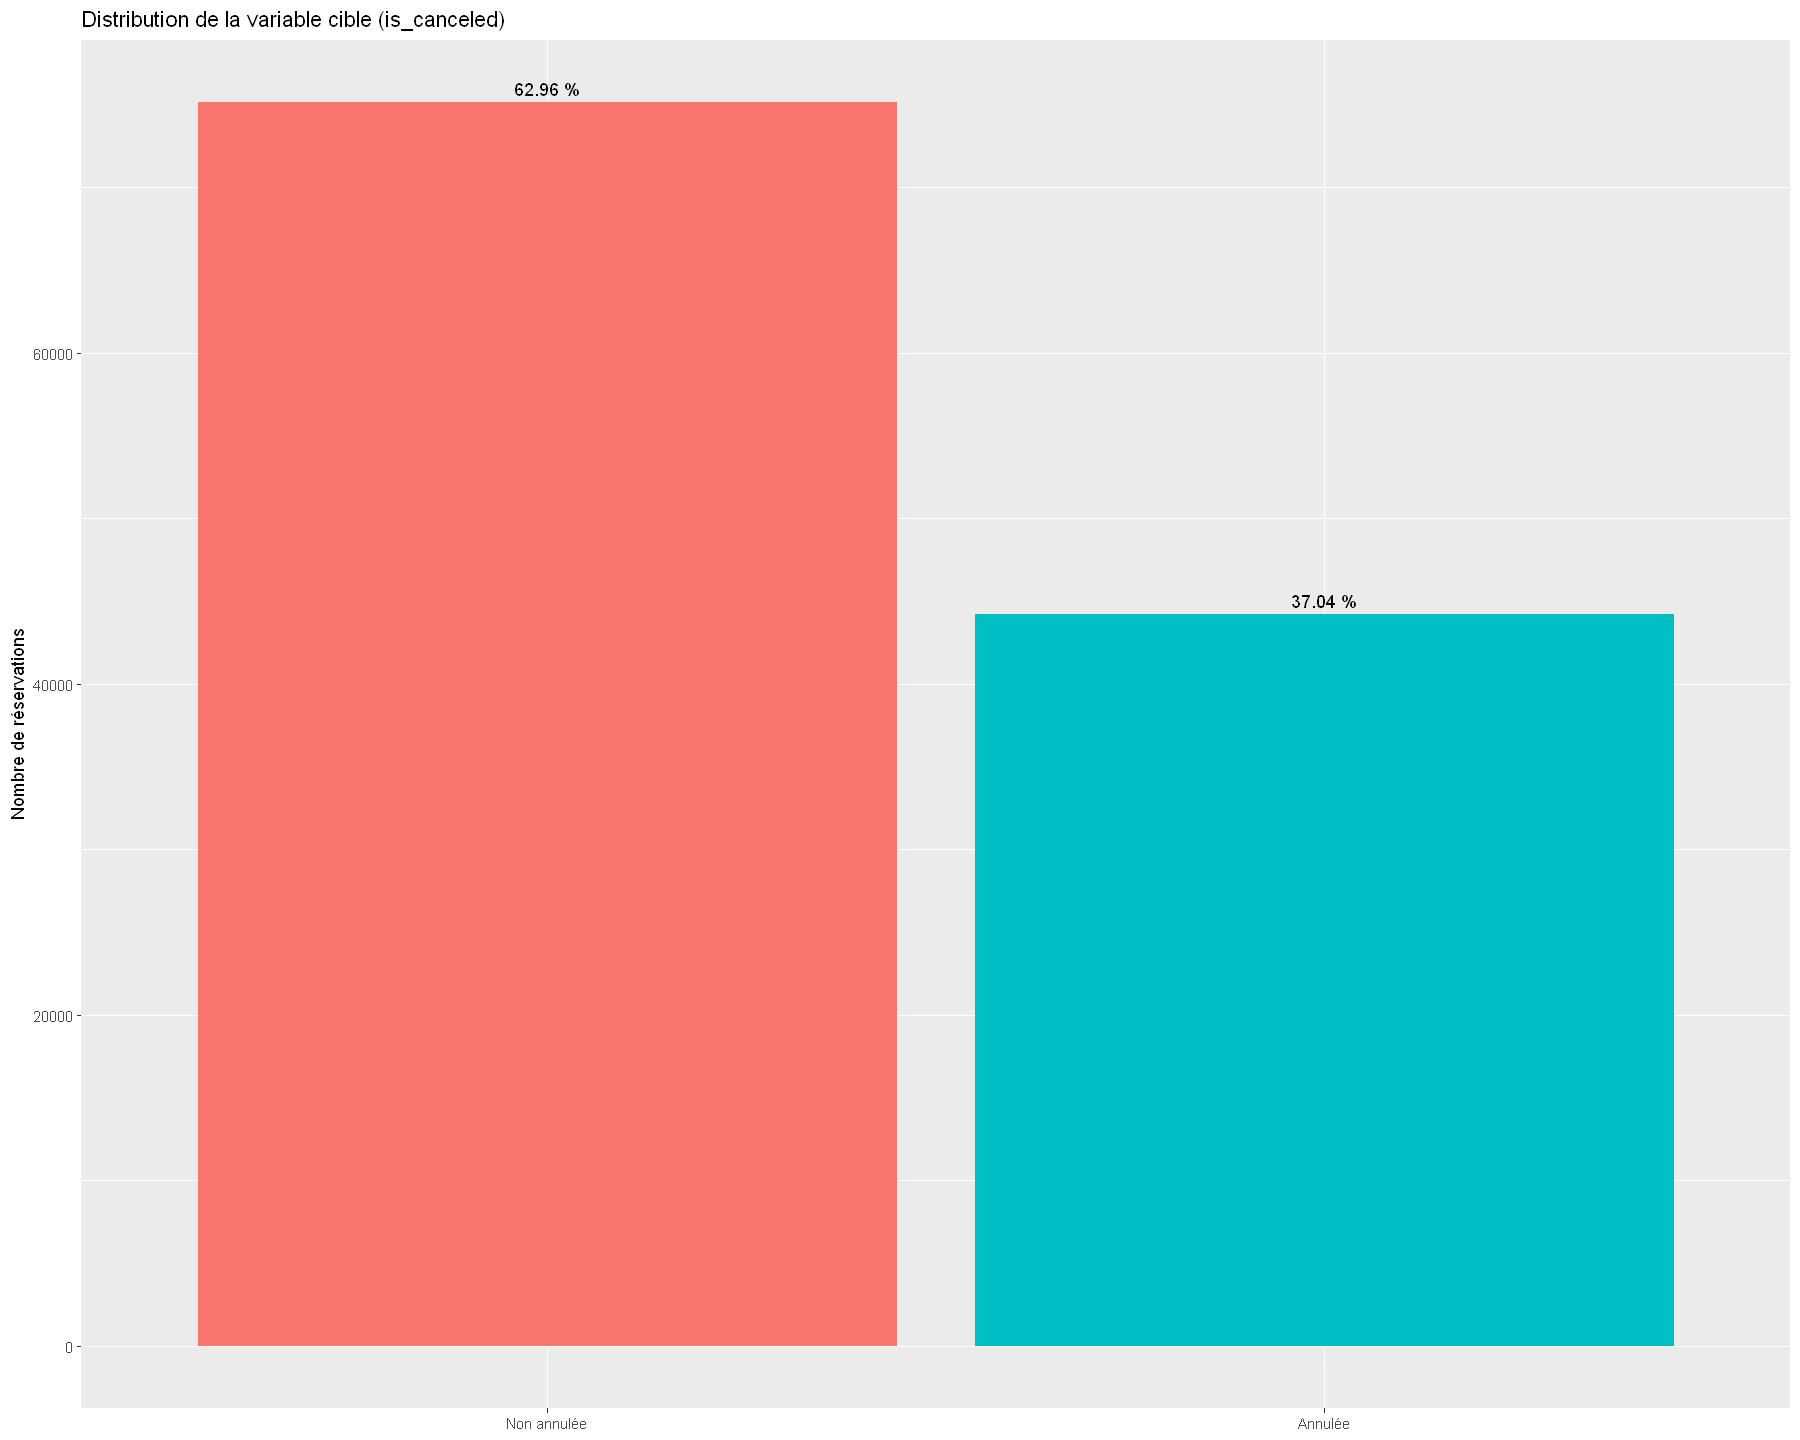

In [38]:
# ---------------------------------------------------------------------
# 3. La cible seule : combien d'annulations ?
# ---------------------------------------------------------------------
cible <- hotels %>%
  count(is_canceled) %>%
  mutate(pourcentage = round(n / sum(n) * 100, 2))
print(cible)

taux_global <- mean(hotels$is_canceled == "Annulée") * 100
cat("Taux d'annulation global :", round(taux_global, 2), "%\n")

# Création et affichage direct du graphique
p_cible <- ggplot(cible, aes(x = is_canceled, y = n, fill = is_canceled)) +
  geom_col() +
  geom_text(aes(label = paste0(pourcentage, " %")), vjust = -0.5) +
  labs(title = "Distribution de la variable cible (is_canceled)",
       x = NULL, y = "Nombre de réservations") +
  theme(legend.position = "none")

print(p_cible)

# A tibble: 17 × 14
   variable           n n_manquants moyenne ecart_type   min    q1 mediane    q3
   <chr>          <int>       <int>   <dbl>      <dbl> <dbl> <dbl>   <dbl> <dbl>
 1 lead_time     119390           0 1.04e+2   107.      0     18      69     160
 2 arrival_date… 119390           0 2.72e+1    13.6     1     16      28      38
 3 arrival_date… 119390           0 1.58e+1     8.78    1      8      16      23
 4 stays_in_wee… 119390           0 9.28e-1     0.999   0      0       1       2
 5 stays_in_wee… 119390           0 2.50e+0     1.91    0      1       2       3
 6 total_nights  119390           0 3.43e+0     2.56    0      2       3       4
 7 adults        119390           0 1.86e+0     0.579   0      2       2       2
 8 children      119386           4 1.04e-1     0.399   0      0       0       0
 9 babies        119390           0 7.95e-3     0.0974  0      0       0       0
10 total_guests  119390           0 1.97e+0     0.722   0      2       2       2
11 previ

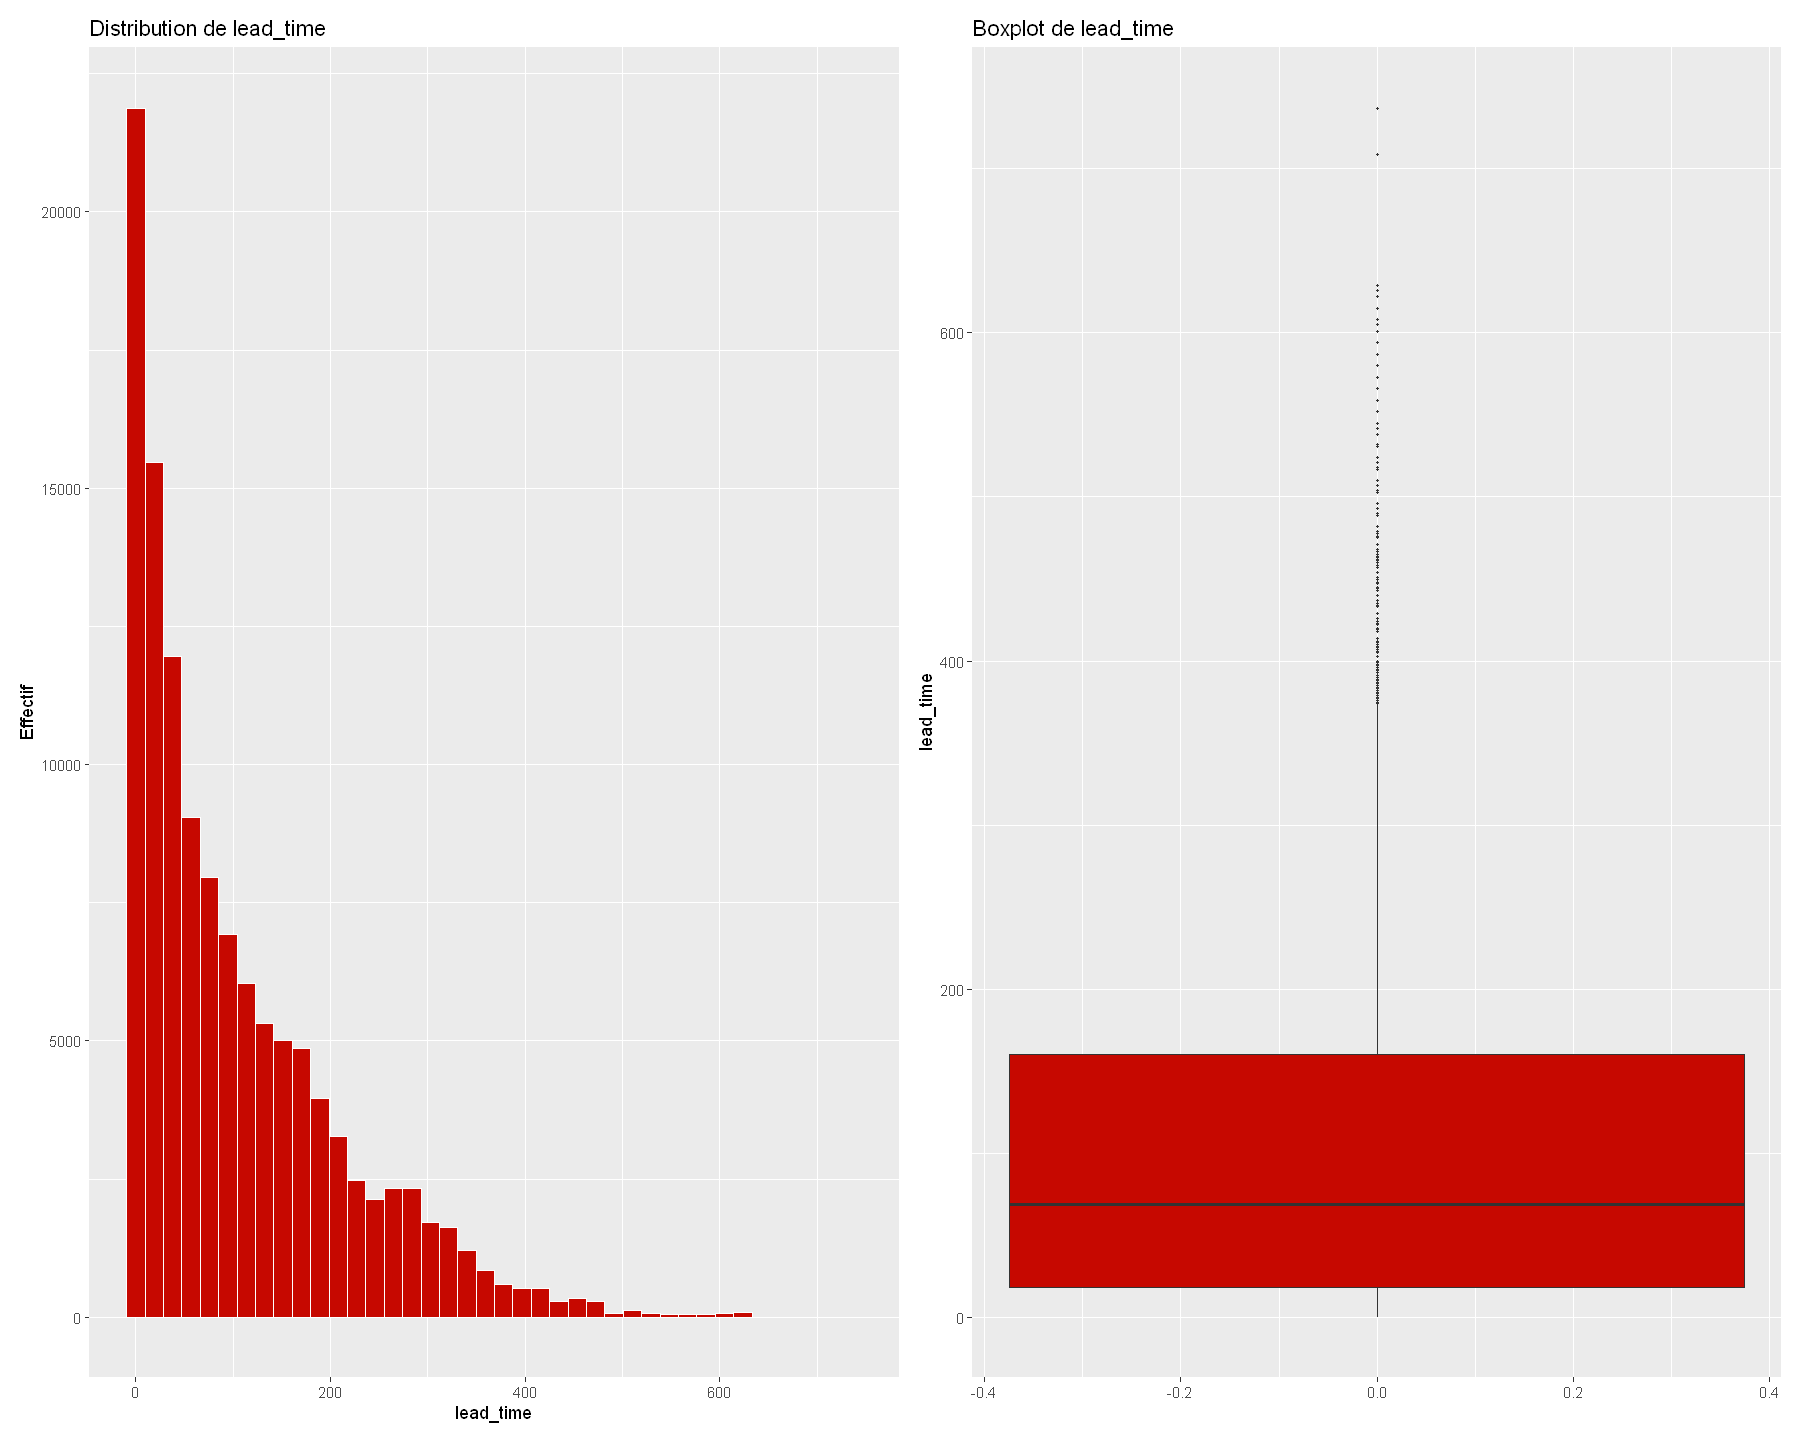

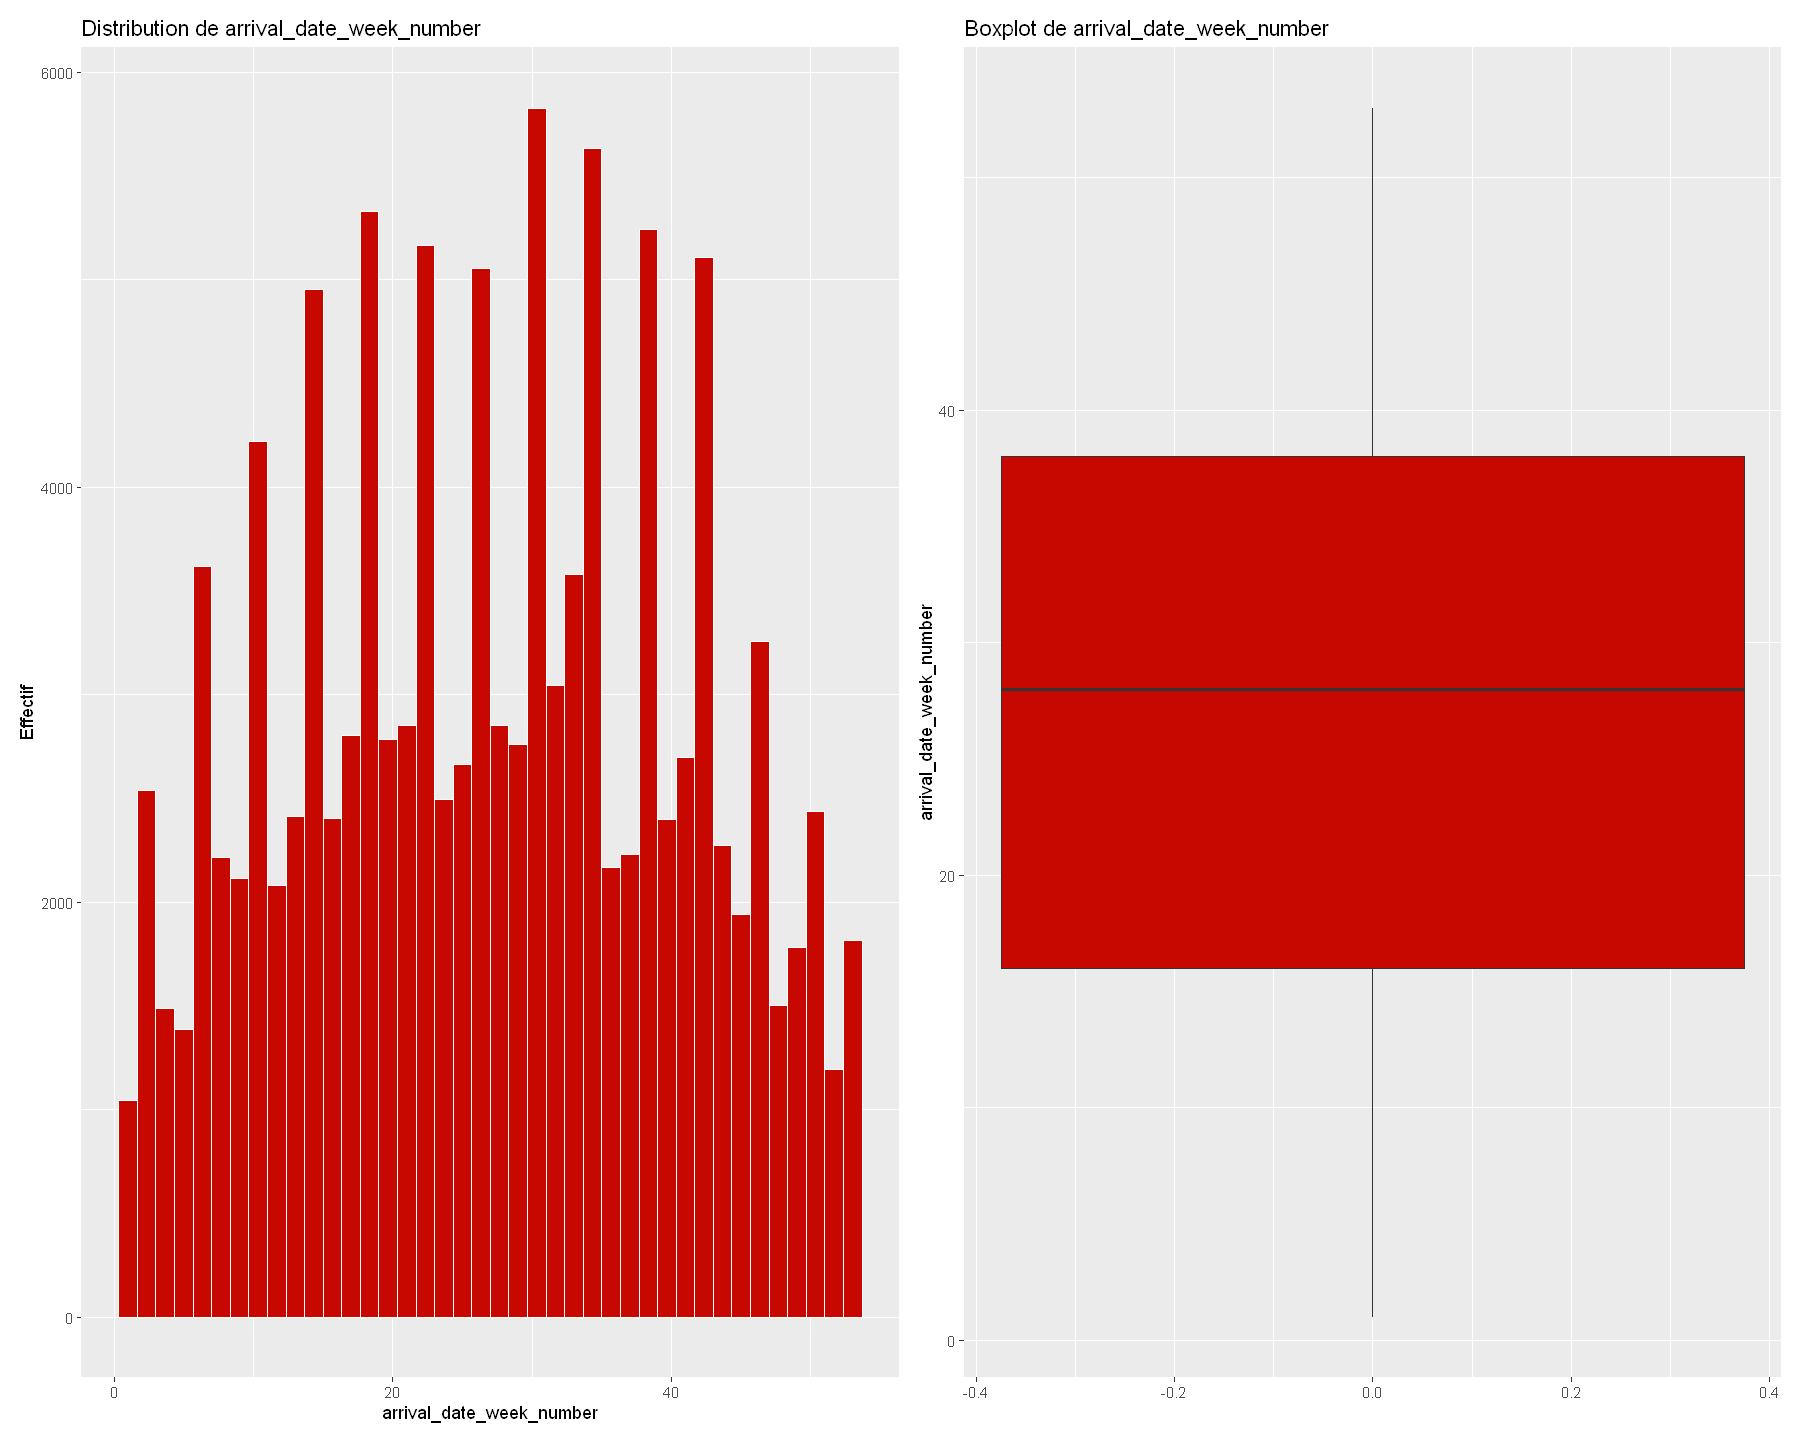

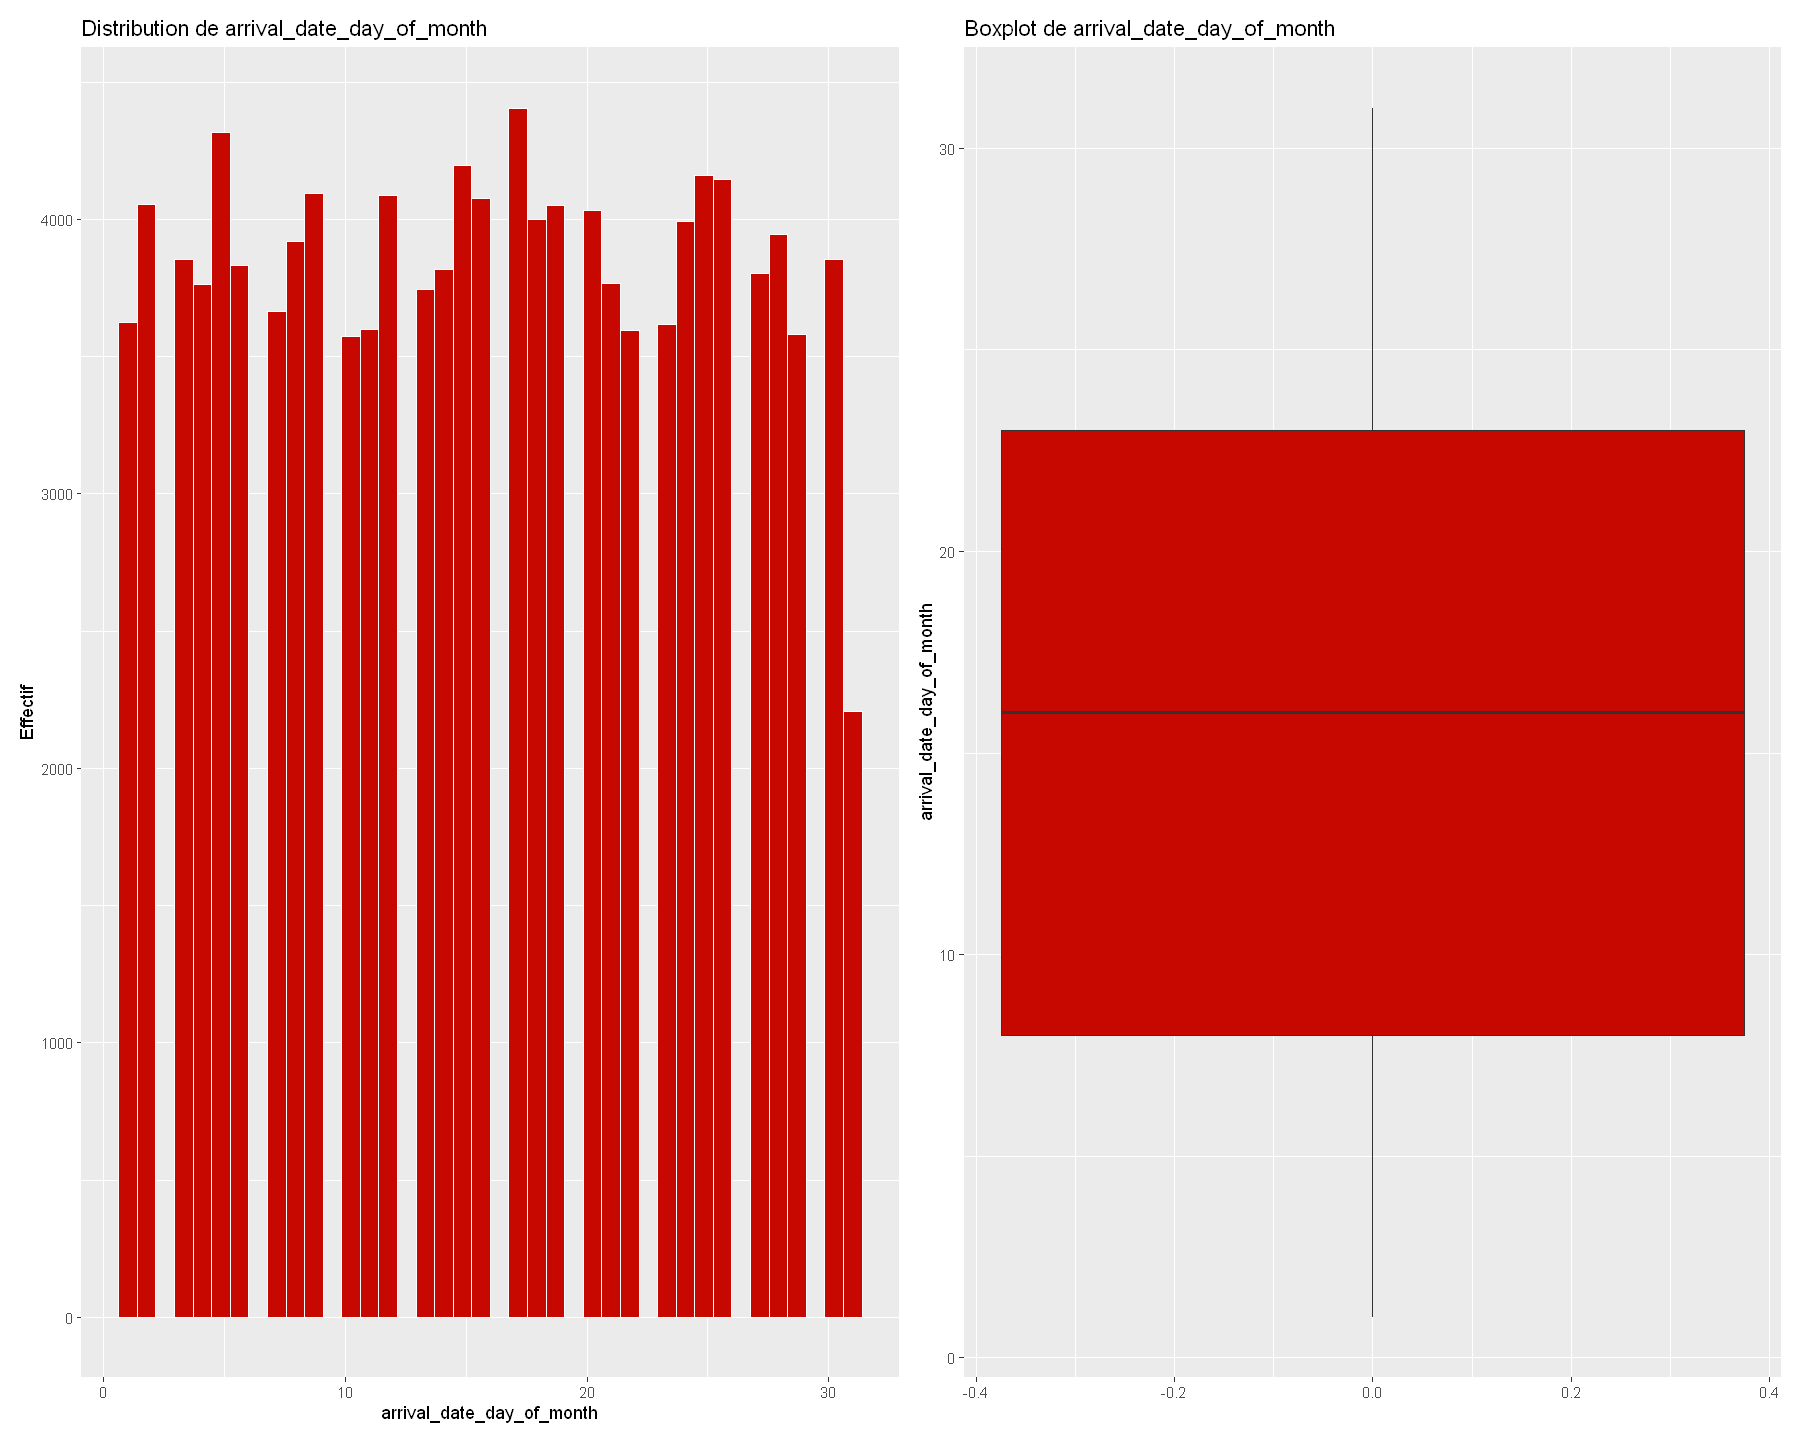

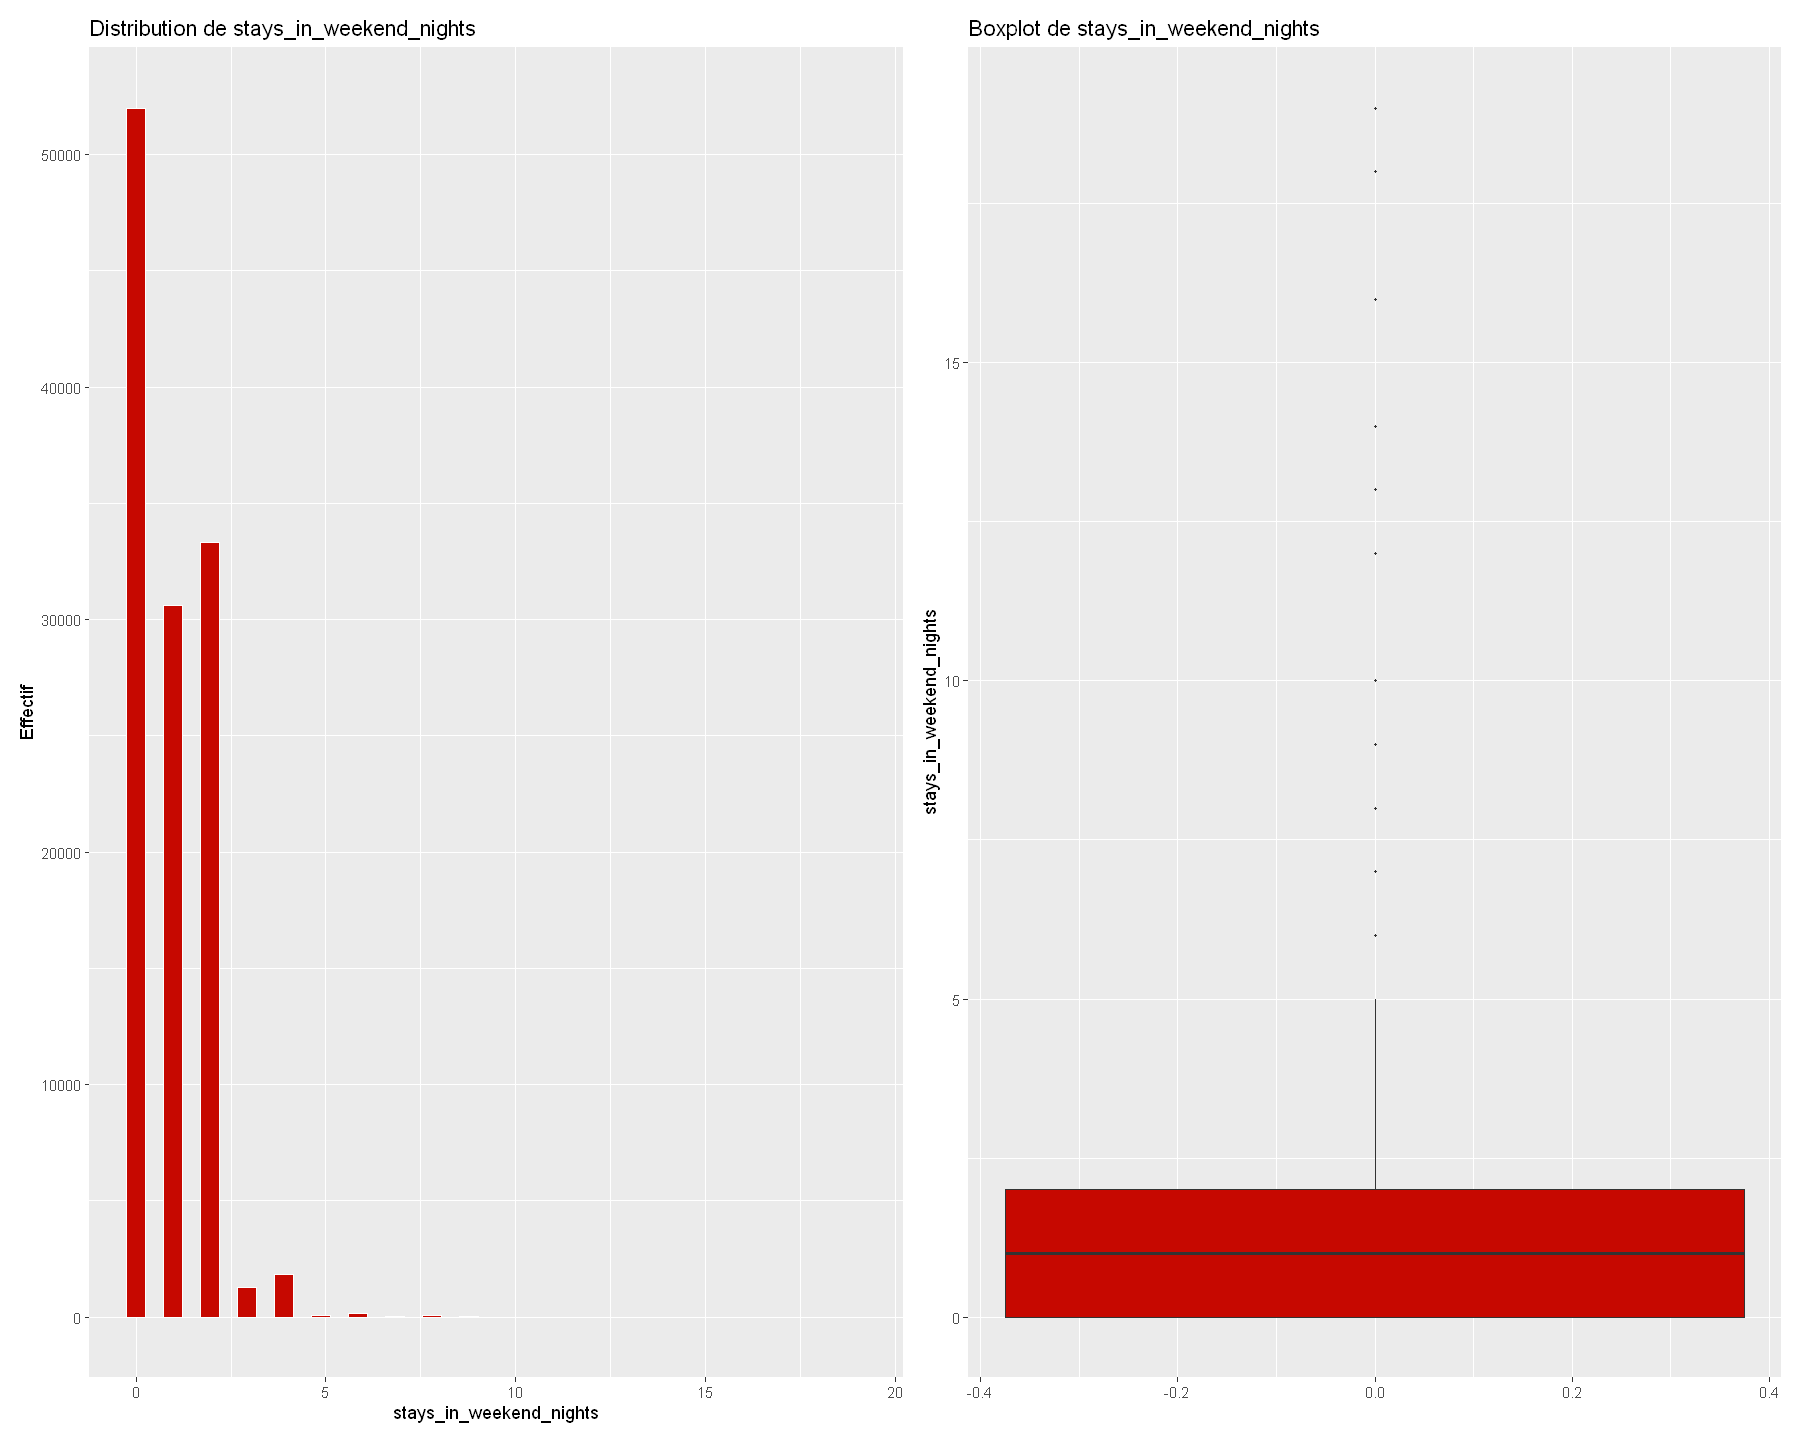

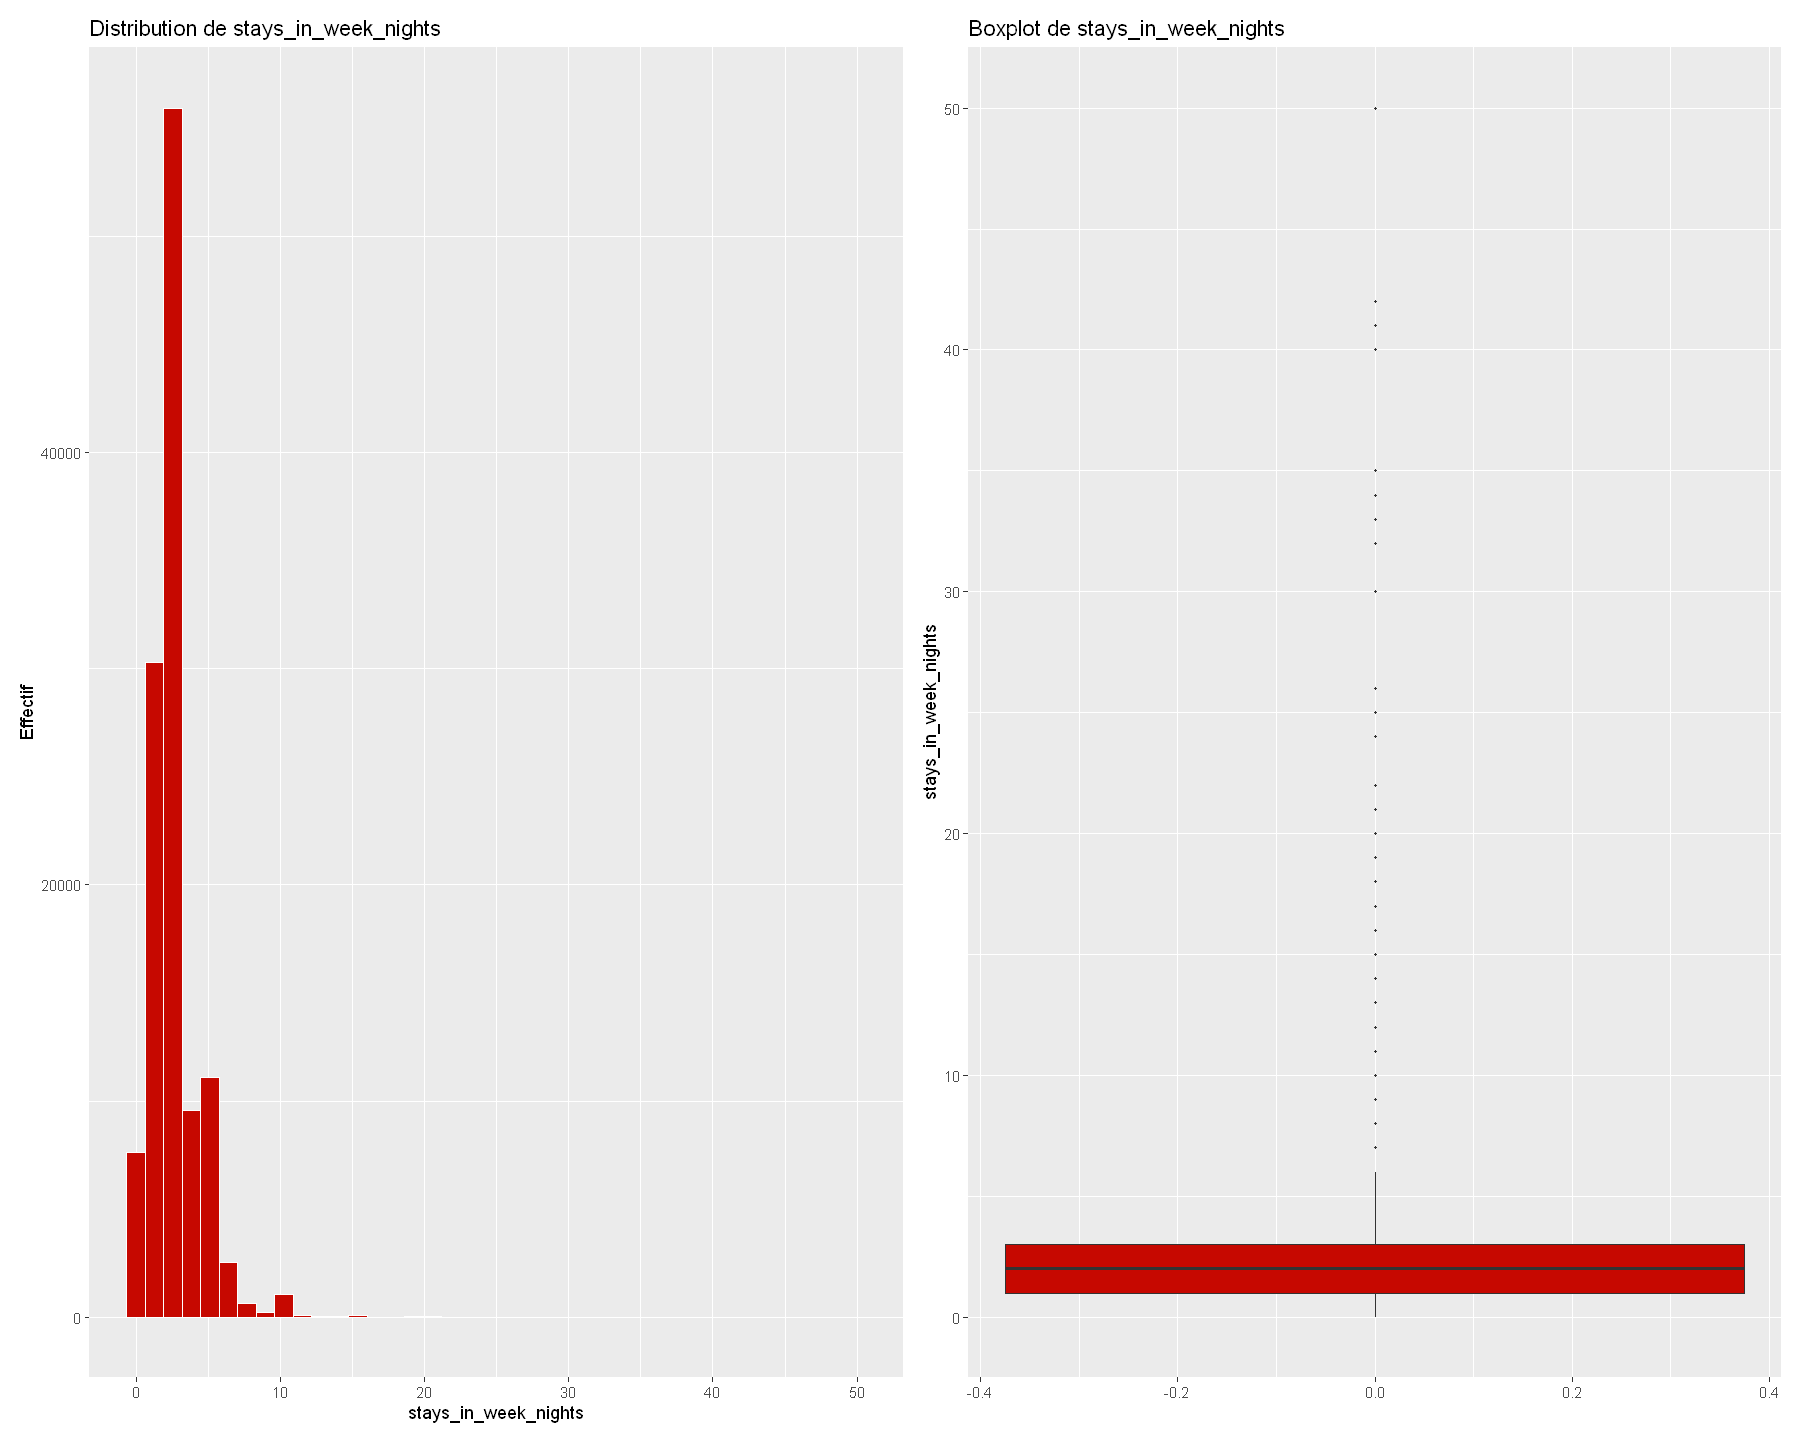

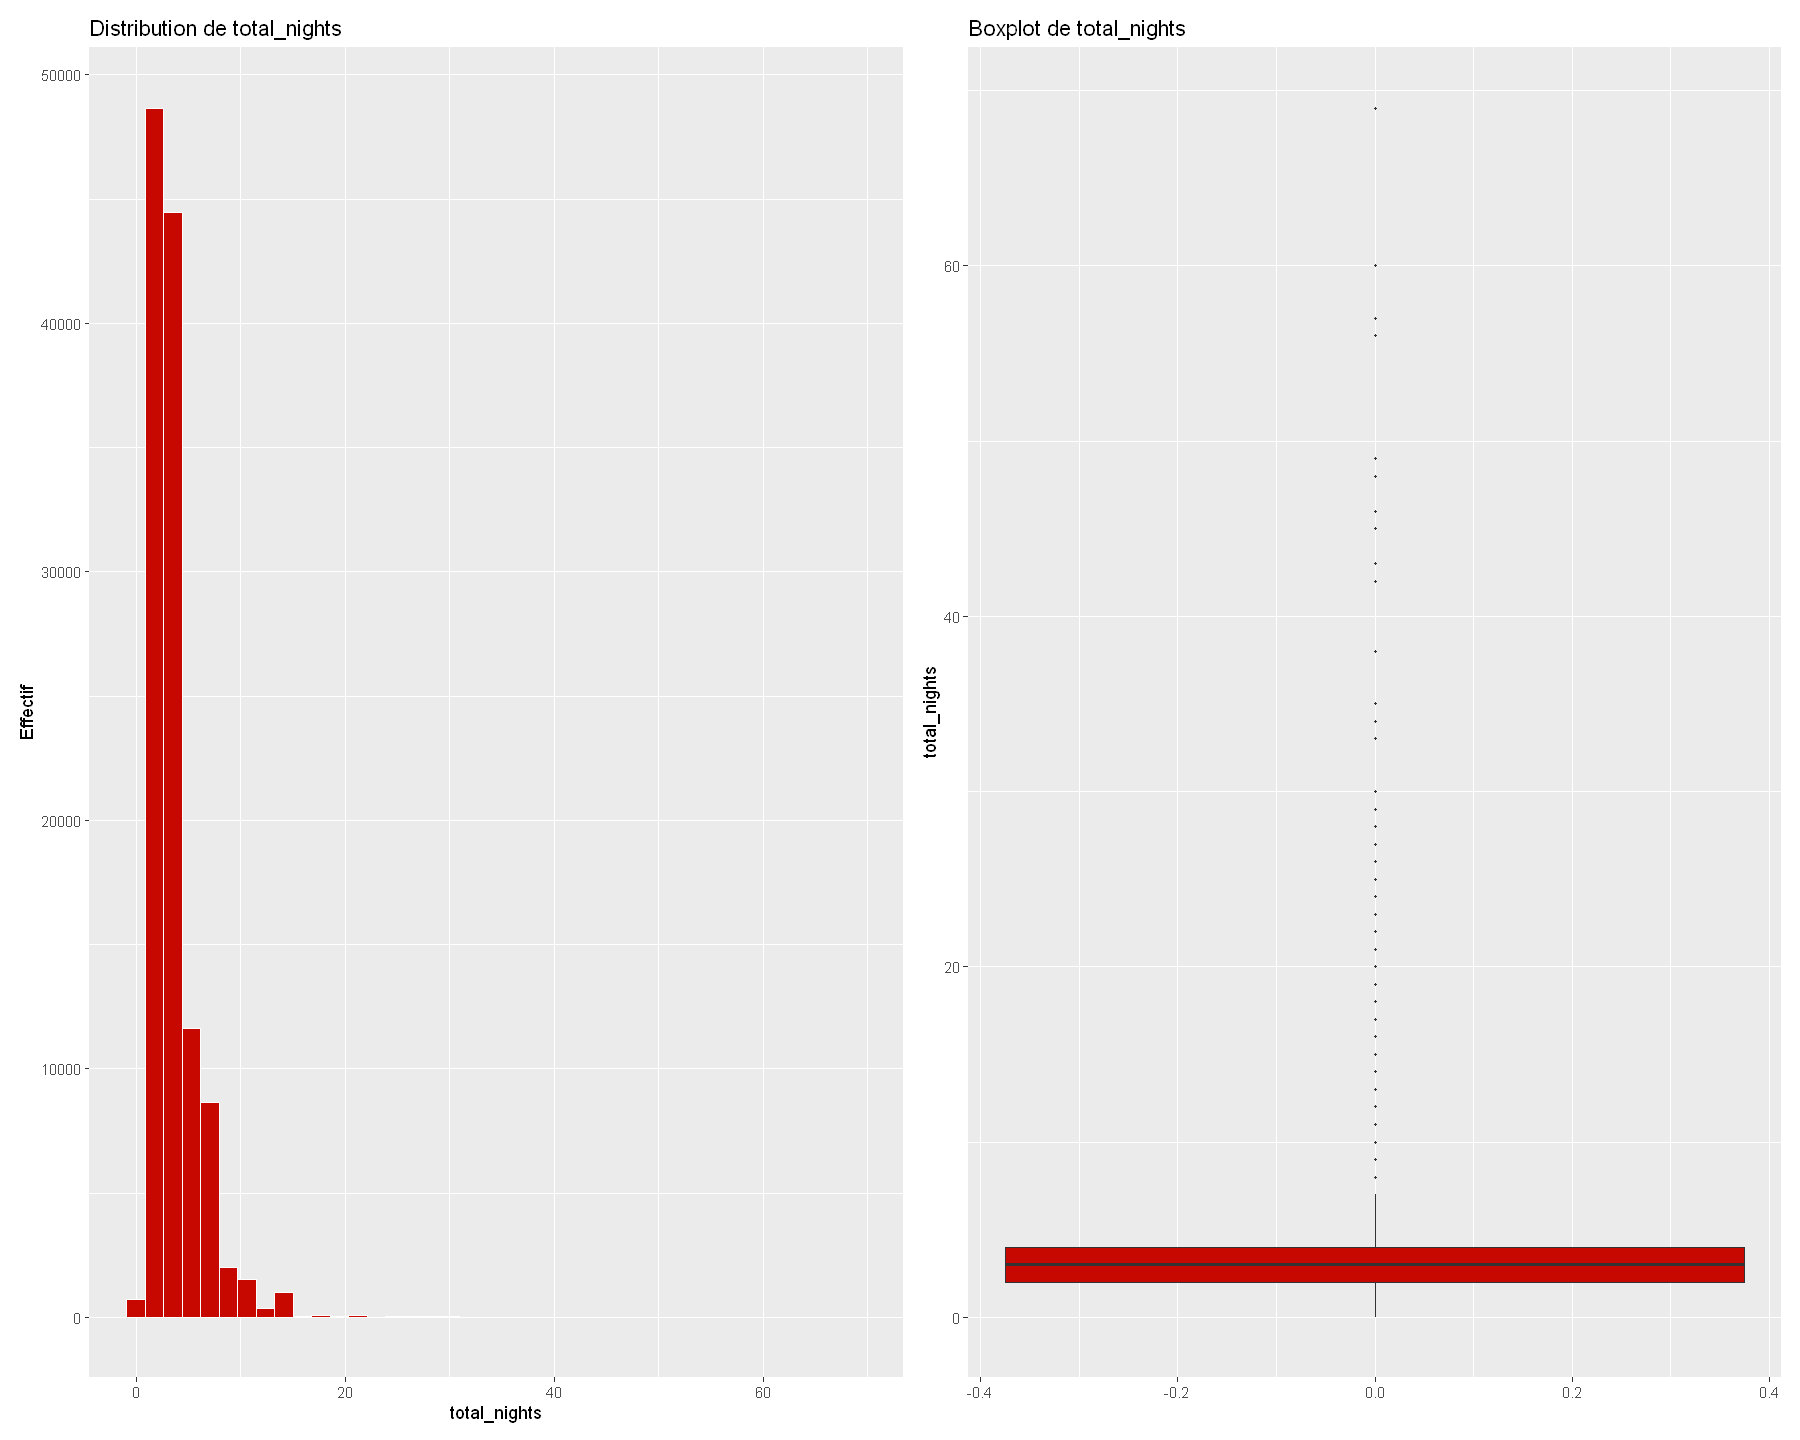

Warning message:
"Removed 4 rows containing non-finite outside the scale range (`stat_bin()`)."
Warning message:
"Removed 4 rows containing non-finite outside the scale range (`stat_boxplot()`)."


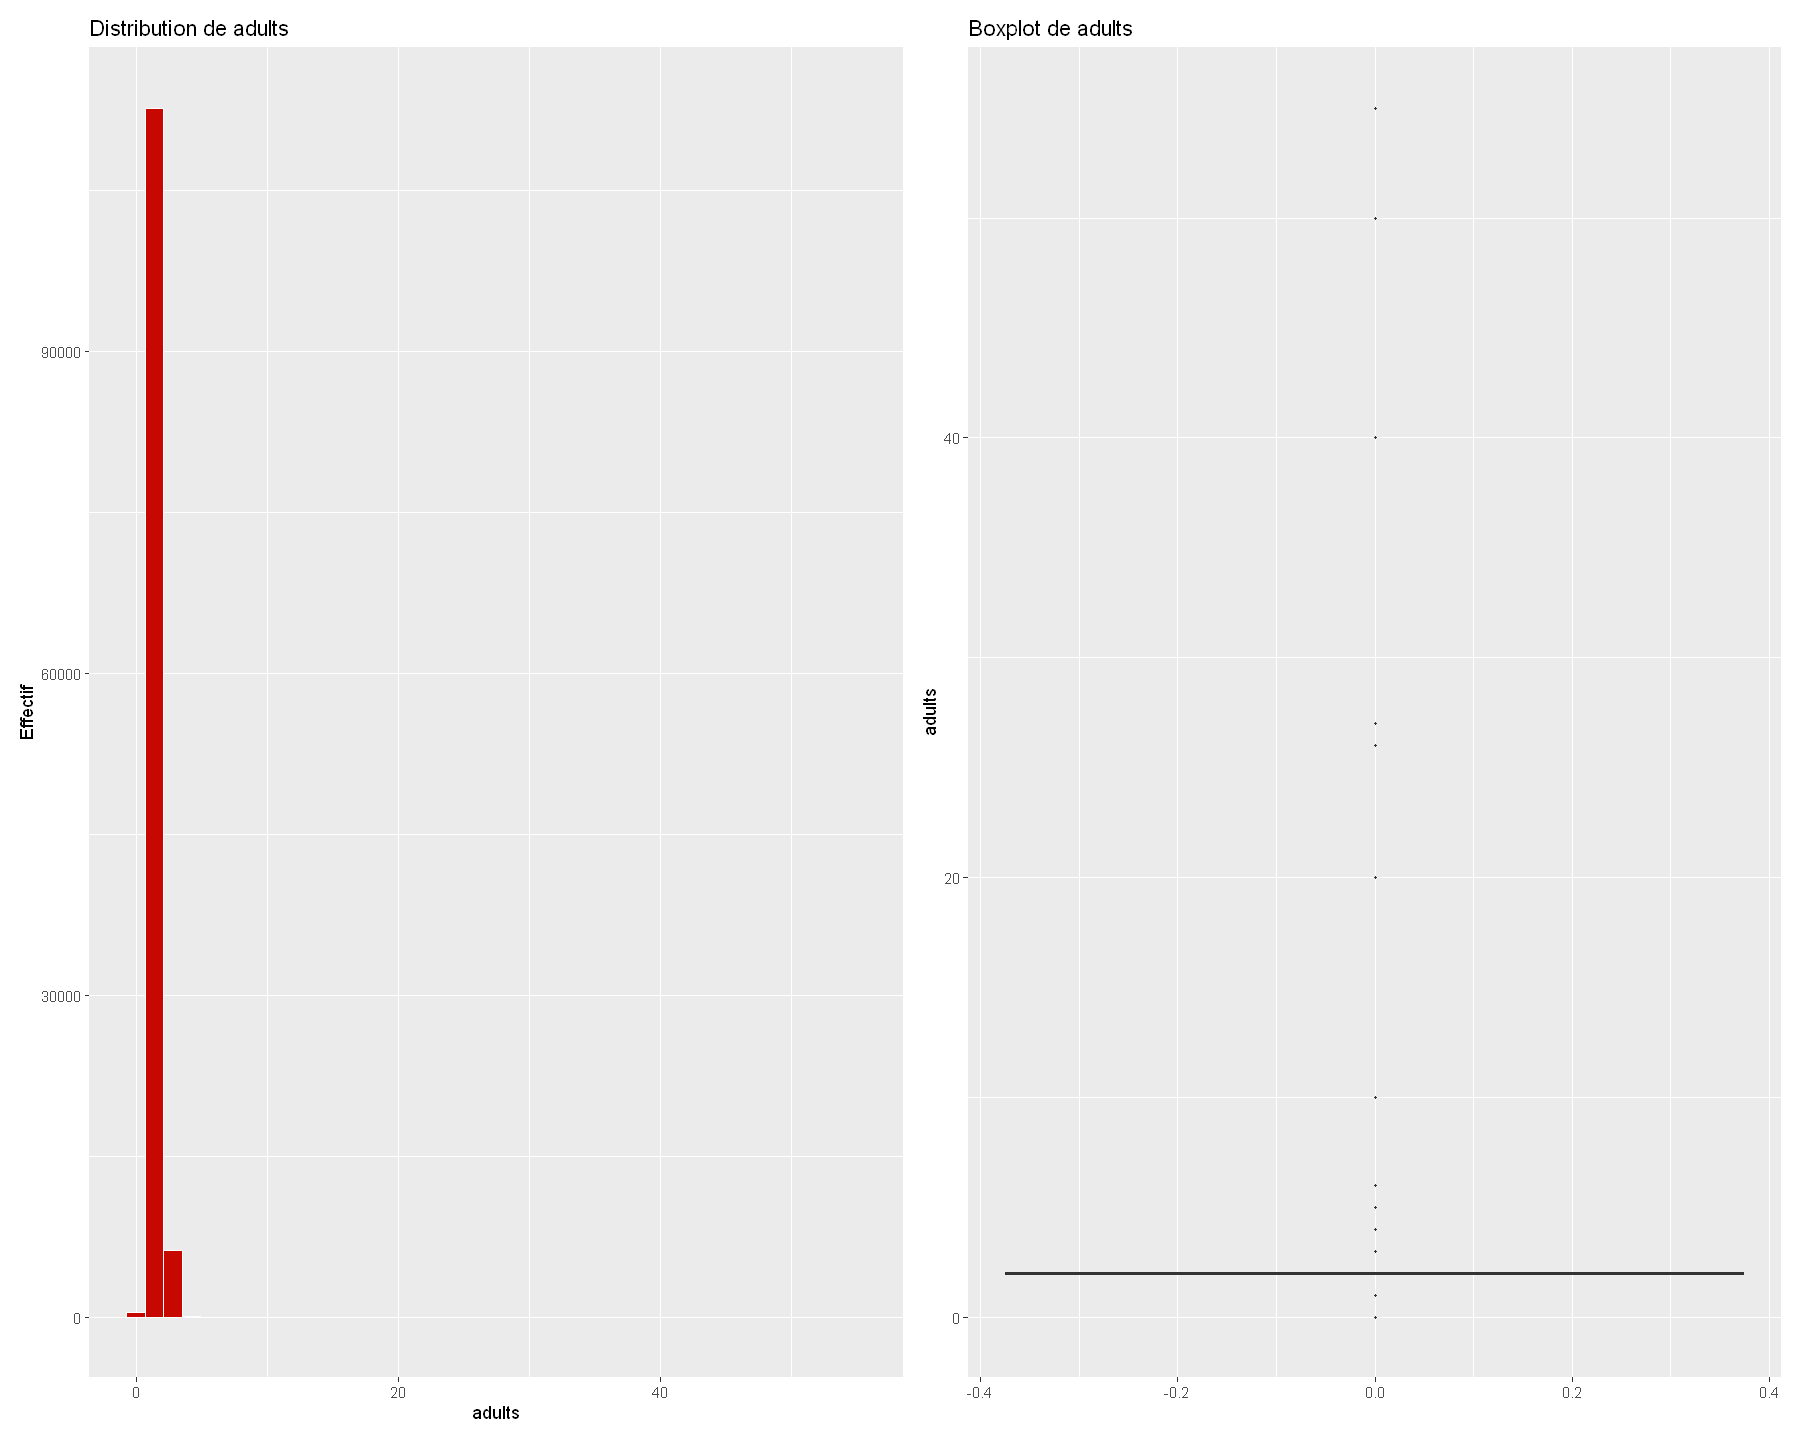

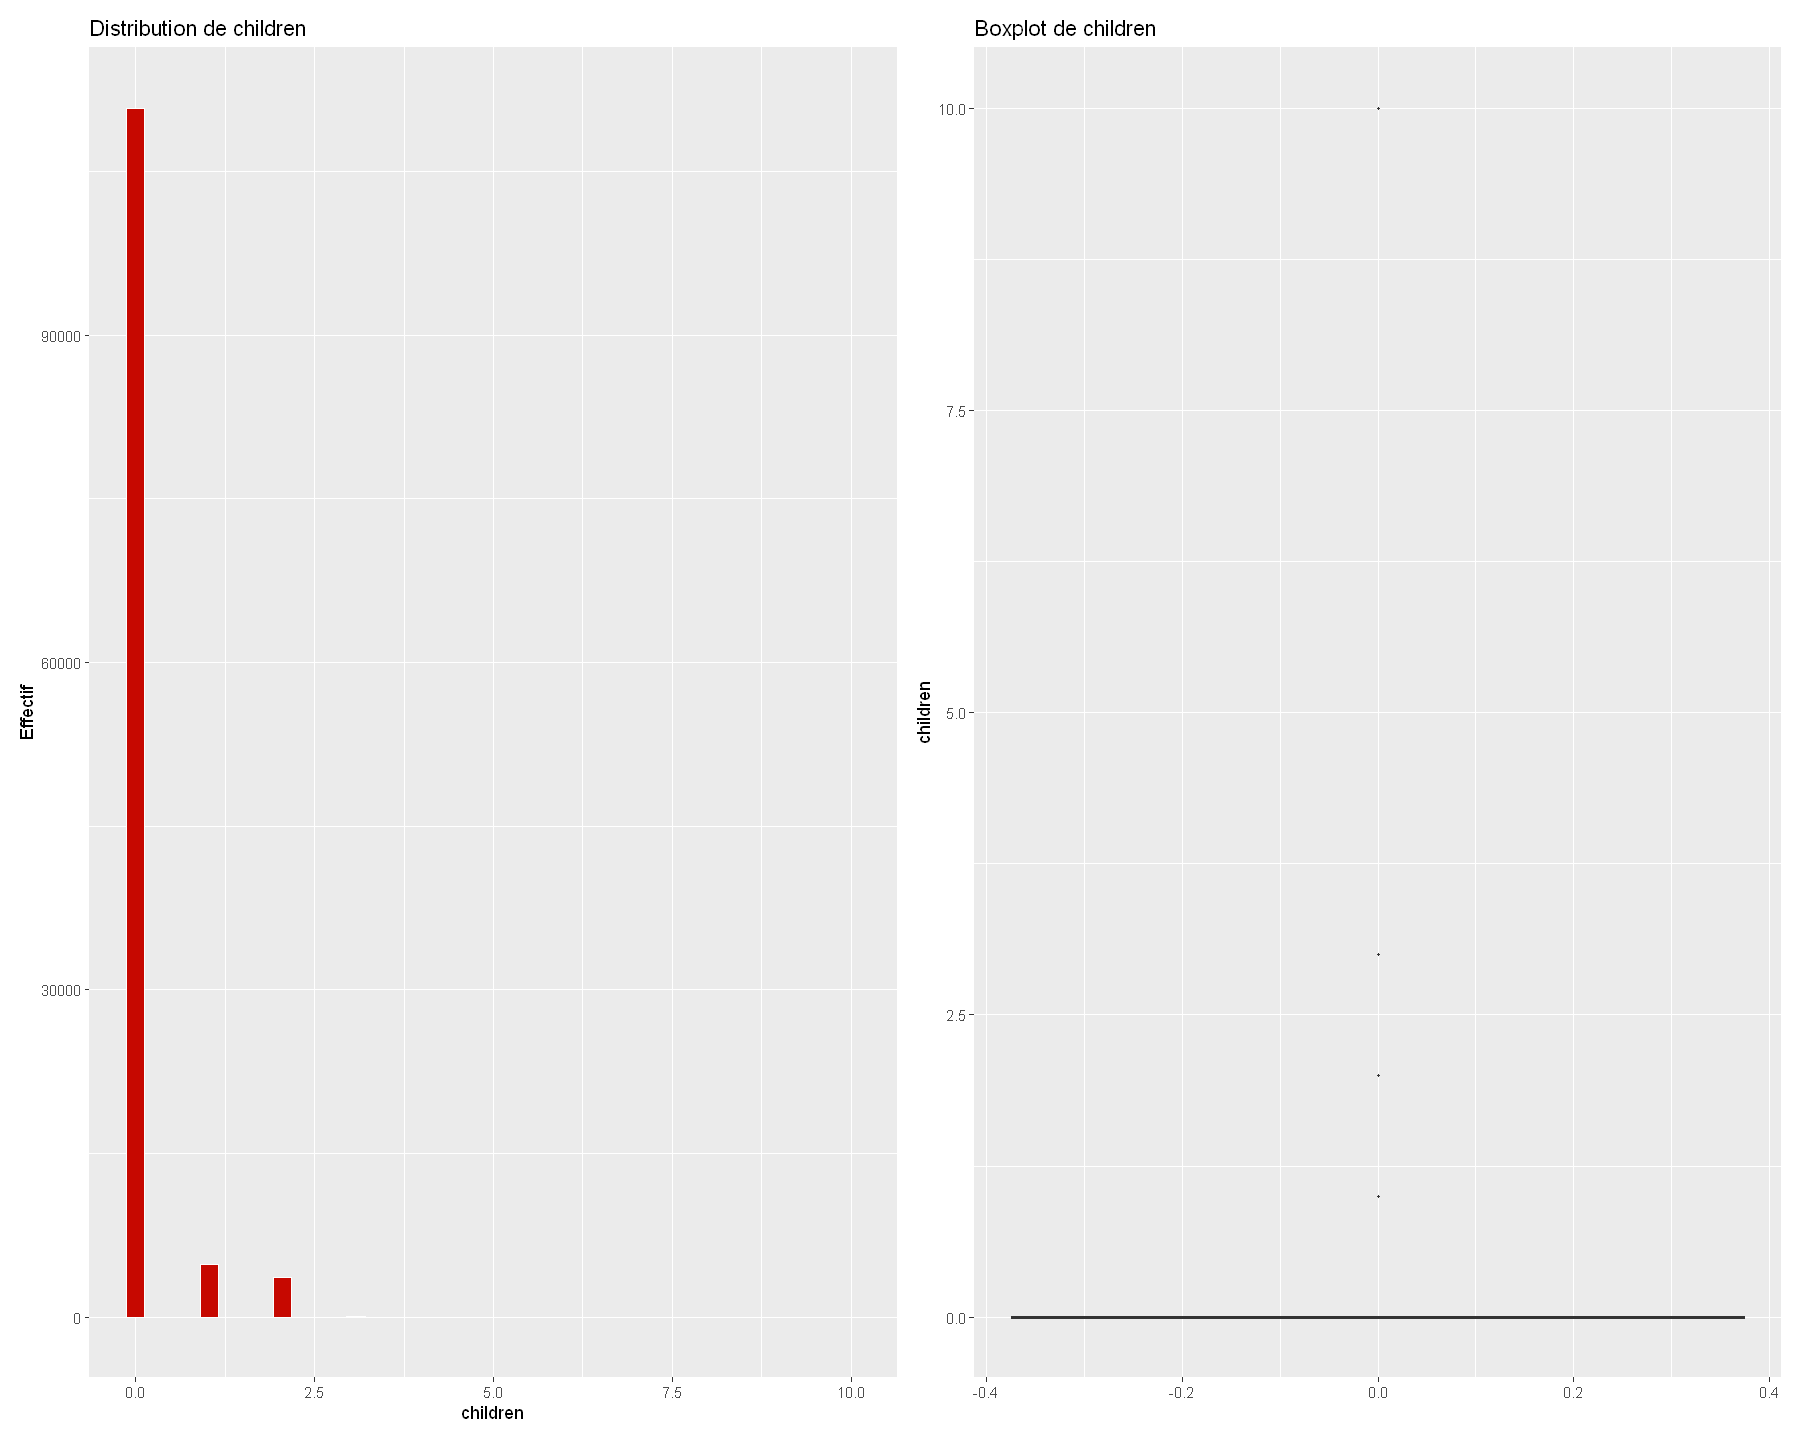

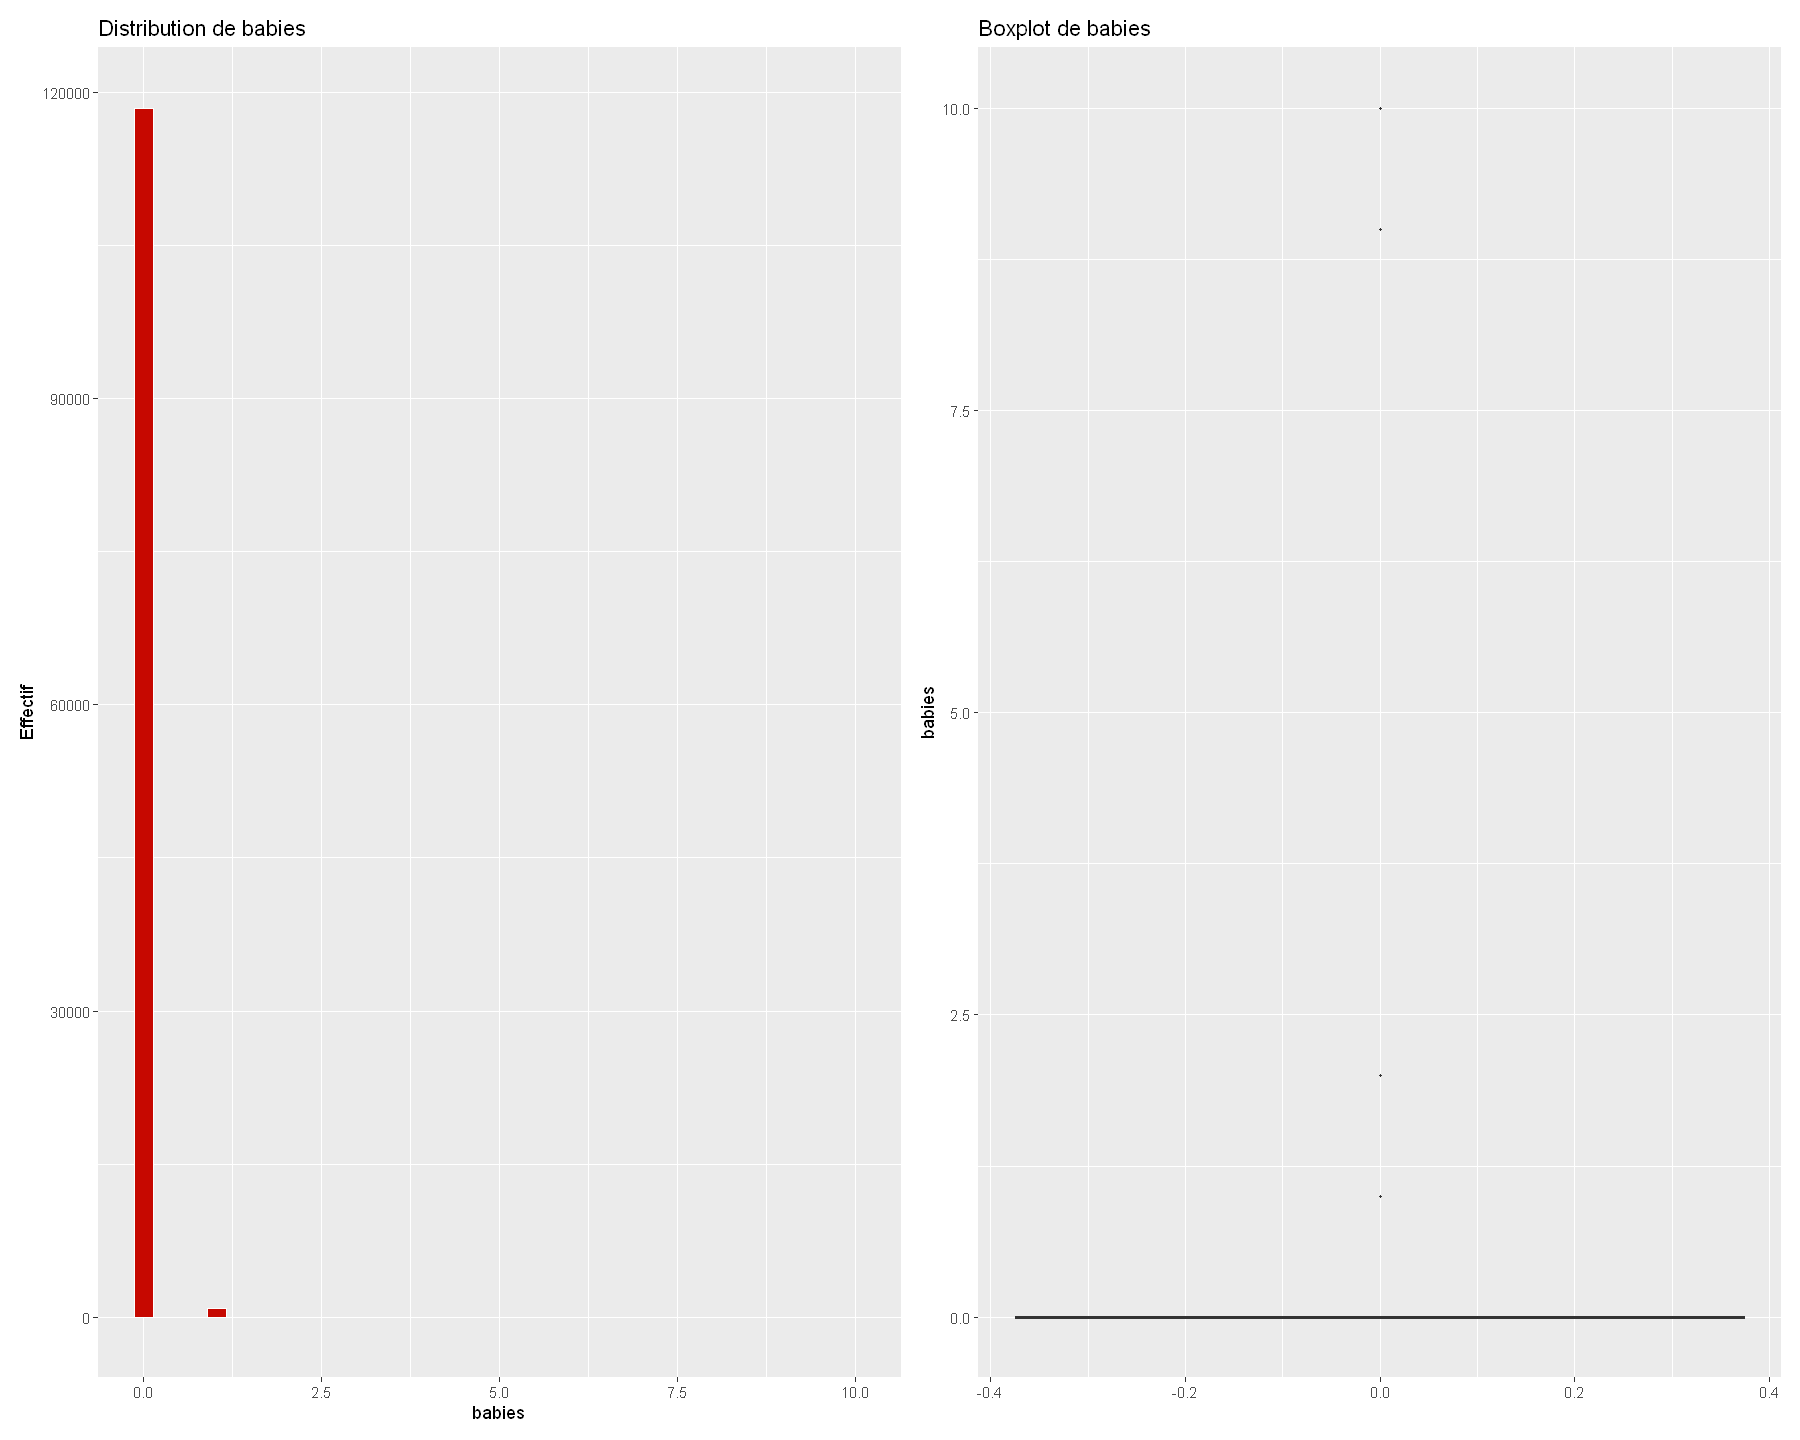

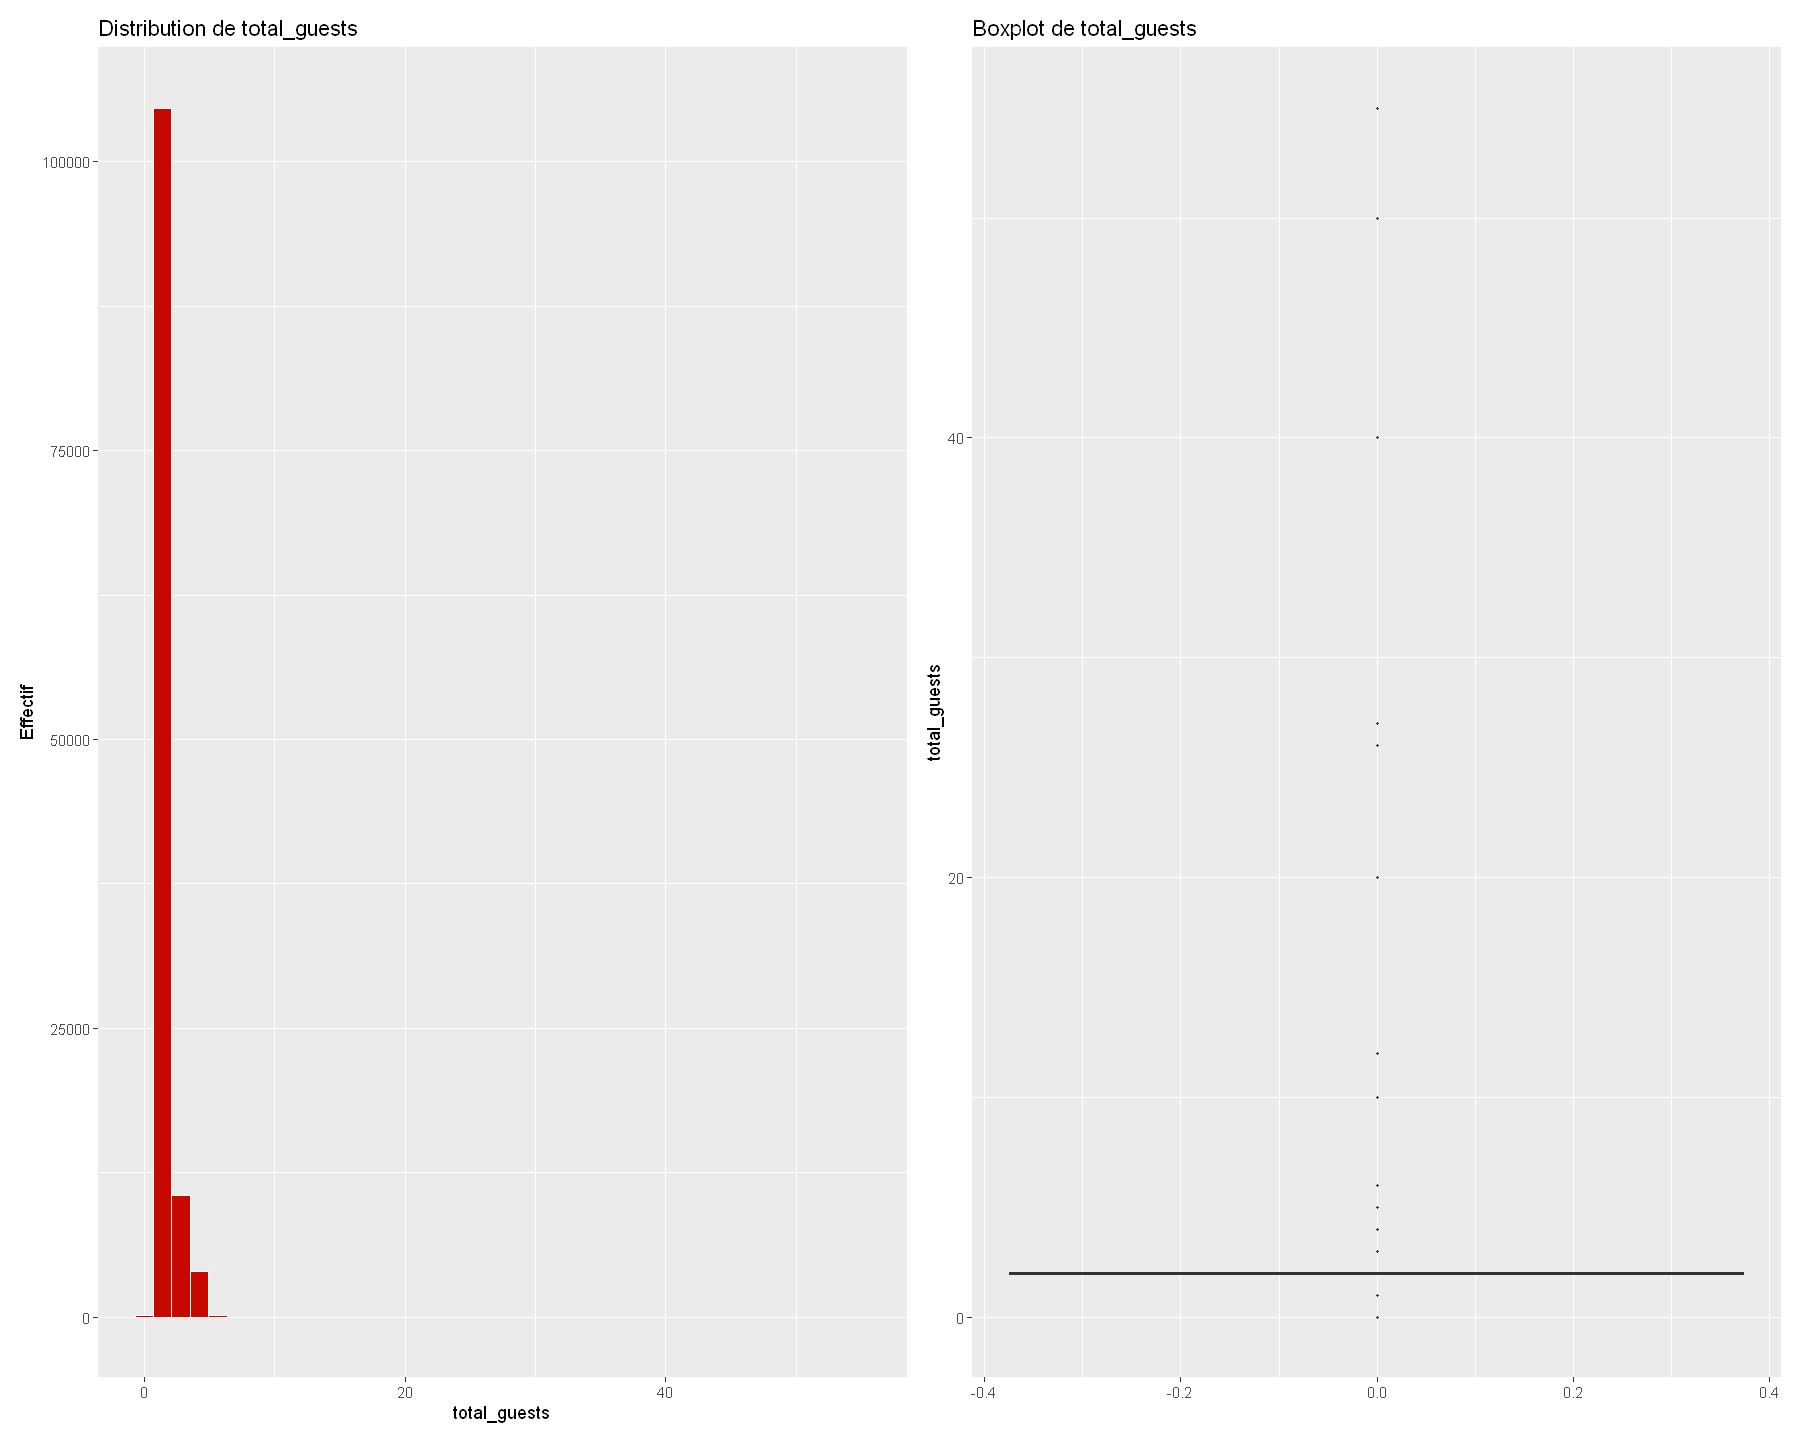

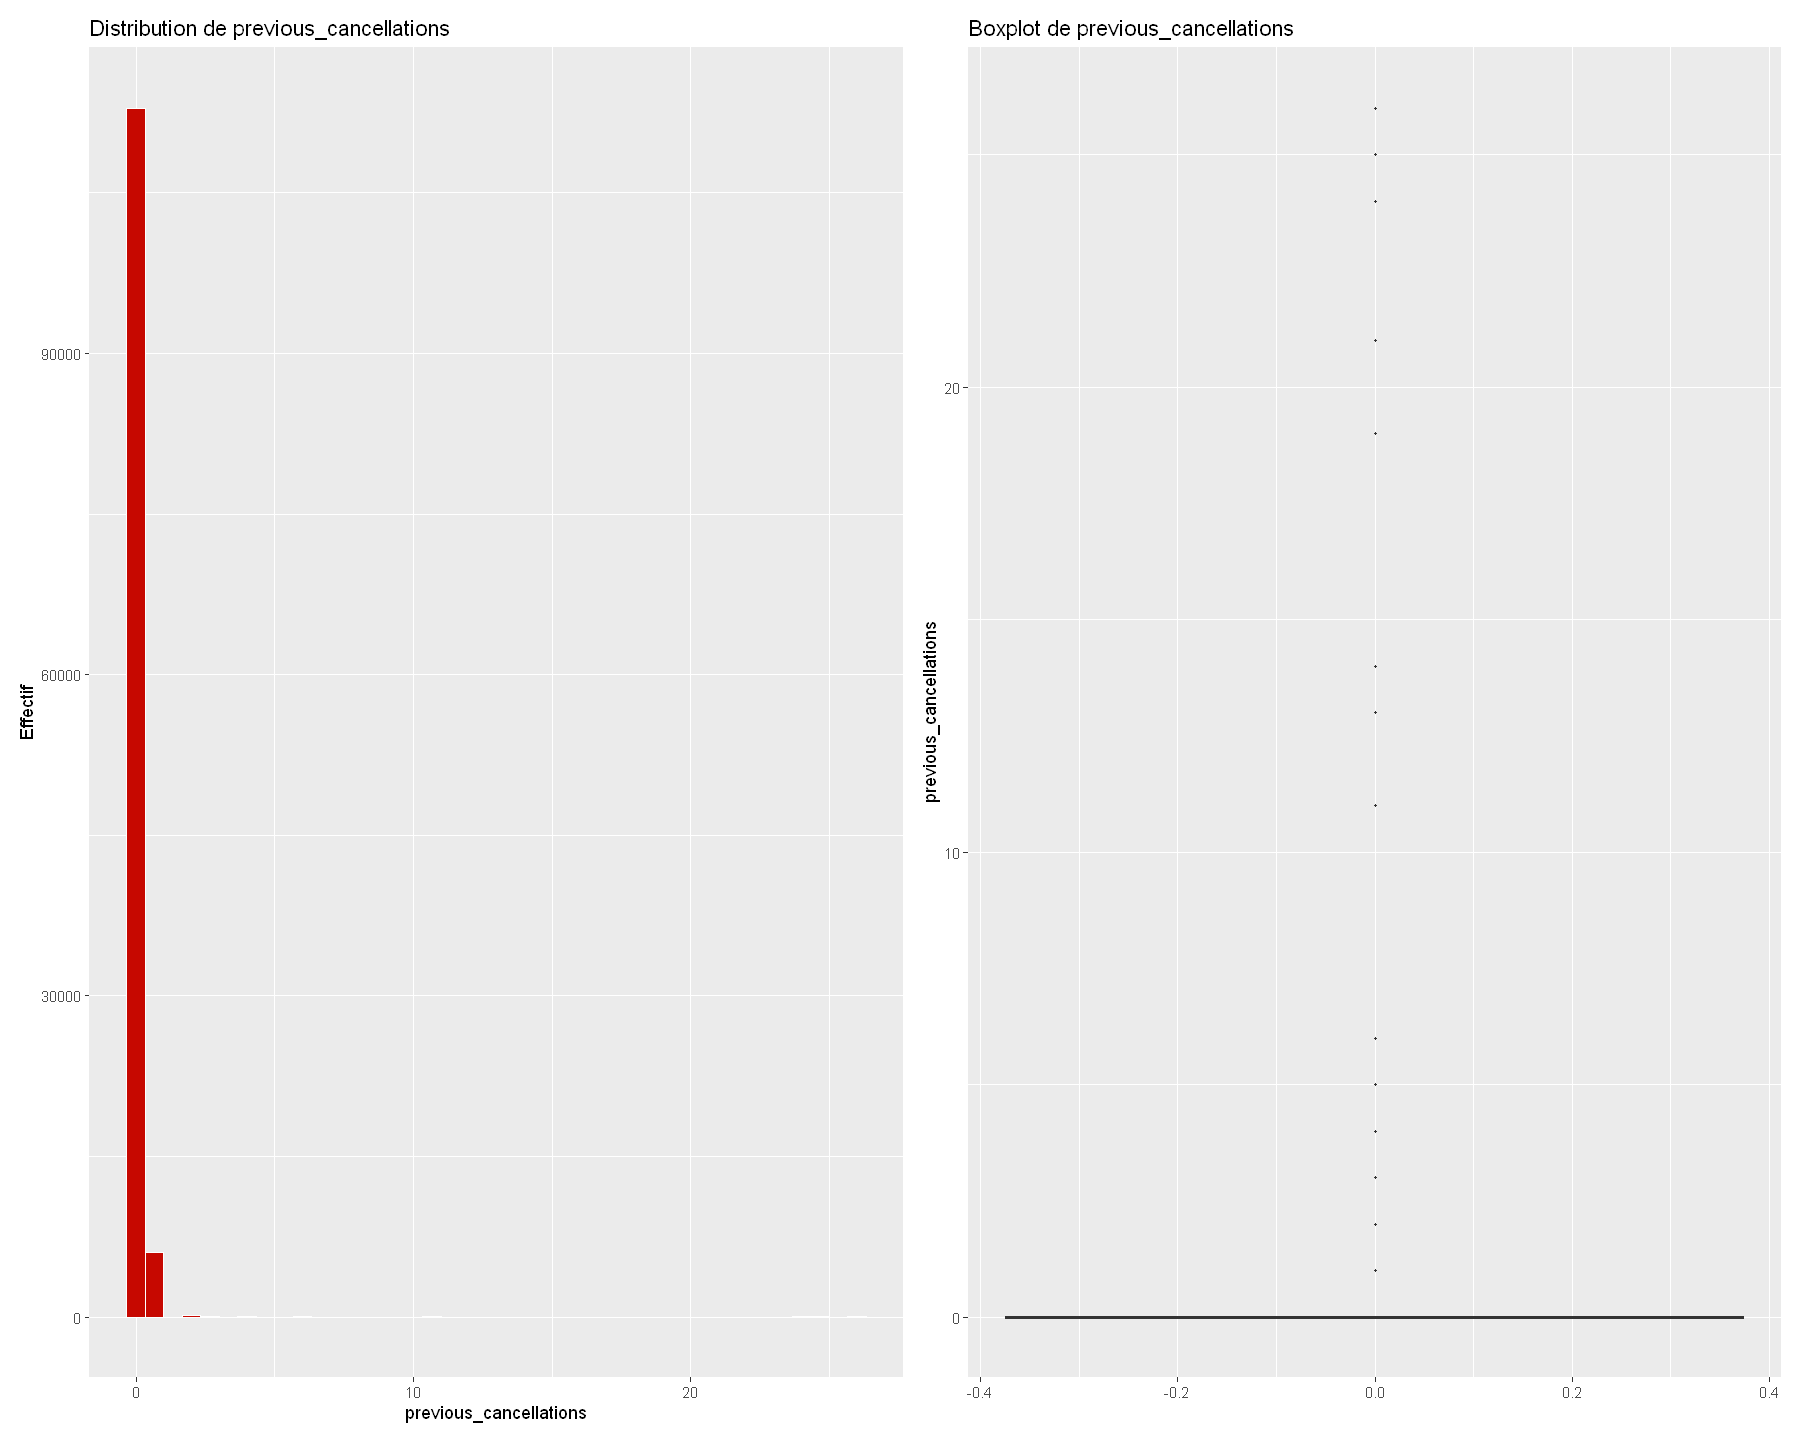

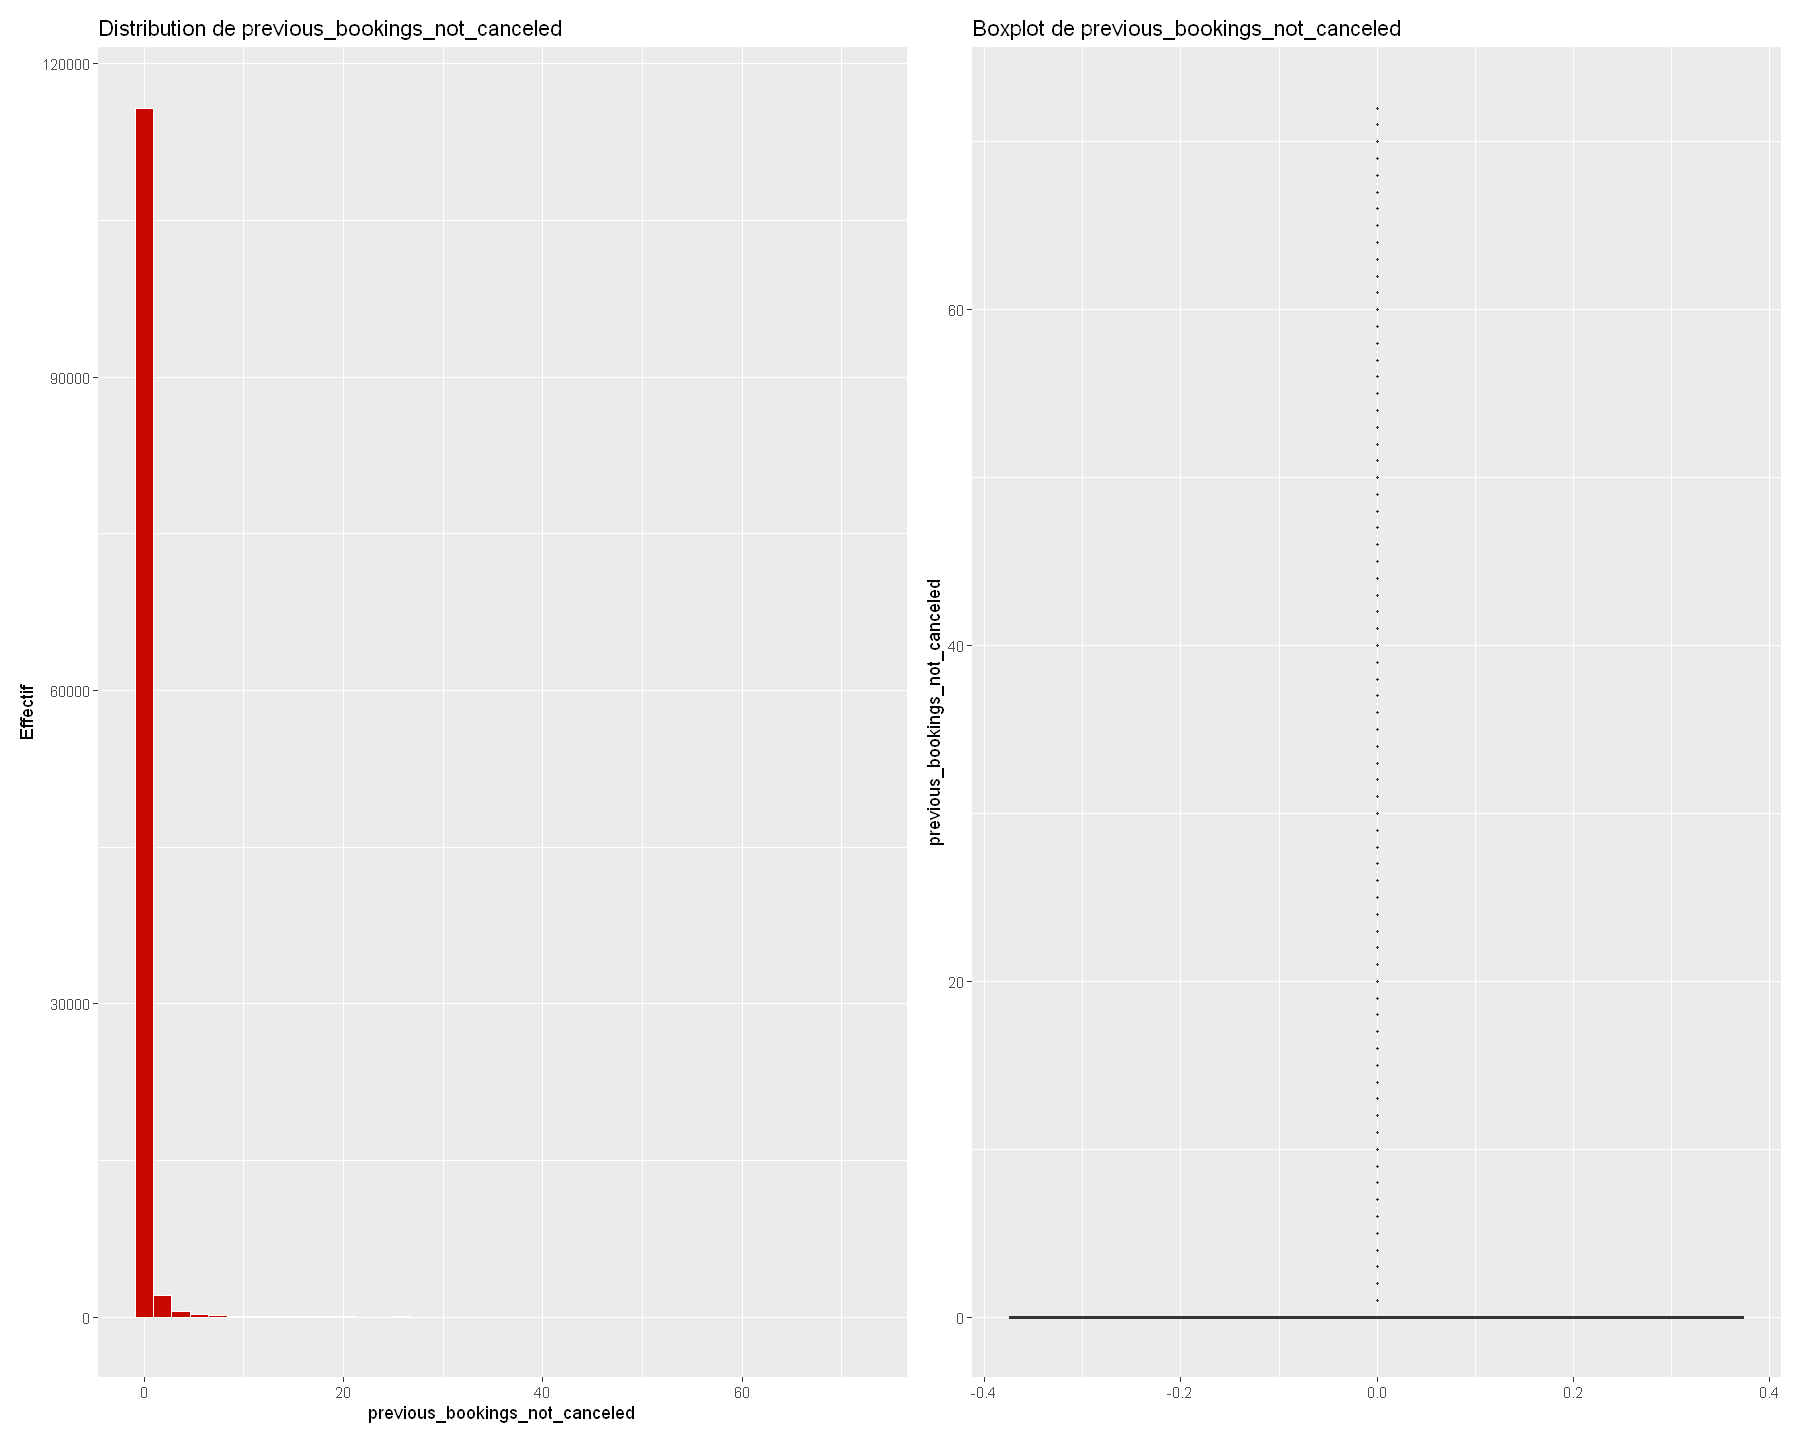

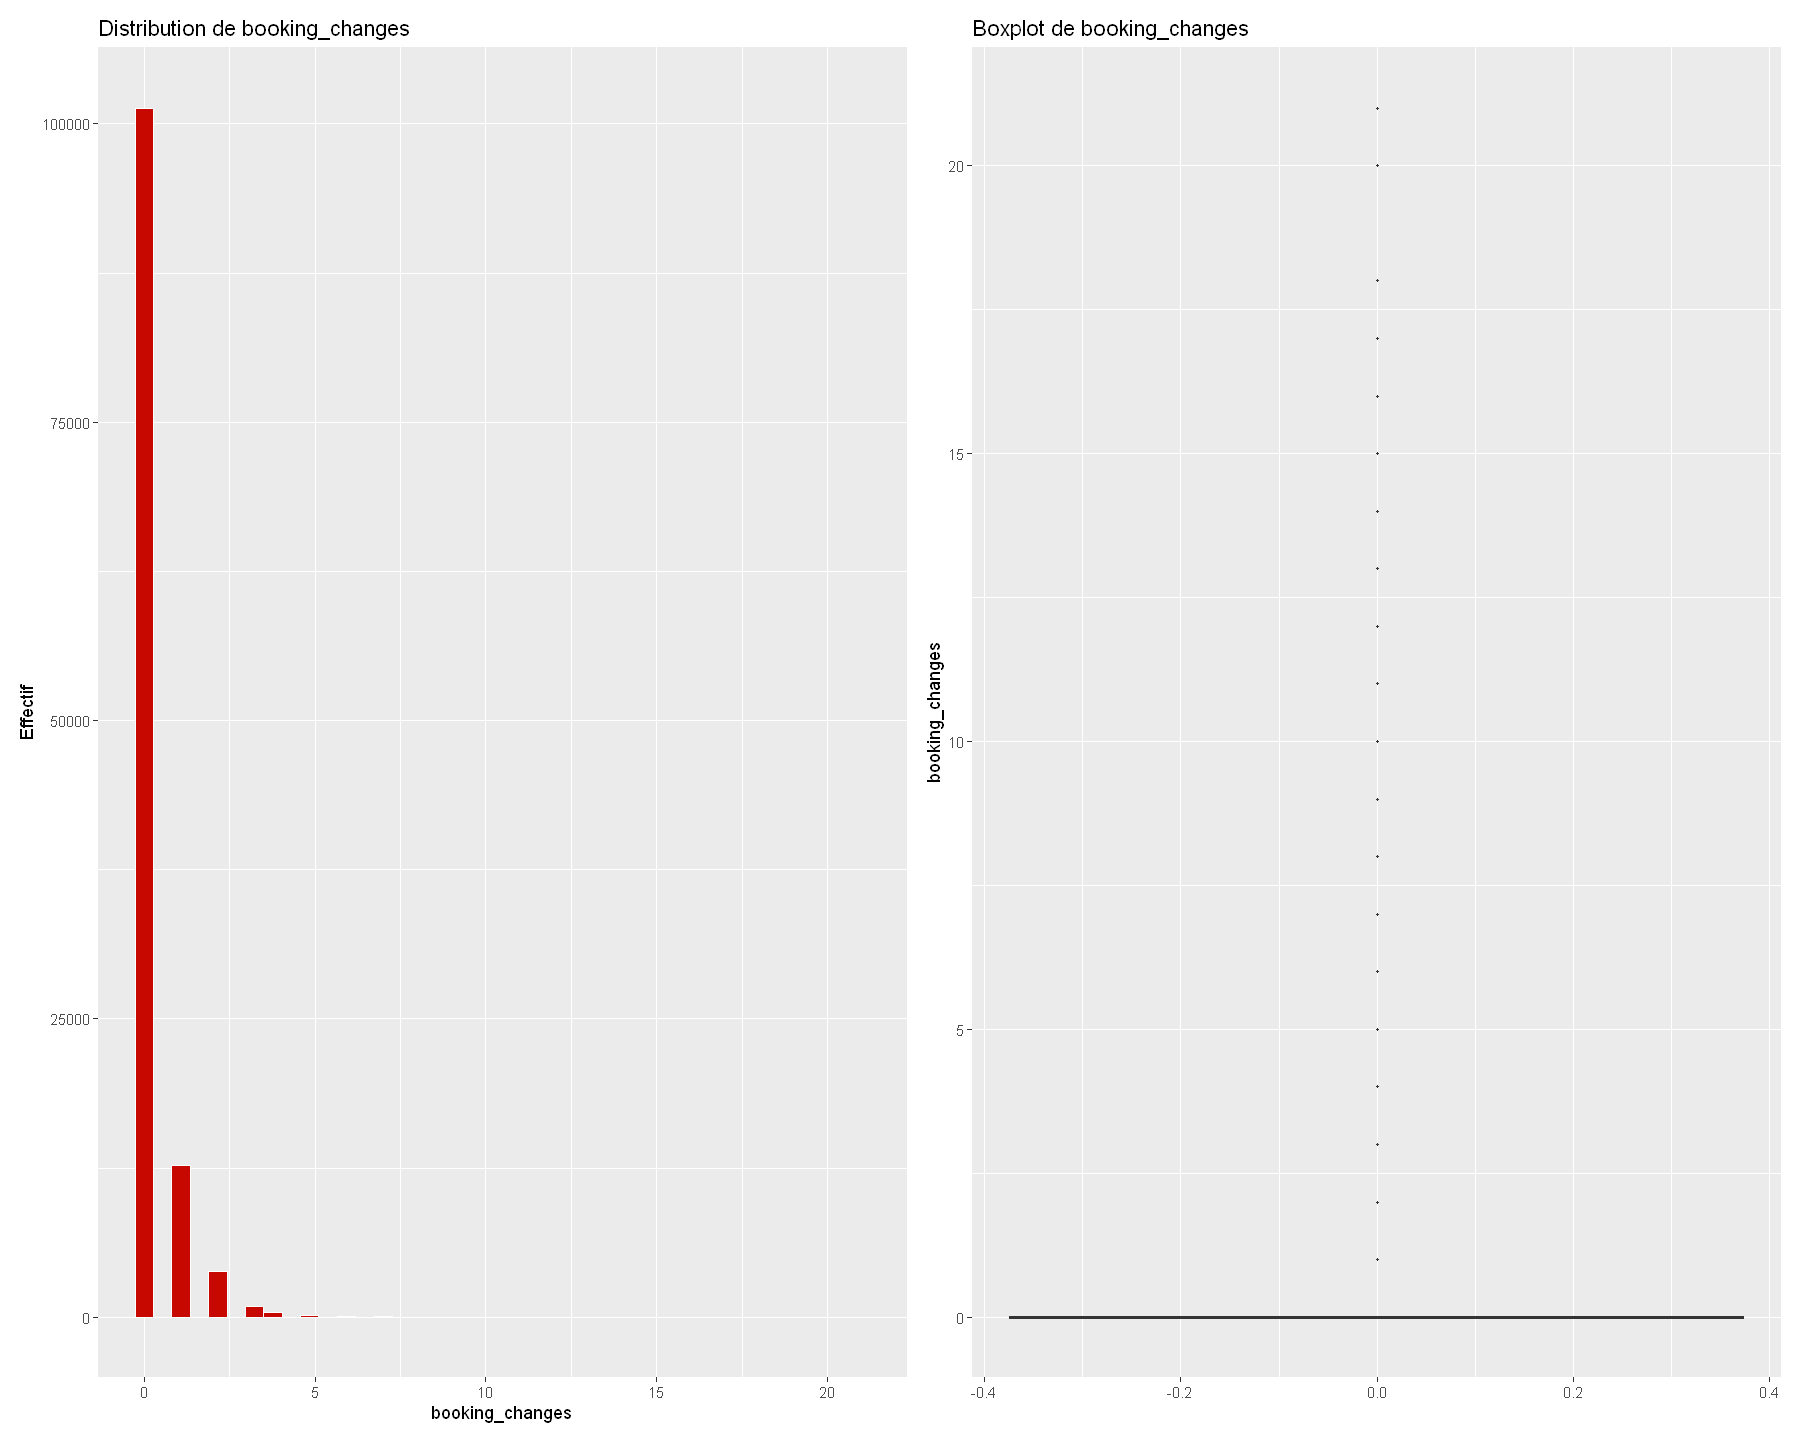

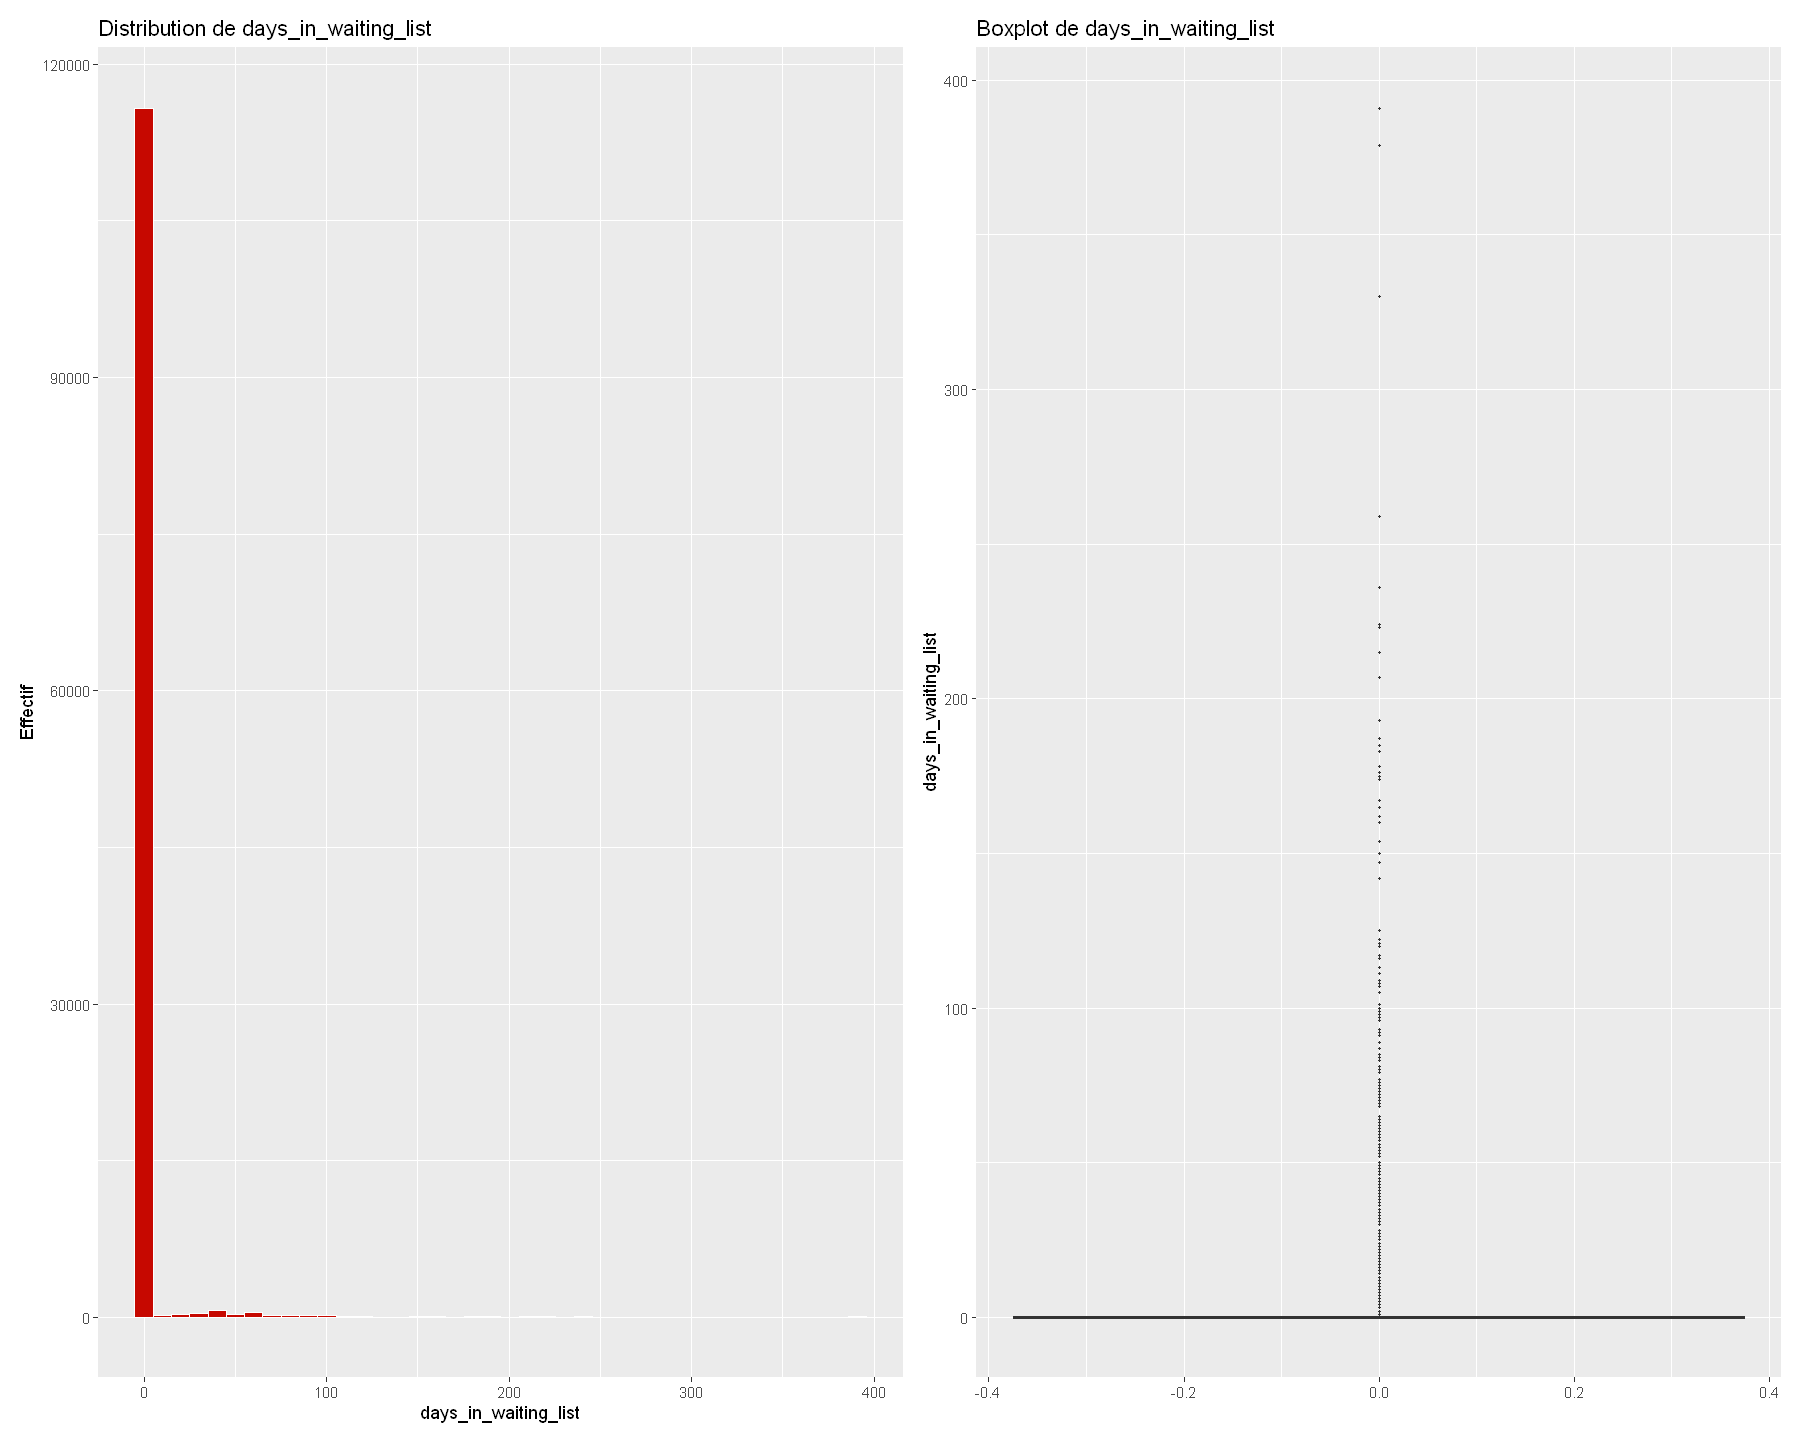

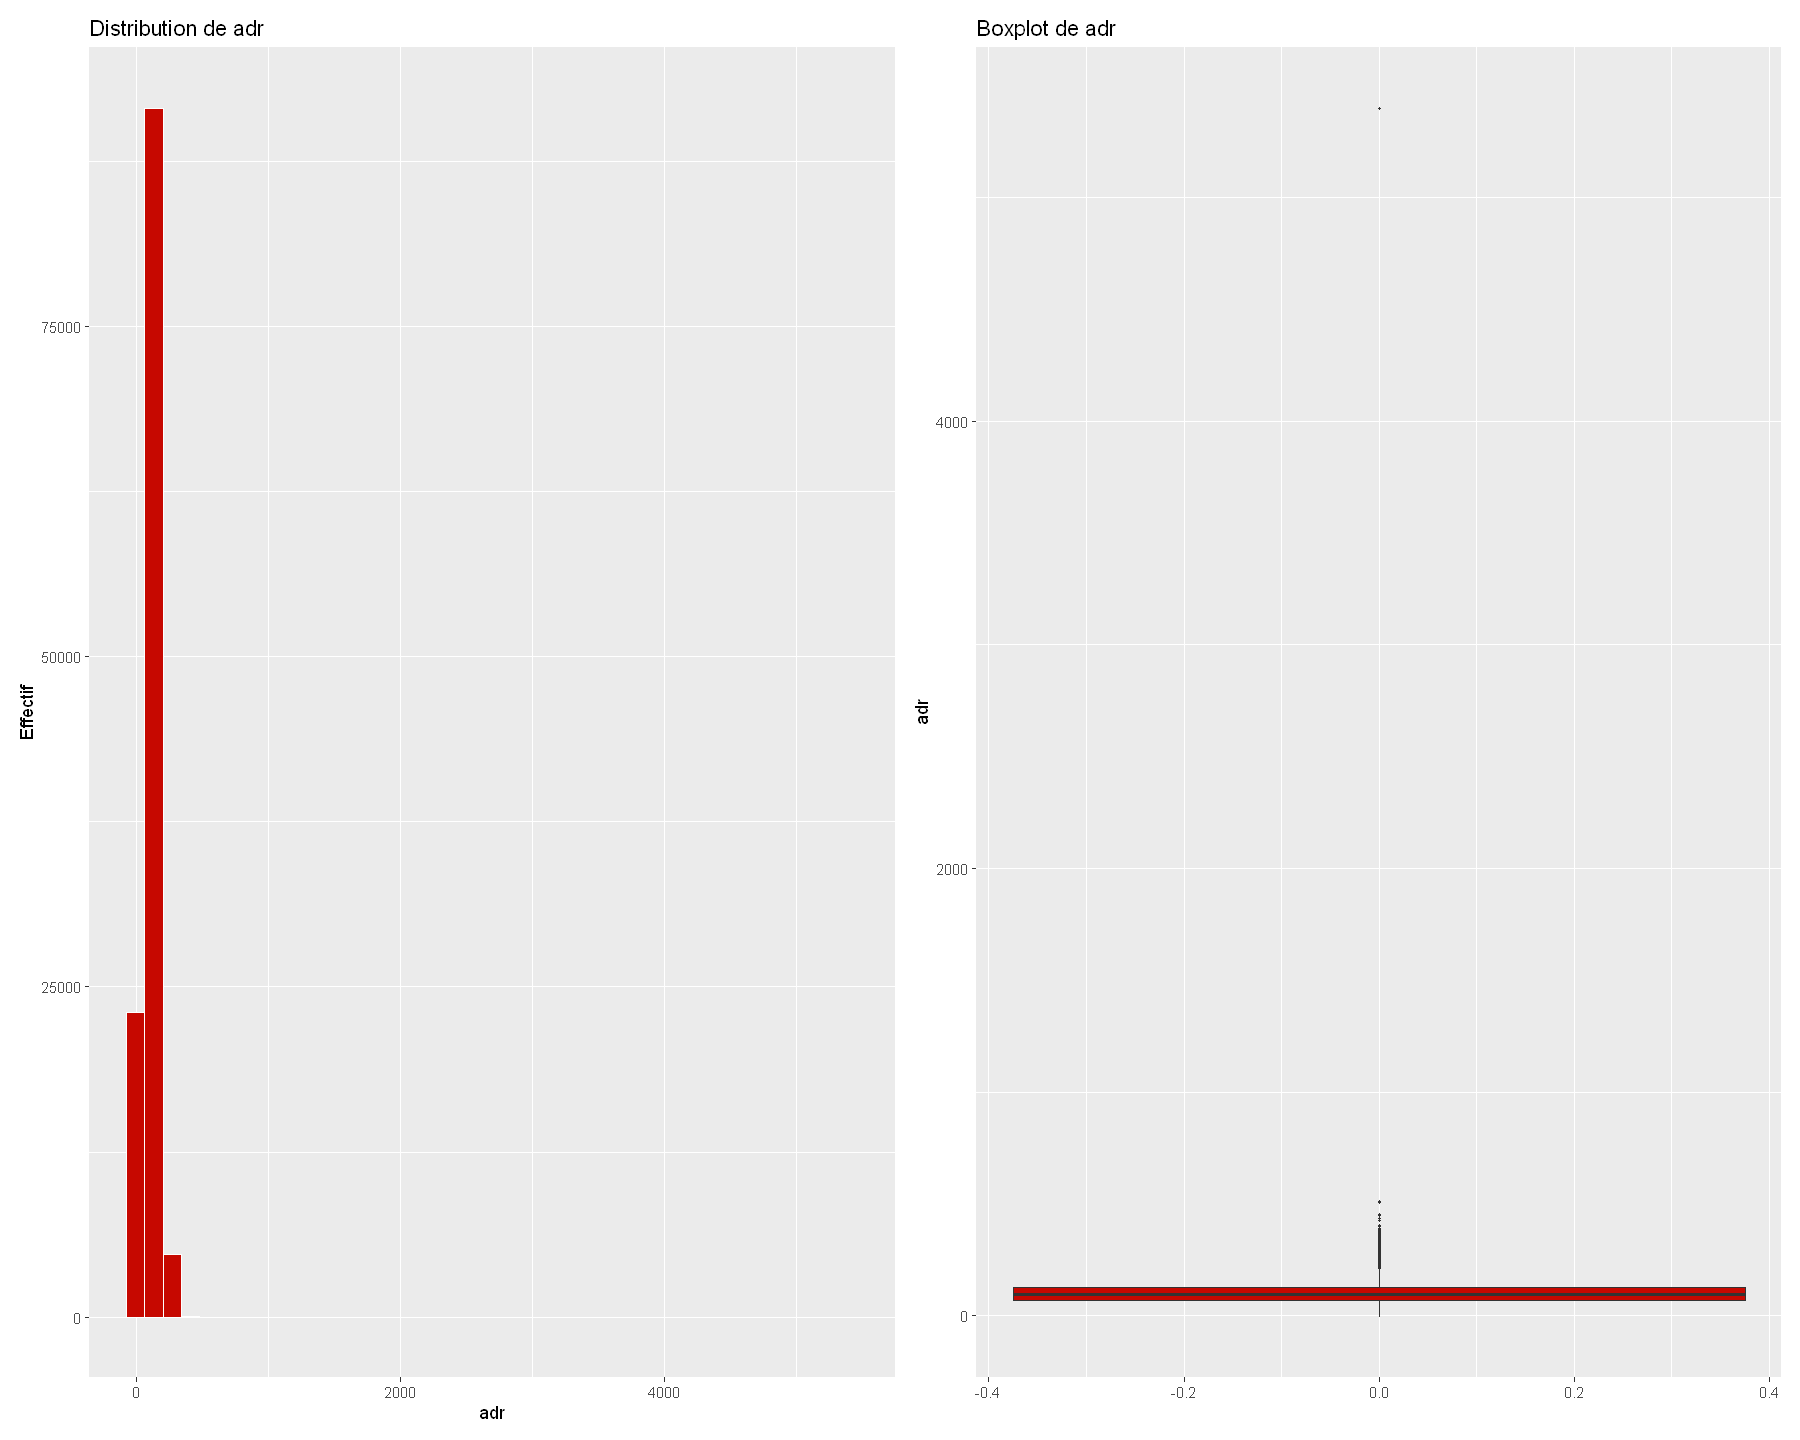

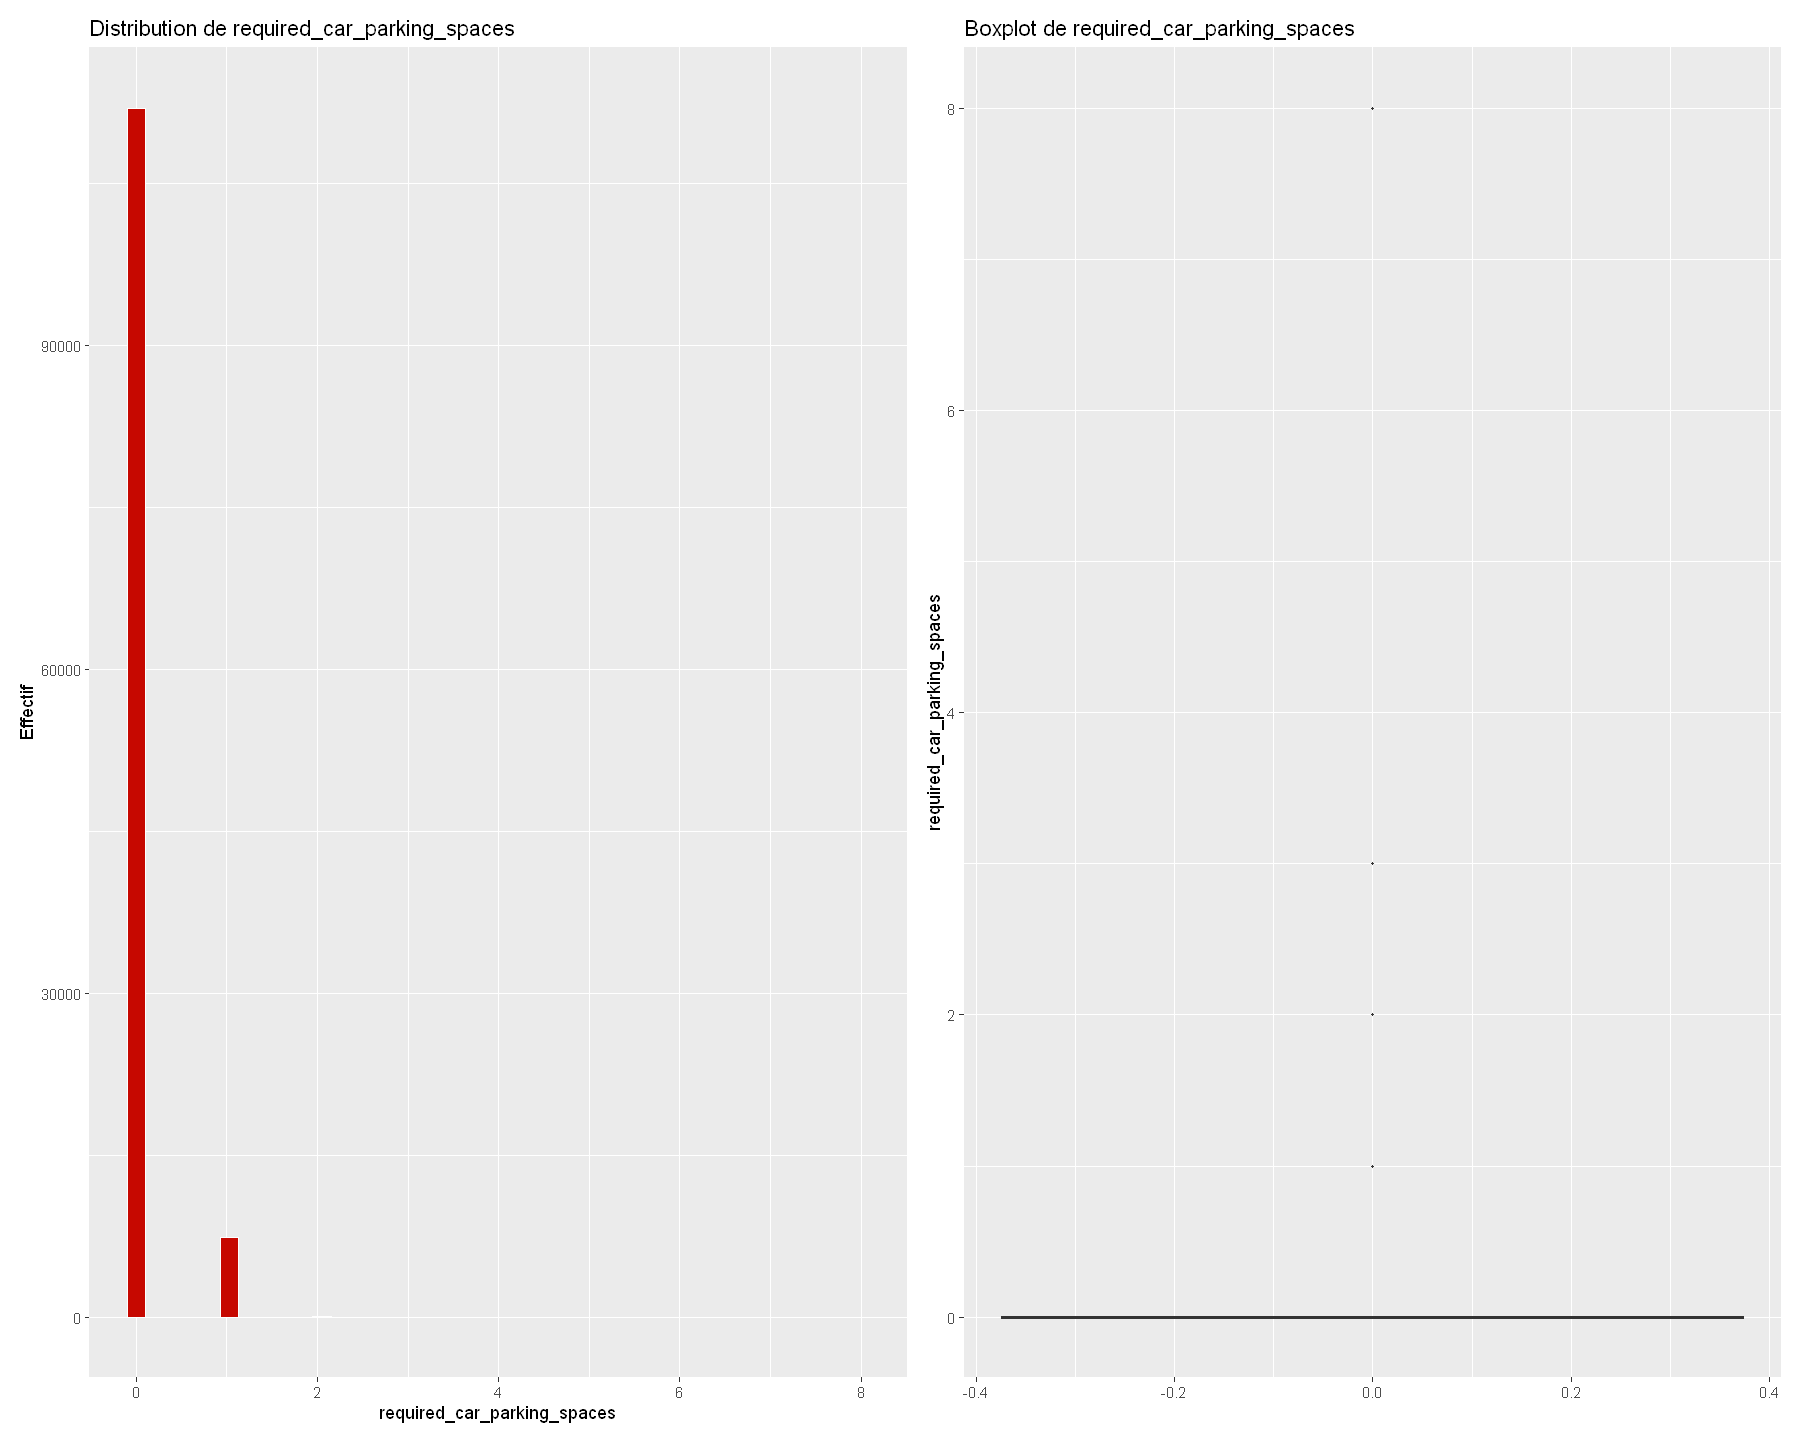

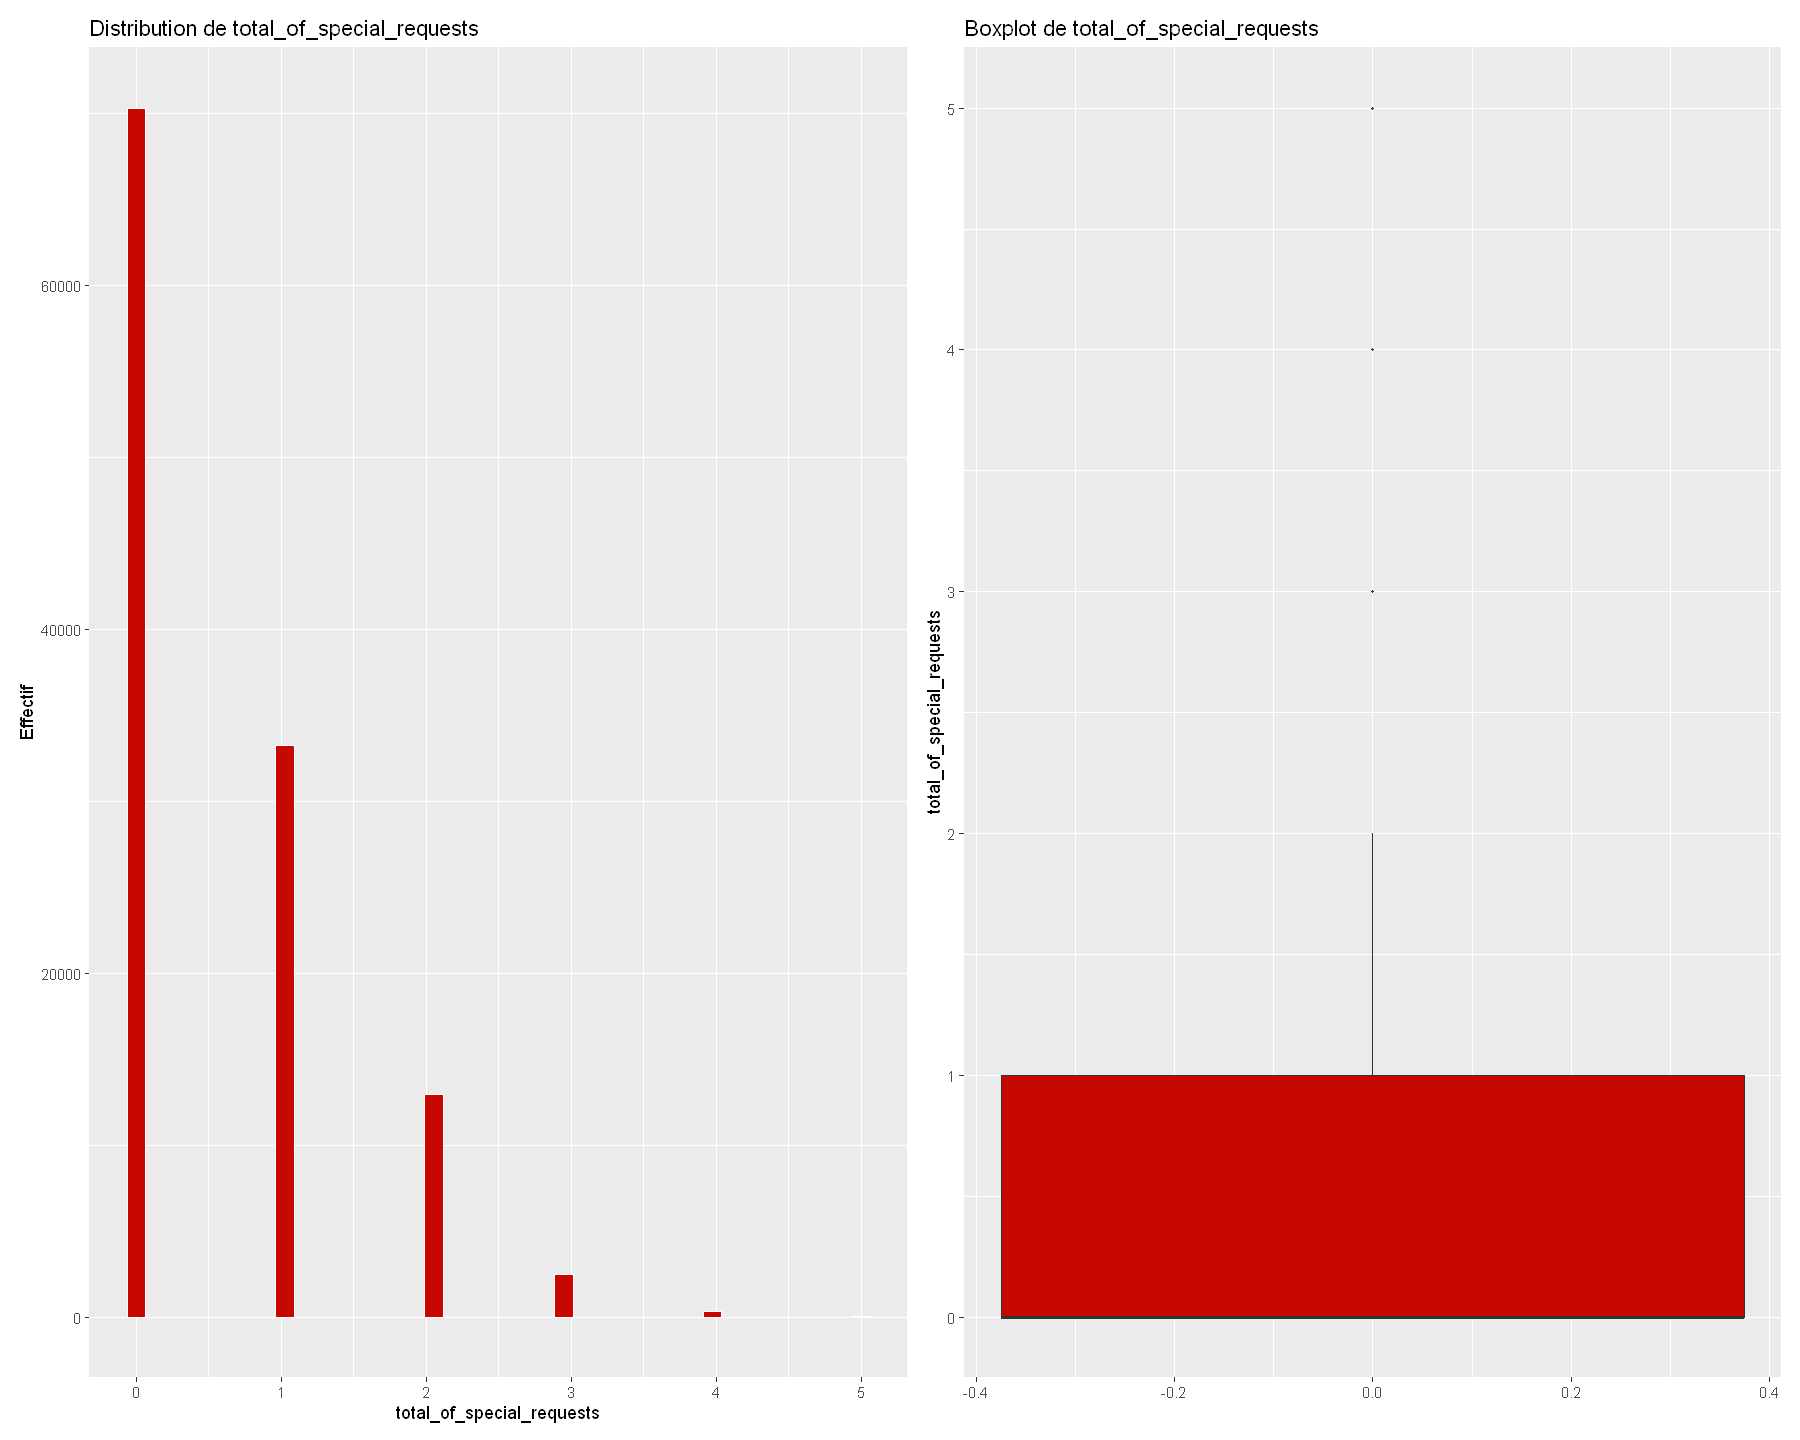

In [39]:
library(patchwork)
# ---- Quantitatives ---------------------------------------------------
# Asymétrie et aplatissement calculés à la main (pas de librairie en plus)
asymetrie <- function(x) {
  x <- x[!is.na(x)]
  mean((x - mean(x))^3) / sd(x)^3
}
aplatissement <- function(x) {
  x <- x[!is.na(x)]
  mean((x - mean(x))^4) / sd(x)^4 - 3   # 0 = aussi « pointue » qu'une normale
}

stats_univariees <- map_dfr(vars_quanti, function(v) {
  x <- hotels[[v]]
  x <- x[!is.na(x)]
  q1 <- quantile(x, 0.25); q3 <- quantile(x, 0.75); iqr <- q3 - q1
  tibble(
    variable = v,
    n = length(x),
    n_manquants = sum(is.na(hotels[[v]])),
    moyenne = mean(x), ecart_type = sd(x),
    min = min(x), q1 = q1, mediane = median(x), q3 = q3, max = max(x),
    asymetrie = asymetrie(x), aplatissement = aplatissement(x),
    n_atypiques_IQR = sum(x < q1 - 1.5 * iqr | x > q3 + 1.5 * iqr),
    pct_atypiques = round(
      mean(x < q1 - 1.5 * iqr | x > q3 + 1.5 * iqr) * 100, 2)
  )
})
print(stats_univariees, n = Inf)

for (v in vars_quanti) {
  # 1. Histogramme
  histo_quanti <- ggplot(hotels, aes(x = .data[[v]])) +
    geom_histogram(bins = 40, fill = "#C60800", color = "white") +
    labs(title = paste("Distribution de", v), x = v, y = "Effectif")
  
 

  # 2. Boxplot
  boxplot_quanti <- ggplot(hotels, aes(y = .data[[v]])) +
    geom_boxplot(fill = "#C60800", outlier.size = 0.4) +
    labs(title = paste("Boxplot de", v), y = v, x = NULL)
  
  print(histo_quanti + boxplot_quanti)
}

Variables quantitatives:

**lead_time** (délai entre réservation et arrivée) — Moyenne 104 jours, médiane 69, écart-type 107, de 0 à 737. Distribution asymétrique à droite : la moitié des clients réserve moins de ~2 mois à l'avance, un quart plus de 160 jours, et une minorité réserve plus d'un an à l'avance. 5,3 % réservent le jour même. C'est la variable continue la plus dispersée du fichier : elle distingue de vrais comportements différents, pas du bruit.

**arrival_date_year** — 2015, 2016, 2017, avec 2016 comme année médiane : la couverture n'est pas uniforme (2015 commence en juillet, 2017 s'arrête en août), donc les volumes annuels ne se comparent pas directement.

**arrival_date_week_number** — De 1 à 53, médiane 28, distribution à peu près symétrique : les arrivées couvrent toute l'année sans trou, le léger pic central correspond à l'été.

**arrival_date_day_of_month** — De 1 à 31, médiane 16, symétrique : aucune concentration en début ou fin de mois, le jour d'arrivée dans le mois est sans structure particulière.

**stays_in_weekend_nights** — Moyenne 0,93, médiane 1 ; 43,6 % des séjours n'ont aucune nuit de week-end. La clientèle n'est donc pas qu'une clientèle de week-end et de loisirs.

**stays_in_week_nights** — Moyenne 2,50, médiane 2 : le cœur du séjour est en semaine. Maximum de 50 nuits, très atypique (2,8 % de valeurs IQR-atypiques, tirées par de longs séjours).

**total_nights** — Médiane 3, moyenne 3,43, 75 % des séjours durent 4 nuits ou moins : le produit vendu est le court séjour. Le maximum de 69 nuits et l'asymétrie (3,31) viennent d'une poignée de très longs séjours.

**adults** — Médiane et mode à 2, moyenne 1,86 : la réservation type est un couple. Le minimum de 0 et le maximum de 55 sont des anomalies à signaler (les 24,9 % de « valeurs atypiques » IQR sont un artefact : la variable est concentrée sur 1-2, donc tout le reste ressort comme extrême — à ne pas interpréter comme des erreurs en masse).

**children** — Zéro dans 92,8 % des cas, moyenne 0,10 : les enfants sont rares. Le maximum de 10 est suspect. C'est aussi la seule variable avec de vraies valeurs manquantes (4).

**babies** — Zéro dans 99,2 % des cas, moyenne 0,008 : les bébés sont quasi absents ; la variable n'apporte presque aucune information en l'état.

**total_guests** — Médiane 2, moyenne 1,97 : elle confirme le portrait du couple voyageant seul ; son maximum de 55 hérite de l'anomalie d'adults.

**previous_cancellations** — Zéro dans 94,6 % des cas, moyenne 0,09, maximum 26 : presque aucun client n'a d'historique d'annulation connu ; les quelques valeurs élevées désignent une toute petite minorité de clients « annuleurs en série ».

**previous_bookings_not_canceled** — Zéro dans 97 % des cas, moyenne 0,14 : la fidélité mesurée par l'historique est presque inexistante dans ce fichier ; maximum 72 pour un client exceptionnel.

**booking_changes** — Zéro dans 84,9 % des cas, moyenne 0,22 : la plupart des réservations ne sont jamais modifiées ; les modifications restent un comportement minoritaire (maximum 21).

**days_in_waiting_list** — Zéro dans 96,9 % des cas, moyenne 2,32, mais maximum 391 : la liste d'attente est un phénomène rare, sauf quelques dossiers restés bloqués plus d'un an, probablement des cas particuliers.

**adr (prix moyen par nuit)** — Médiane 94,58, moyenne 101,83, écart-type 50,5 : un positionnement milieu de gamme, entre 69 (Q1) et 126 (Q3). Mais distribution la plus déformée du fichier (asymétrie 10,5) : un minimum de −6,38, impossible pour un prix, 1,64 % de zéros (offerts ?) et un maximum de 5 400, manifestement une erreur de saisie. La médiane est l'indicateur fiable ; la moyenne est contaminée.

**required_car_parking_spaces** — Zéro dans 93,8 % des cas : le parking ne concerne que 6,2 % des réservations, cohérent avec une clientèle urbaine et d'agences.

**total_of_special_requests** — De 0 à 5, moyenne 0,57 ; 41,1 % des réservations ont au moins une demande spéciale. C'est, parmi les variables « comportement », la plus fréquente : les clients s'expriment, mais restent sobres (rarement plus d'une demande).


=== SYNTHÈSE DES VARIABLES QUALITATIVES ===
# A tibble: 17 × 5
   variable             n_modalites n_manquants mode       pct_mode
   <chr>                      <int>       <int> <chr>         <dbl>
 1 hotel                          2           0 City Hotel     66.4
 2 arrival_date_year              3           0 2016           47.5
 3 arrival_date_month            12           0 August         11.6
 4 saison                         4           0 Été            31.4
 5 meal                           5           0 BB             77.3
 6 country_group                 21           0 PRT            40.7
 7 market_segment                 8           0 Online TA      47.3
 8 distribution_channel           5           0 TA/TO          82.0
 9 is_repeated_guest              2           0 Non            96.8
10 reserved_room_type            10           0 A              72.0
11 assigned_room_type            12           0 A              62.0
12 room_changed                   2           0 Non 

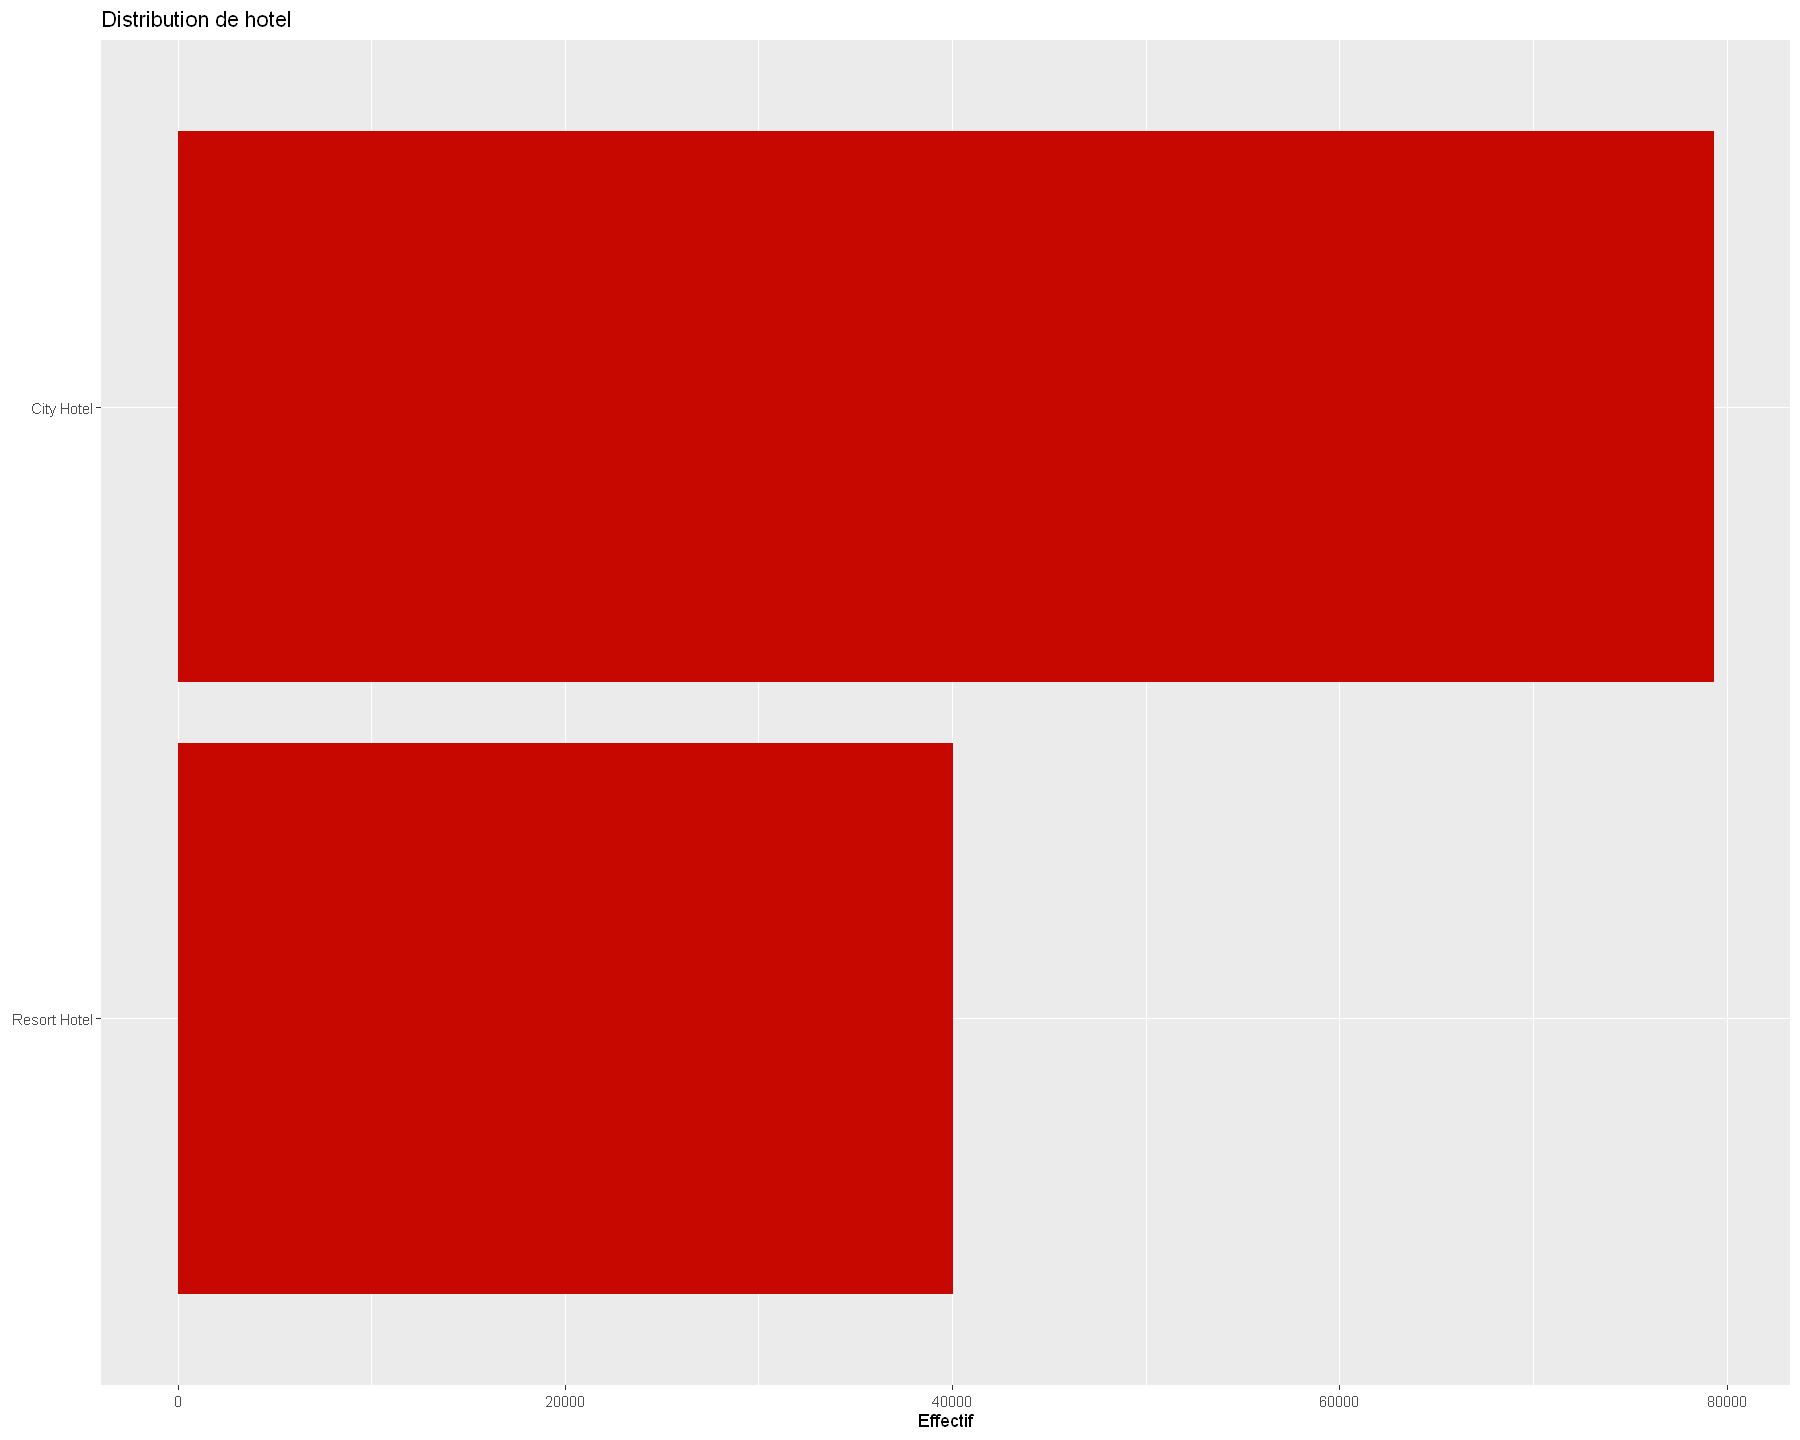


----------------------------------------
Variable : arrival_date_month 
----------------------------------------
# A tibble: 12 × 3
   modalite  effectif pourcentage
   <ord>        <int>       <dbl>
 1 August       13877       11.6 
 2 July         12661       10.6 
 3 May          11791        9.88
 4 October      11160        9.35
 5 April        11089        9.29
 6 June         10939        9.16
 7 September    10508        8.8 
 8 March         9794        8.2 
 9 February      8068        6.76
10 November      6794        5.69
11 December      6780        5.68
12 January       5929        4.97


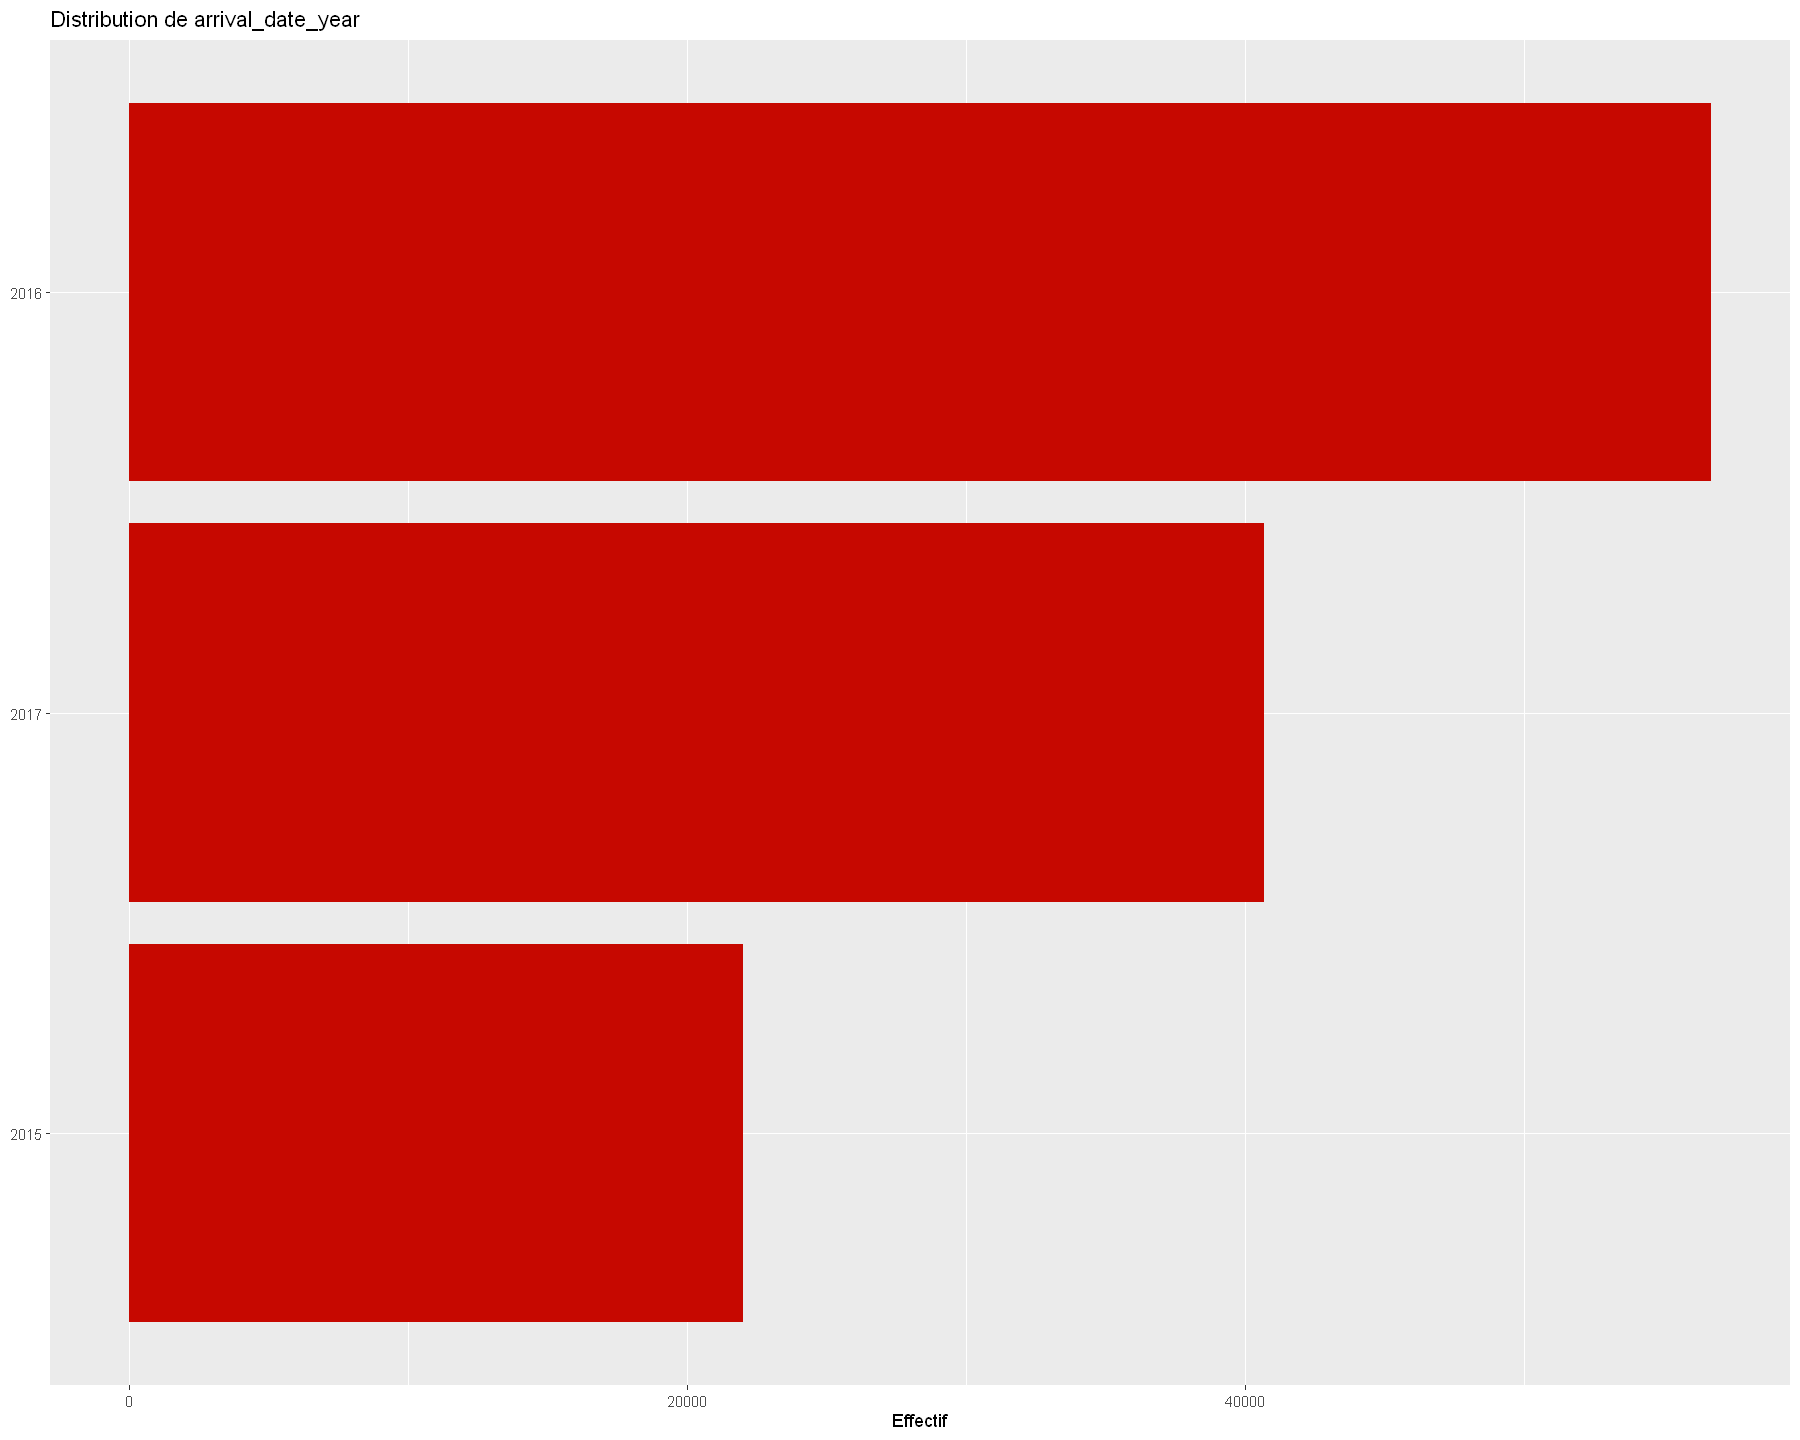


----------------------------------------
Variable : saison 
----------------------------------------
# A tibble: 4 × 3
  modalite  effectif pourcentage
  <ord>        <int>       <dbl>
1 Été          37477        31.4
2 Printemps    32674        27.4
3 Automne      28462        23.8
4 Hiver        20777        17.4


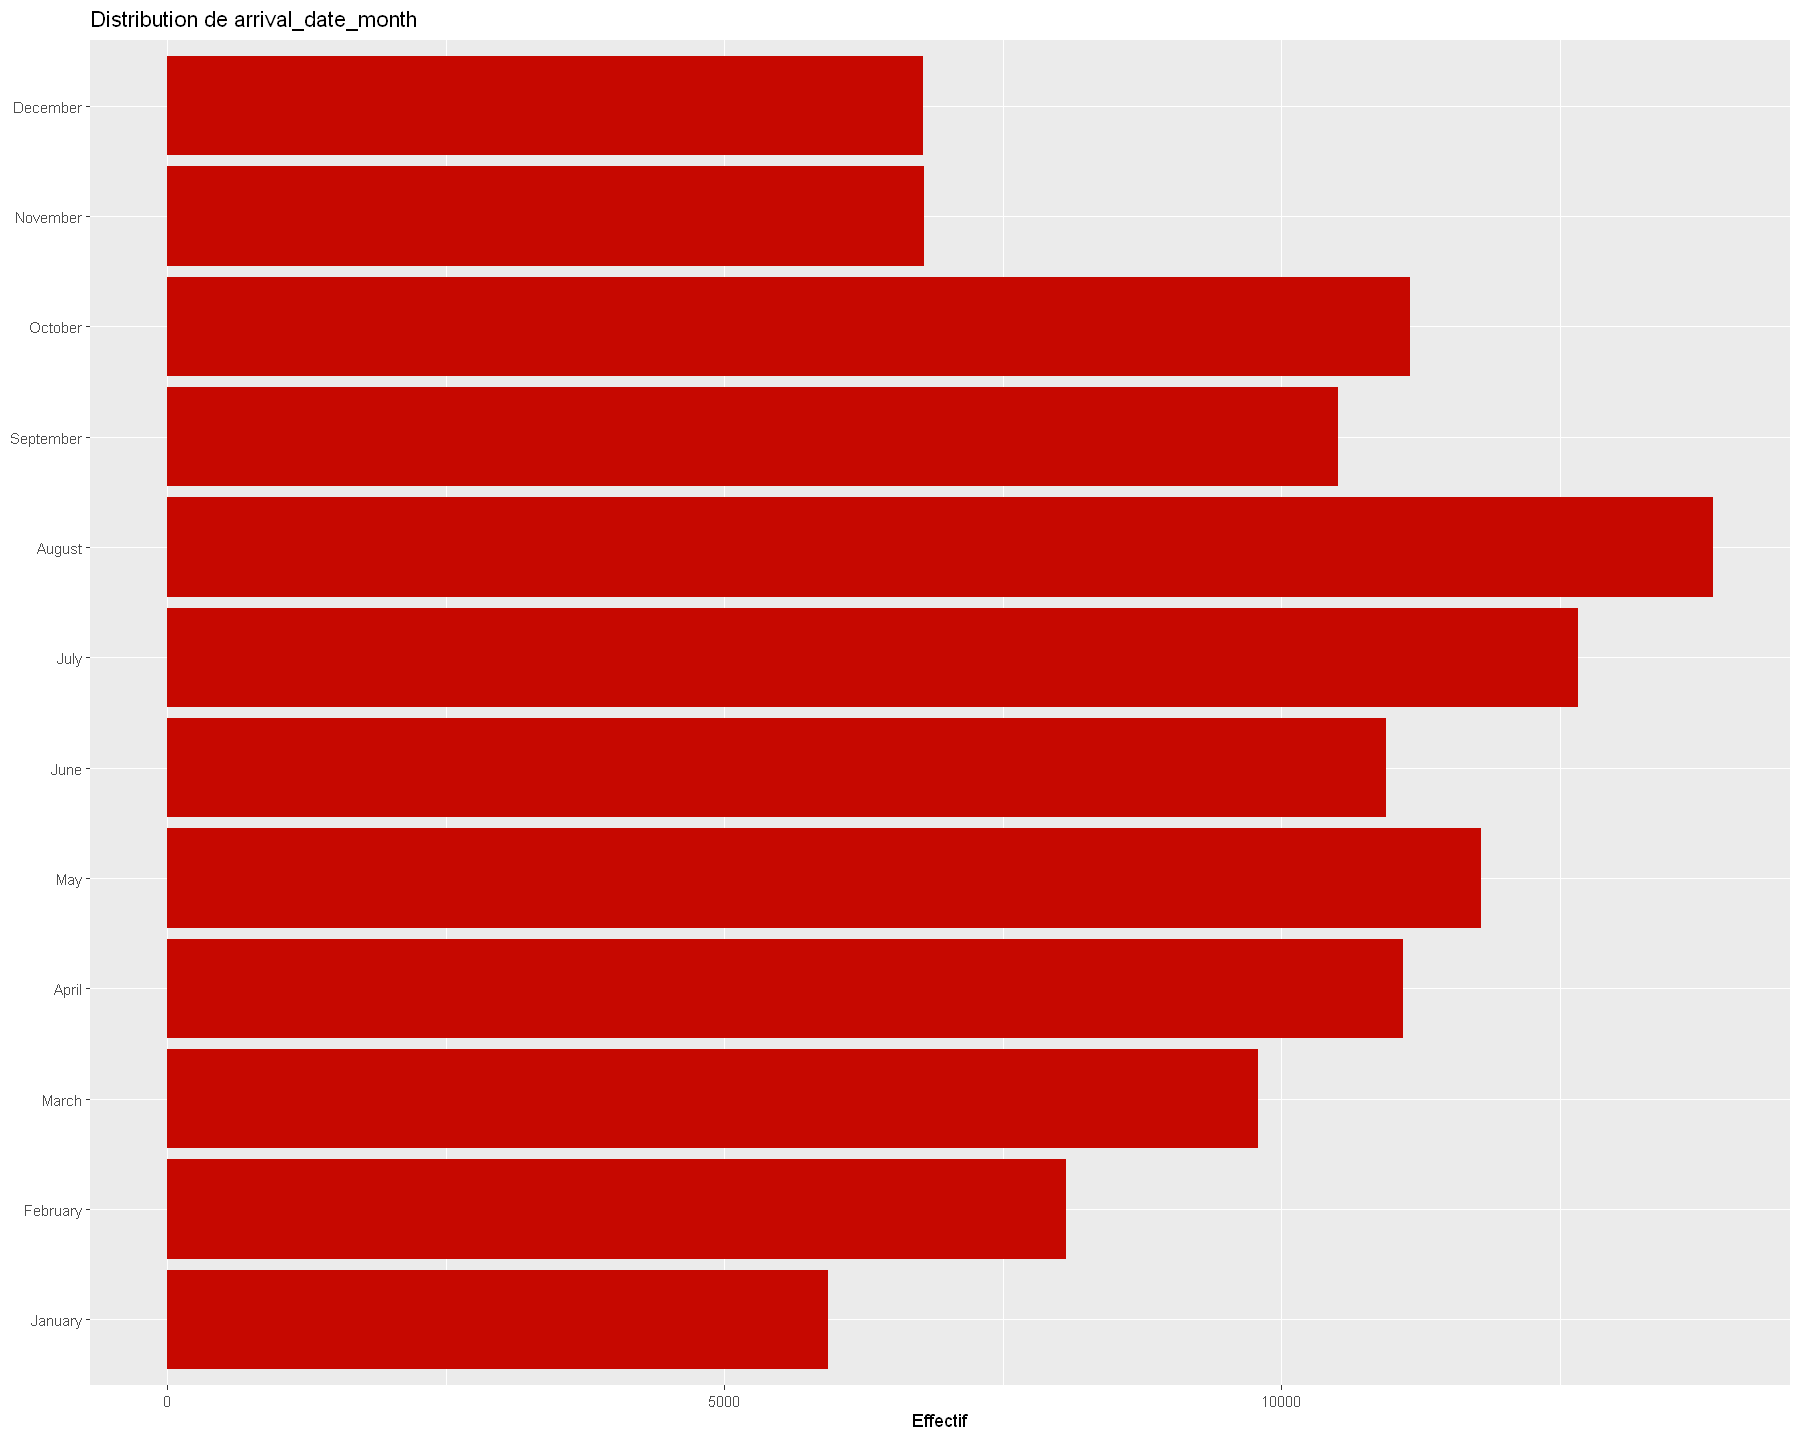


----------------------------------------
Variable : meal 
----------------------------------------
# A tibble: 5 × 3
  modalite  effectif pourcentage
  <chr>        <int>       <dbl>
1 BB           92310       77.3 
2 HB           14463       12.1 
3 SC           10650        8.92
4 Undefined     1169        0.98
5 FB             798        0.67


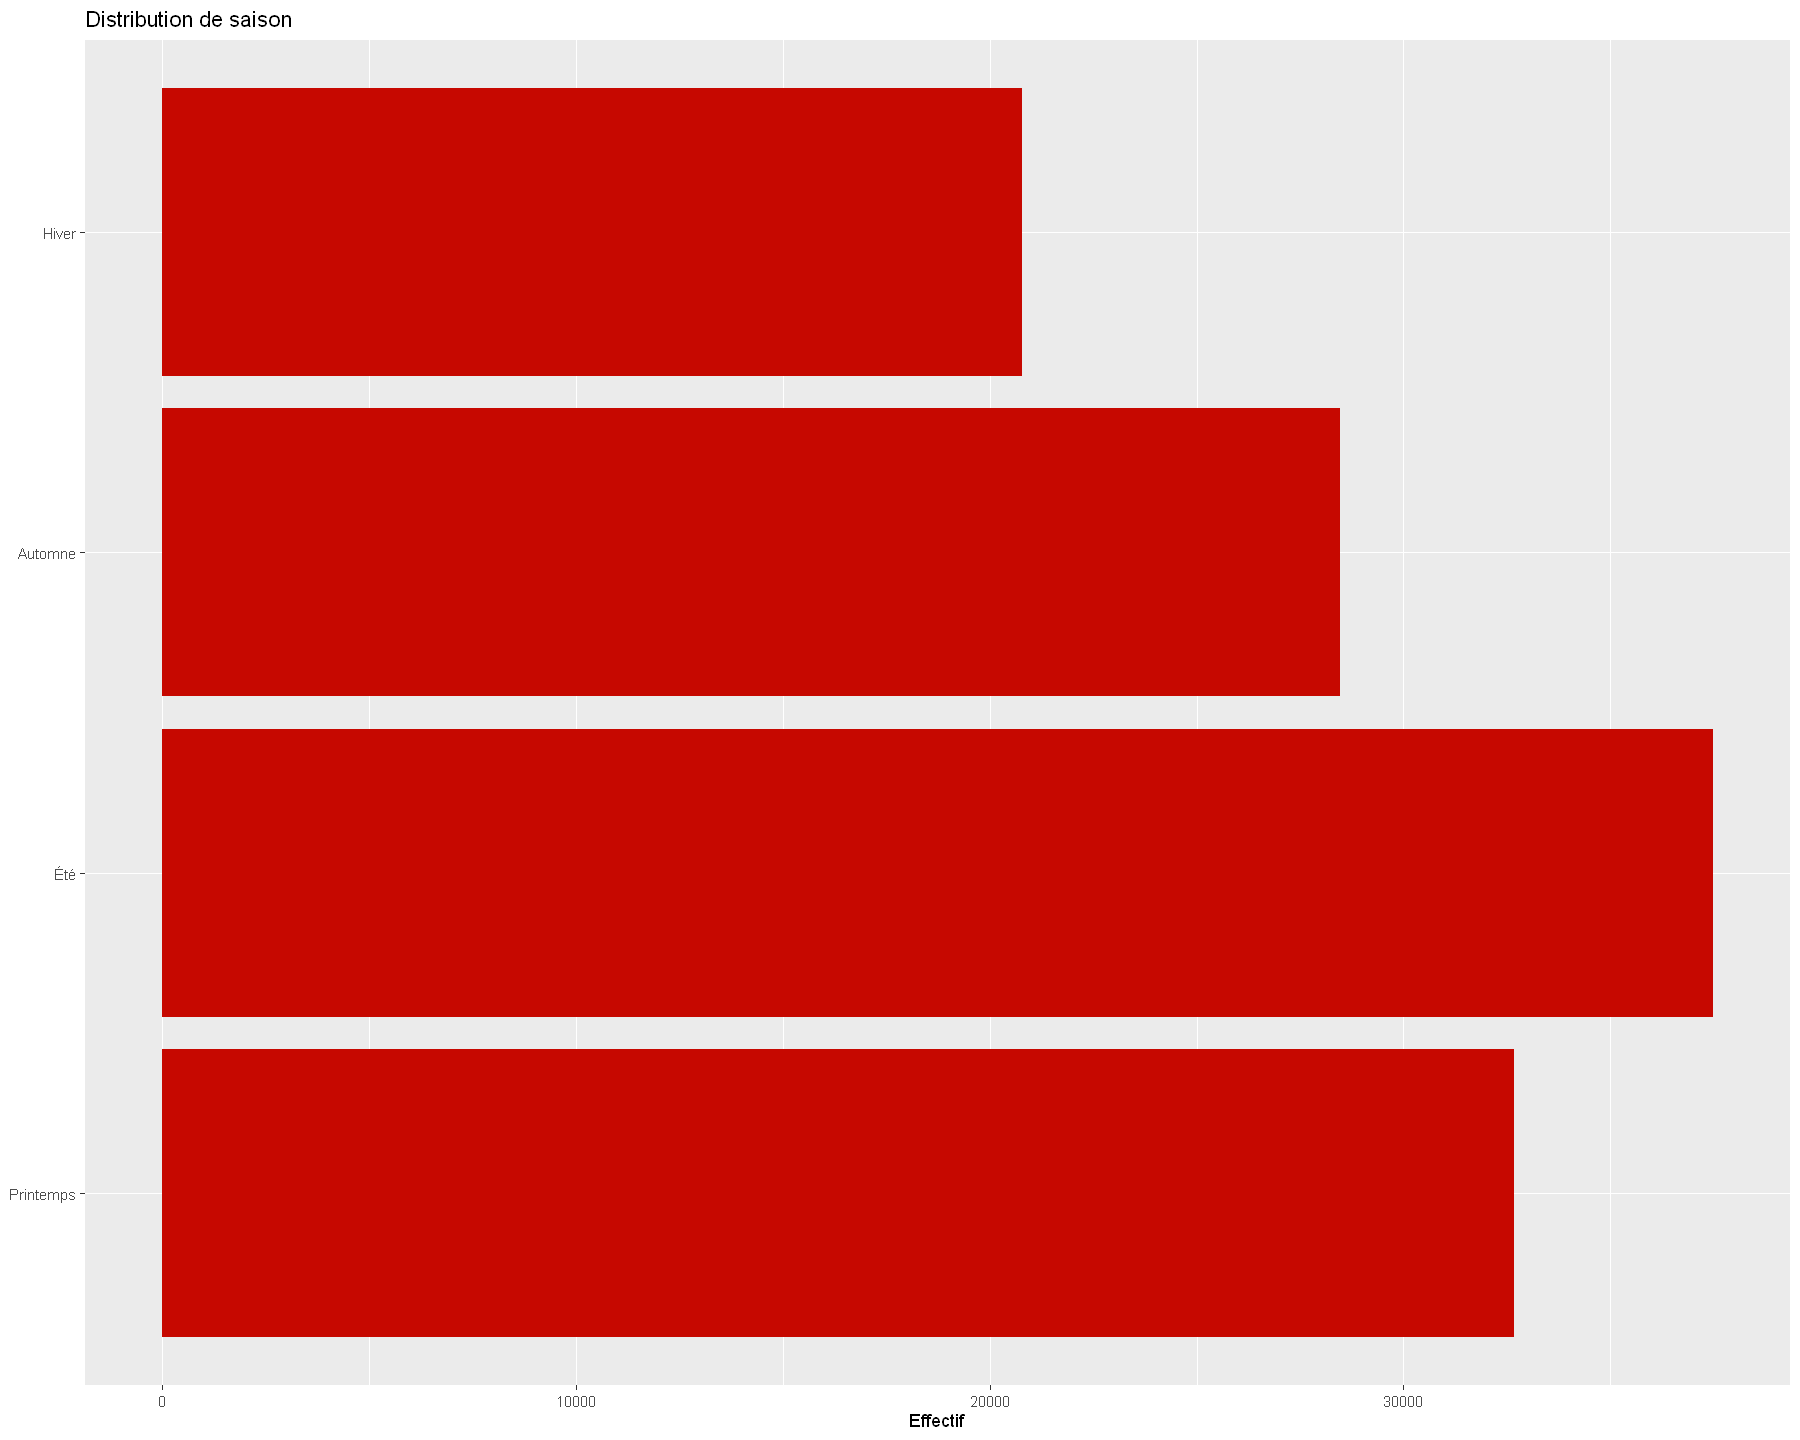


----------------------------------------
Variable : country_group 
----------------------------------------
# A tibble: 21 × 3
   modalite effectif pourcentage
   <chr>       <int>       <dbl>
 1 PRT         48590       40.7 
 2 GBR         12129       10.2 
 3 FRA         10415        8.72
 4 ESP          8568        7.18
 5 Other        7371        6.17
 6 DEU          7287        6.1 
 7 ITA          3766        3.15
 8 IRL          3375        2.83
 9 BEL          2342        1.96
10 BRA          2224        1.86
11 NLD          2104        1.76
12 USA          2097        1.76
13 CHE          1730        1.45
14 CN           1279        1.07
15 AUT          1263        1.06
16 SWE          1024        0.86
17 CHN           999        0.84
18 POL           919        0.77
19 ISR           669        0.56
20 RUS           632        0.53
21 NOR           607        0.51


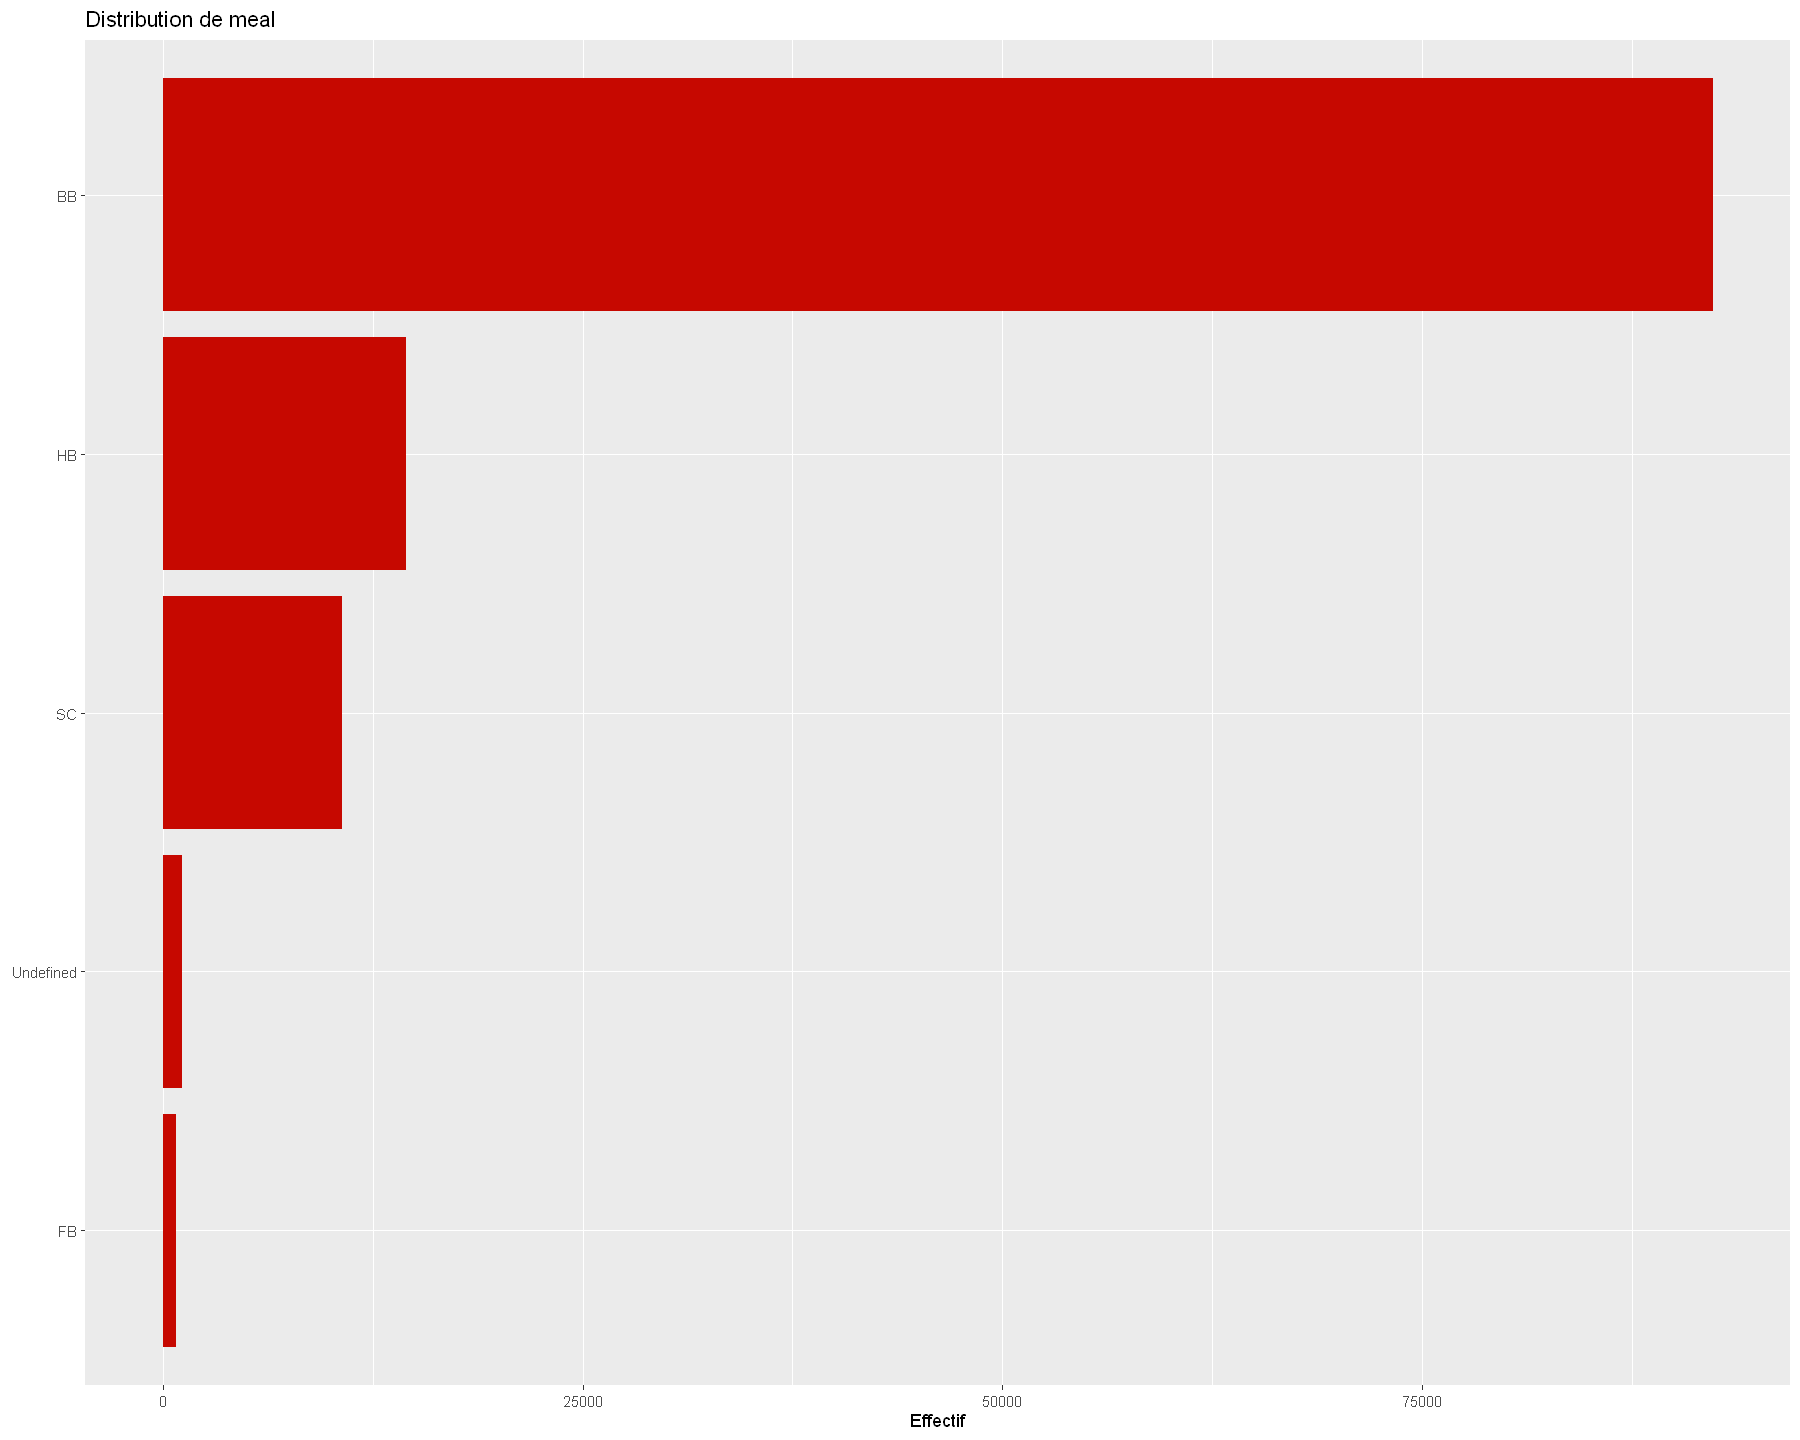


----------------------------------------
Variable : market_segment 
----------------------------------------
# A tibble: 8 × 3
  modalite      effectif pourcentage
  <chr>            <int>       <dbl>
1 Online TA        56477       47.3 
2 Offline TA/TO    24219       20.3 
3 Groups           19811       16.6 
4 Direct           12606       10.6 
5 Corporate         5295        4.44
6 Complementary      743        0.62
7 Aviation           237        0.2 
8 Undefined            2        0   


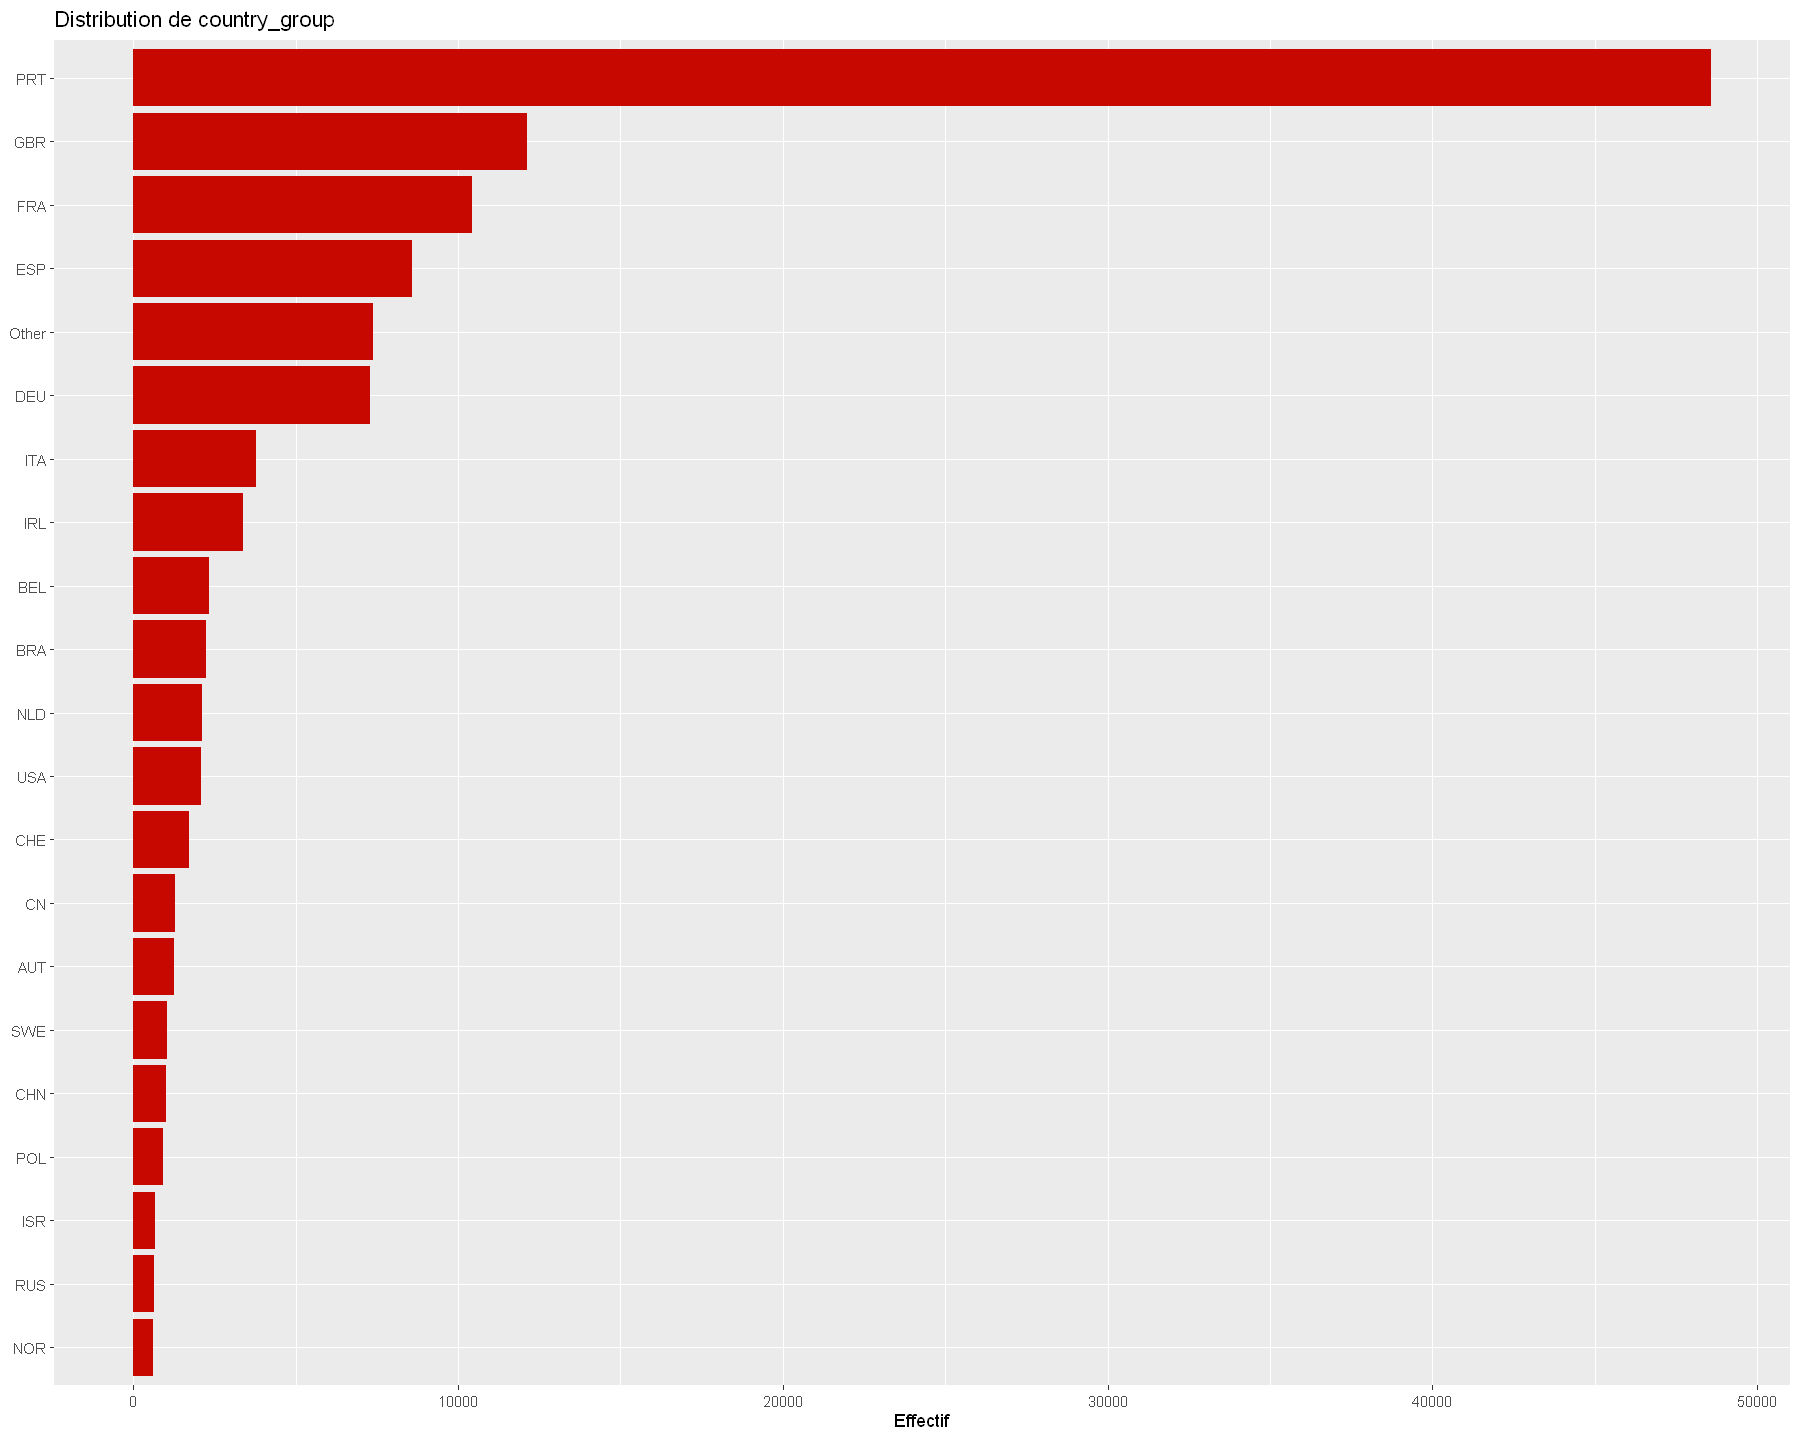


----------------------------------------
Variable : distribution_channel 
----------------------------------------
# A tibble: 5 × 3
  modalite  effectif pourcentage
  <chr>        <int>       <dbl>
1 TA/TO        97870       82.0 
2 Direct       14645       12.3 
3 Corporate     6677        5.59
4 GDS            193        0.16
5 Undefined        5        0   


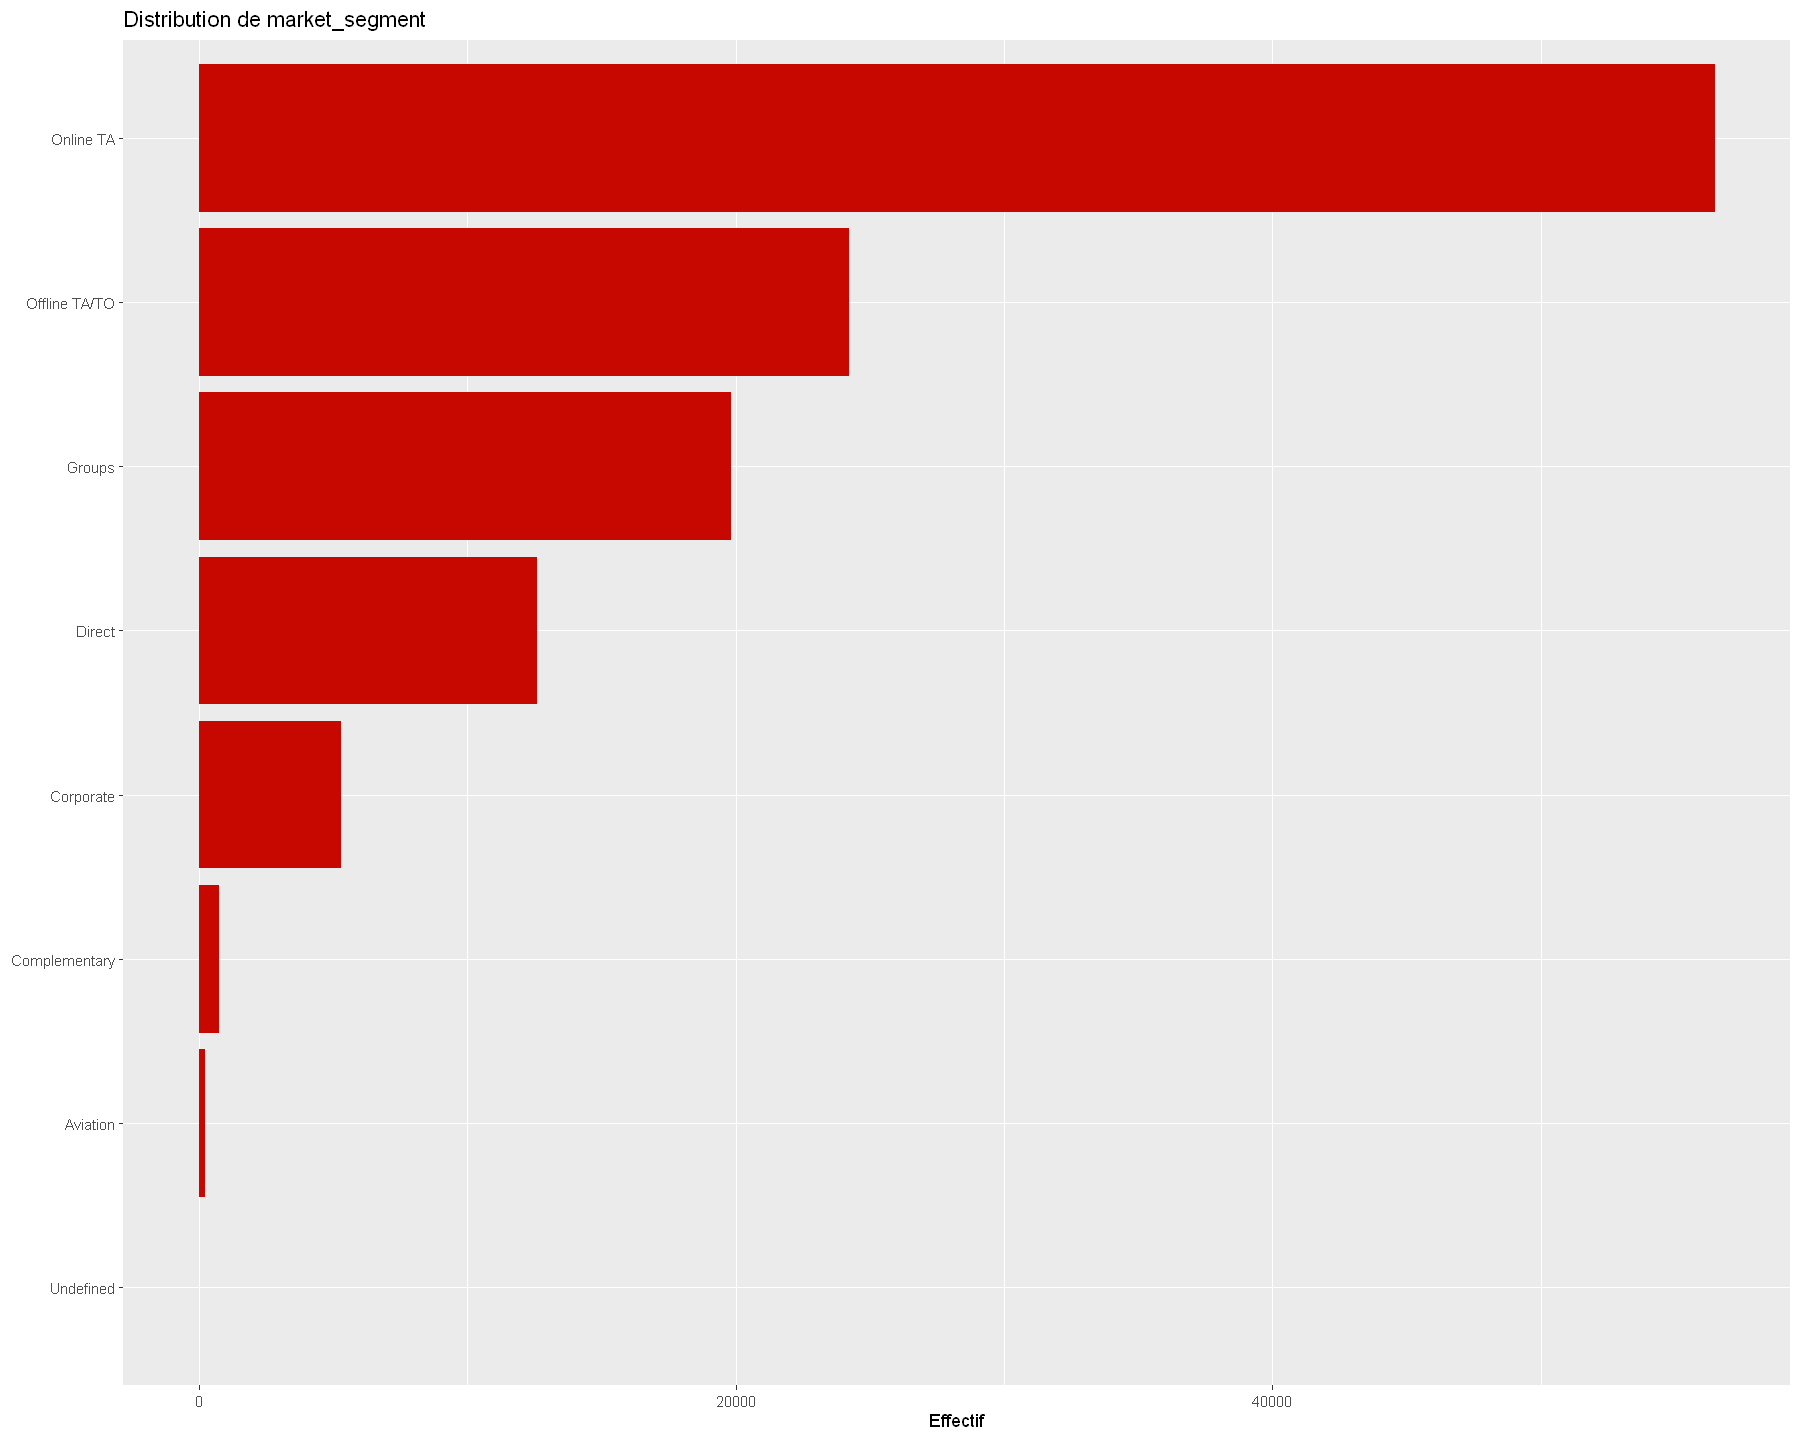


----------------------------------------
Variable : is_repeated_guest 
----------------------------------------
# A tibble: 2 × 3
  modalite effectif pourcentage
  <fct>       <int>       <dbl>
1 Non        115580       96.8 
2 Oui          3810        3.19


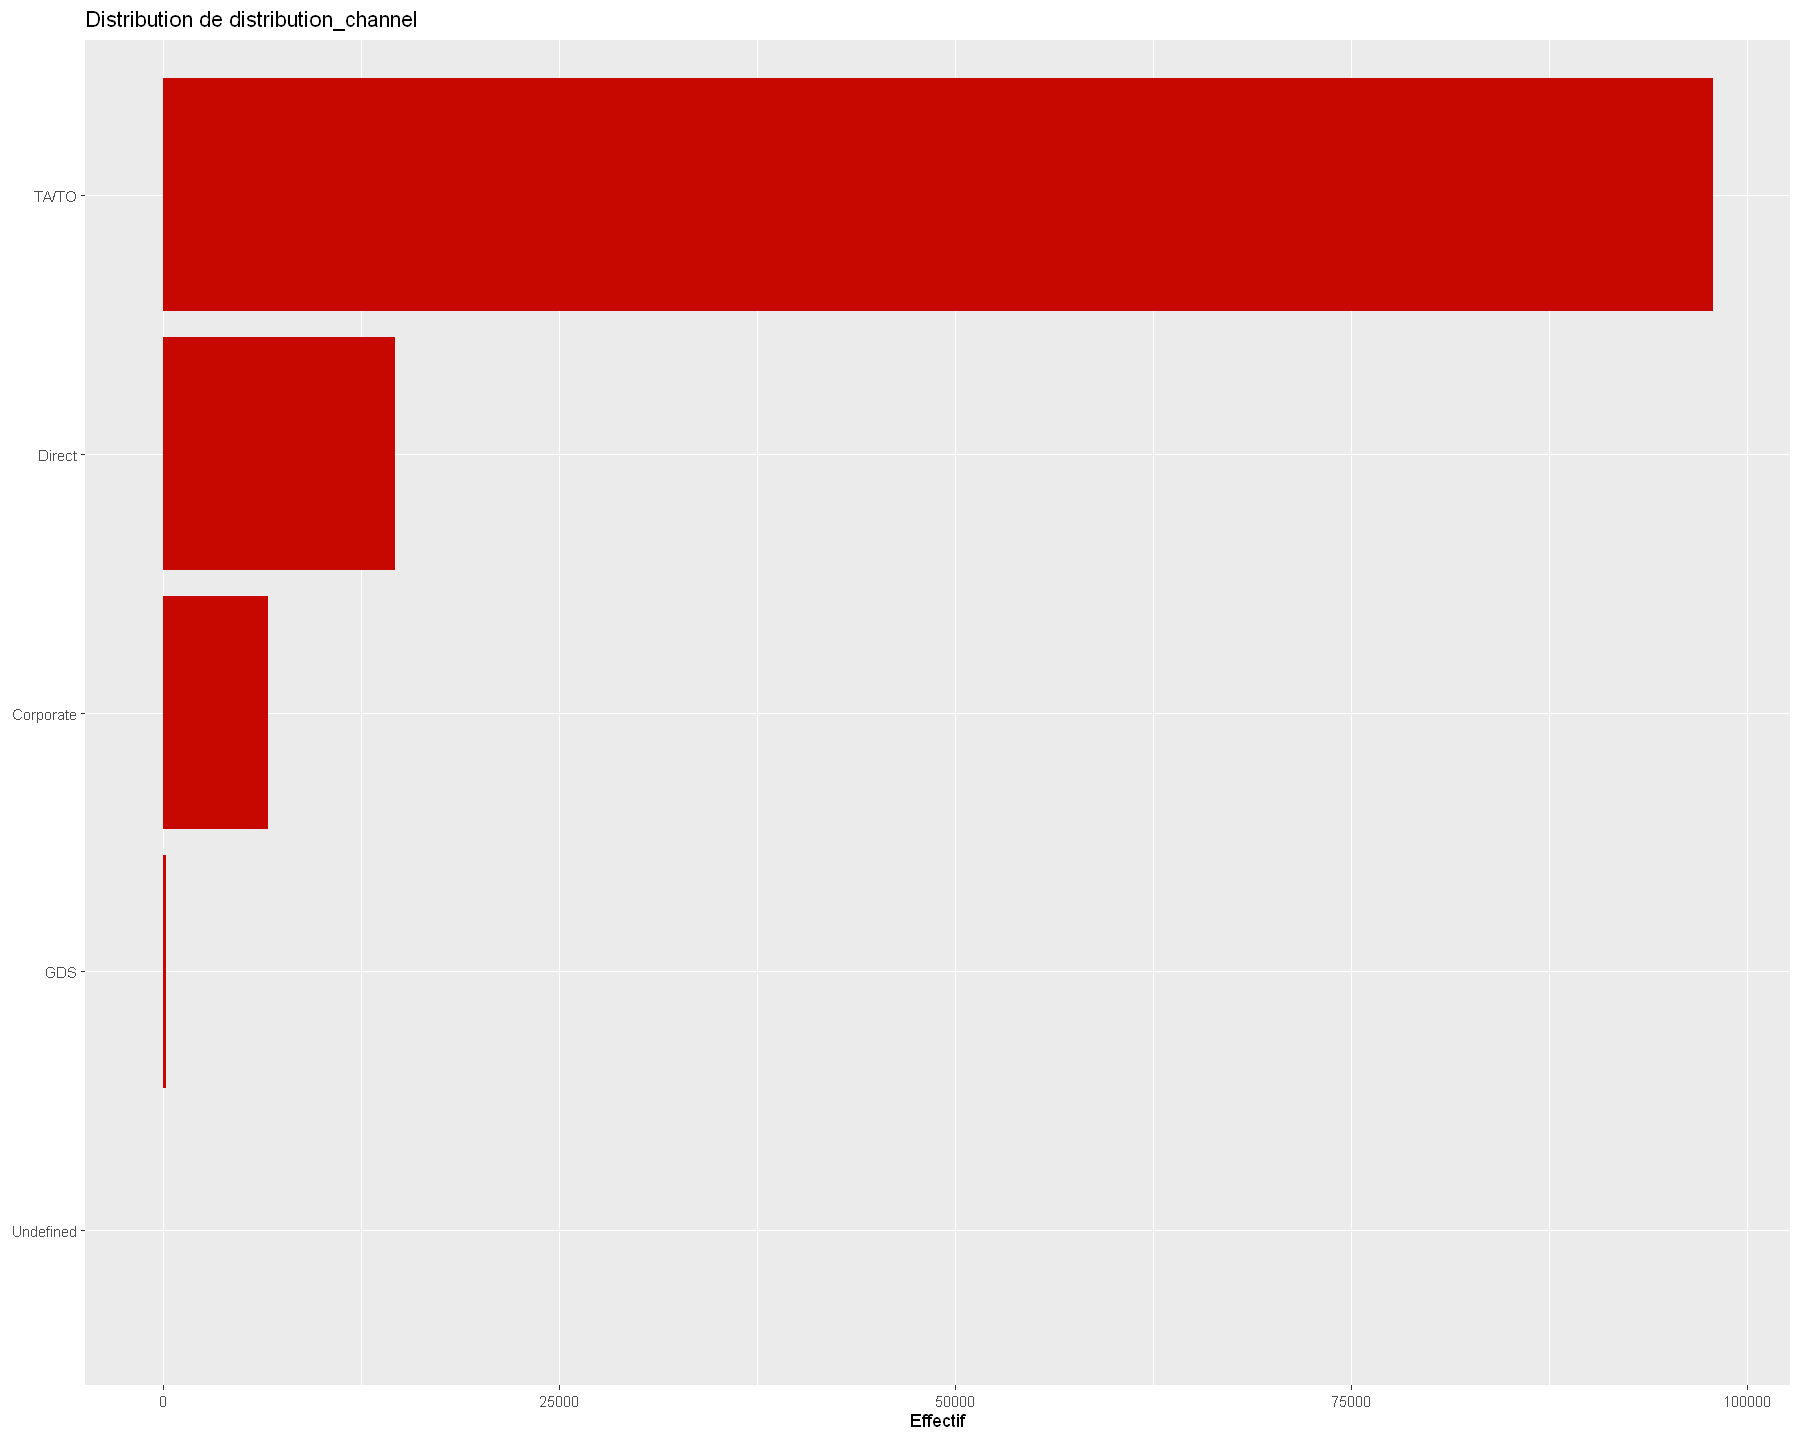


----------------------------------------
Variable : reserved_room_type 
----------------------------------------
# A tibble: 10 × 3
   modalite effectif pourcentage
   <chr>       <int>       <dbl>
 1 A           85994       72.0 
 2 D           19201       16.1 
 3 E            6535        5.47
 4 F            2897        2.43
 5 G            2094        1.75
 6 B            1118        0.94
 7 C             932        0.78
 8 H             601        0.5 
 9 P              12        0.01
10 L               6        0.01


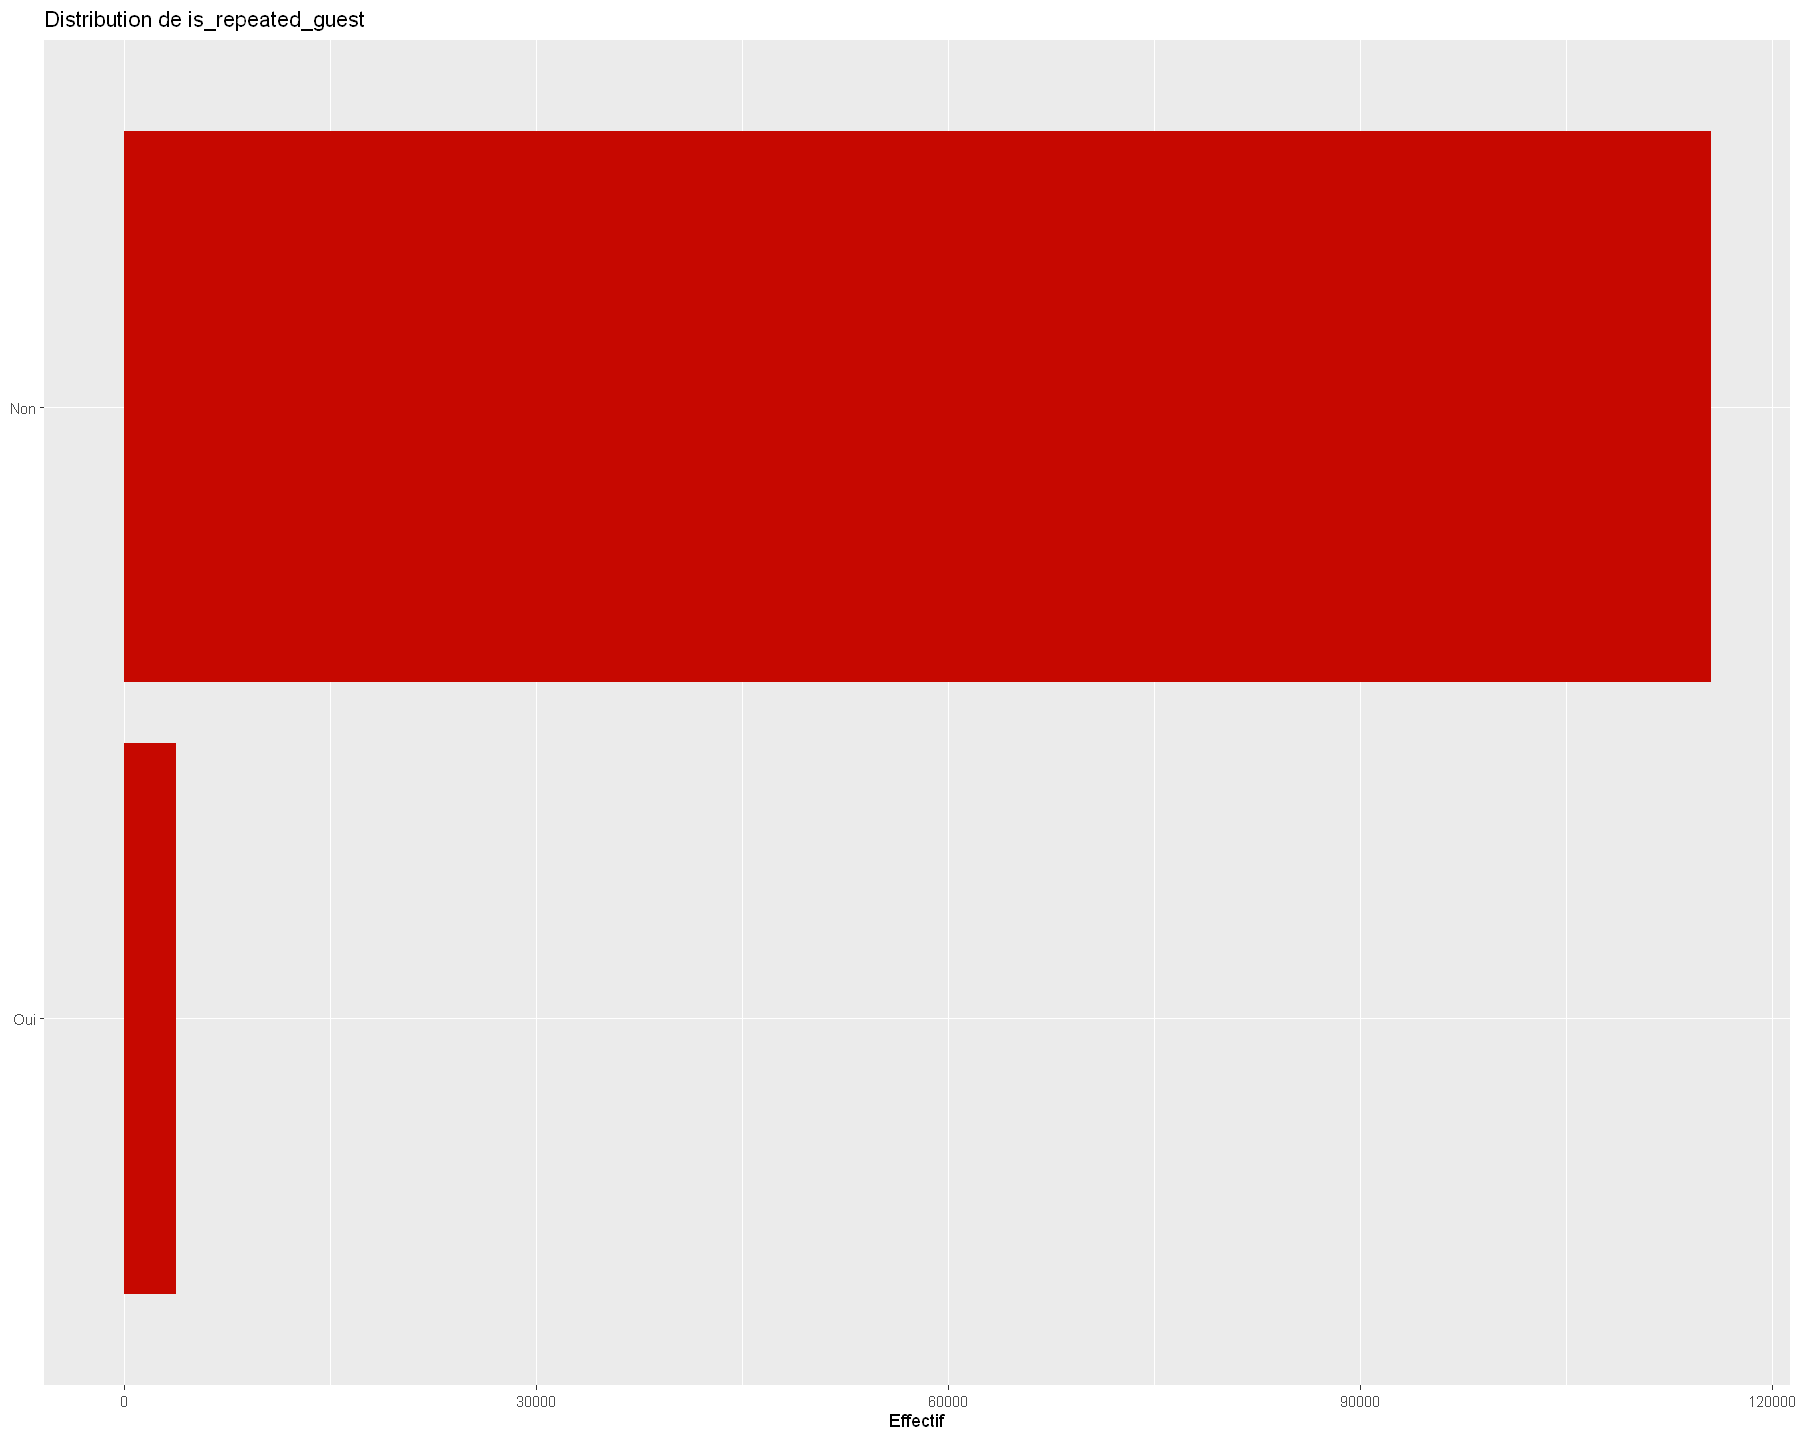


----------------------------------------
Variable : assigned_room_type 
----------------------------------------
# A tibble: 12 × 3
   modalite effectif pourcentage
   <chr>       <int>       <dbl>
 1 A           74053       62.0 
 2 D           25322       21.2 
 3 E            7806        6.54
 4 F            3751        3.14
 5 G            2553        2.14
 6 C            2375        1.99
 7 B            2163        1.81
 8 H             712        0.6 
 9 I             363        0.3 
10 K             279        0.23
11 P              12        0.01
12 L               1        0   


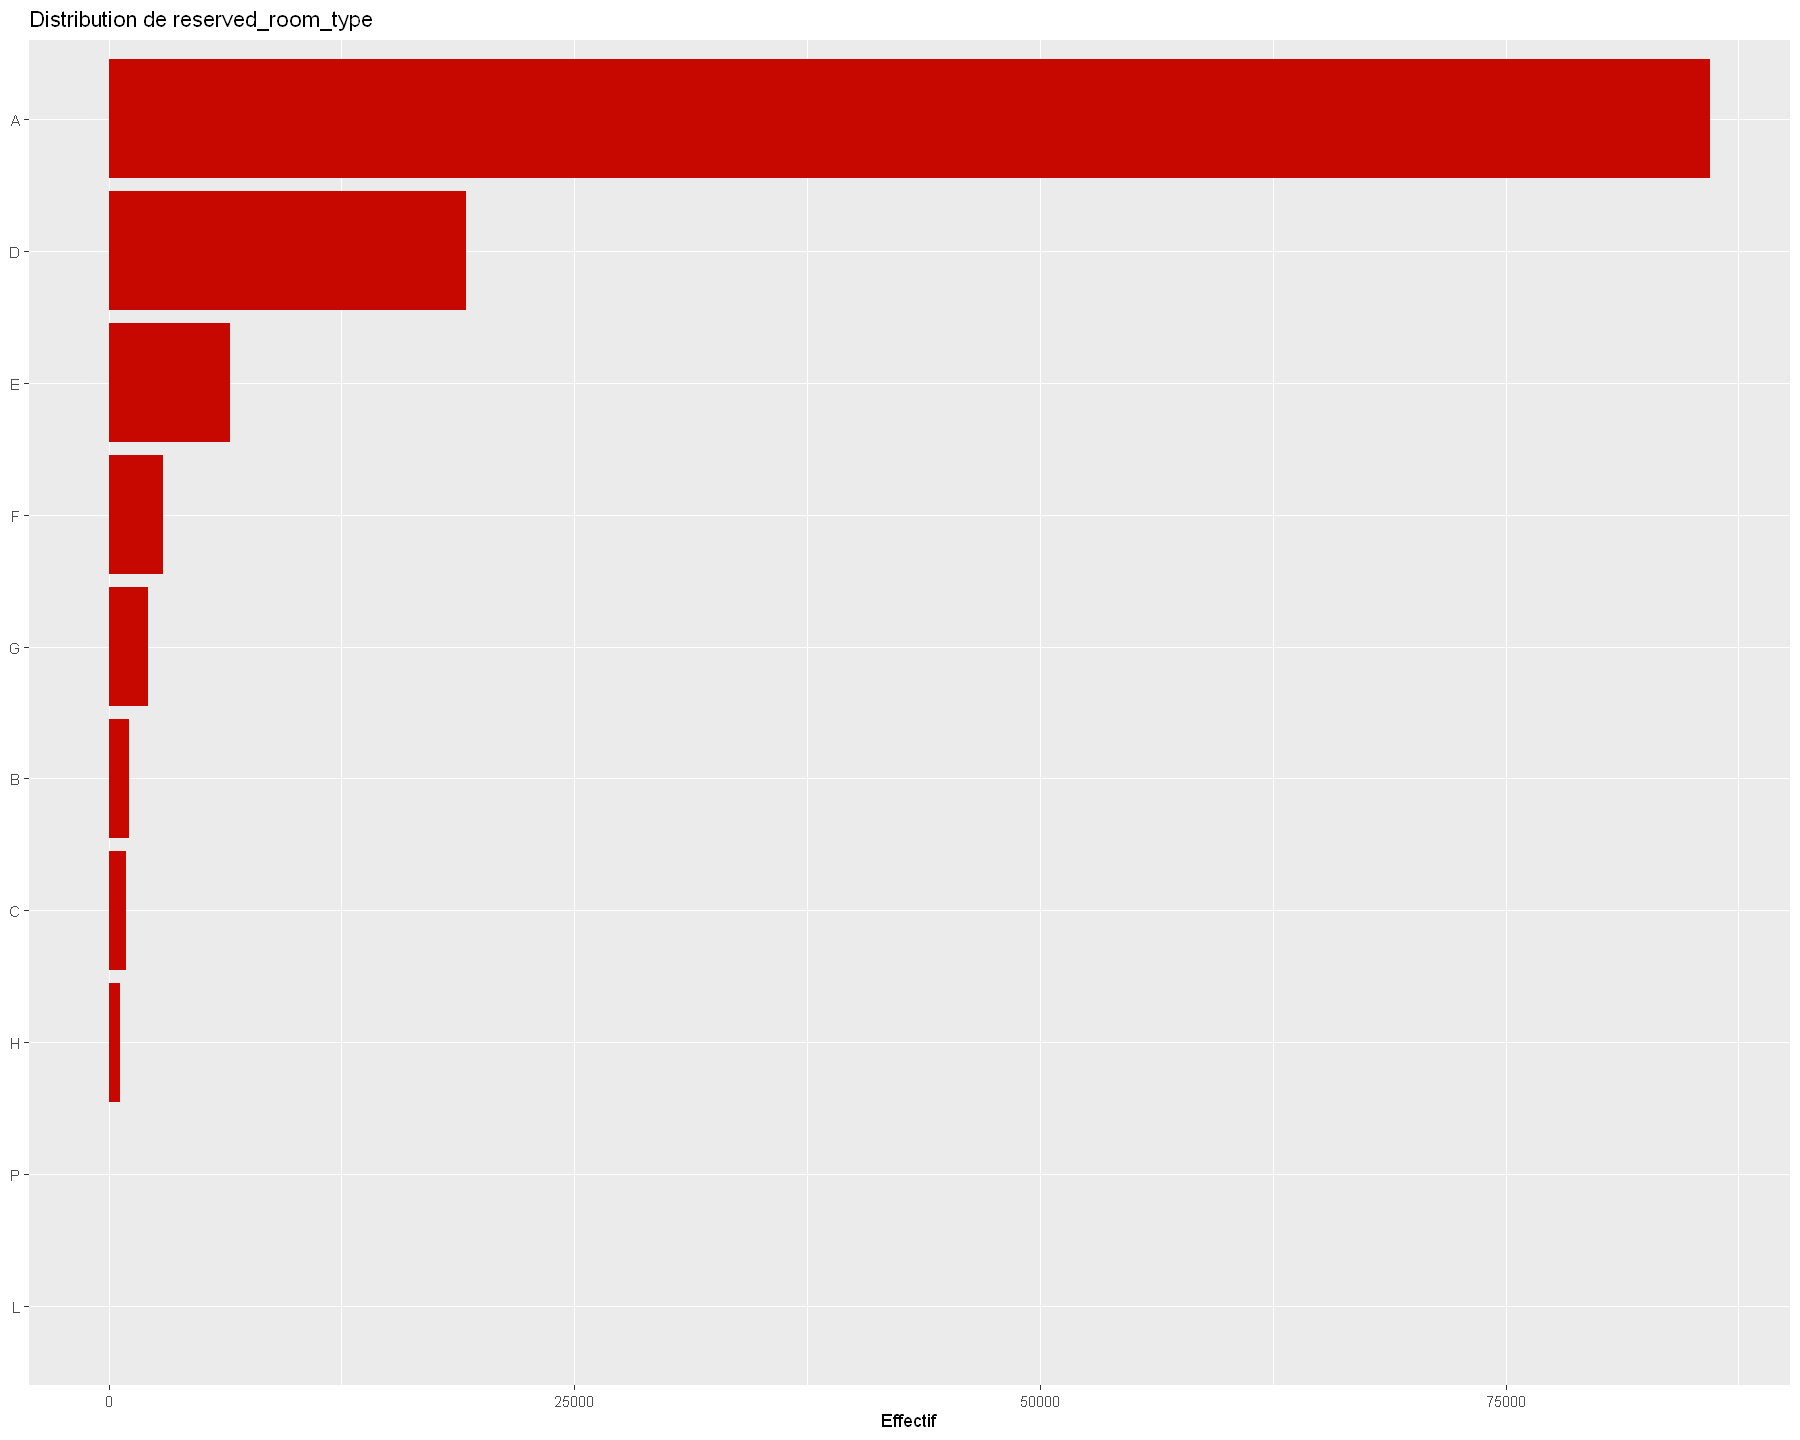


----------------------------------------
Variable : room_changed 
----------------------------------------
# A tibble: 2 × 3
  modalite effectif pourcentage
  <chr>       <int>       <dbl>
1 Non        104473        87.5
2 Oui         14917        12.5


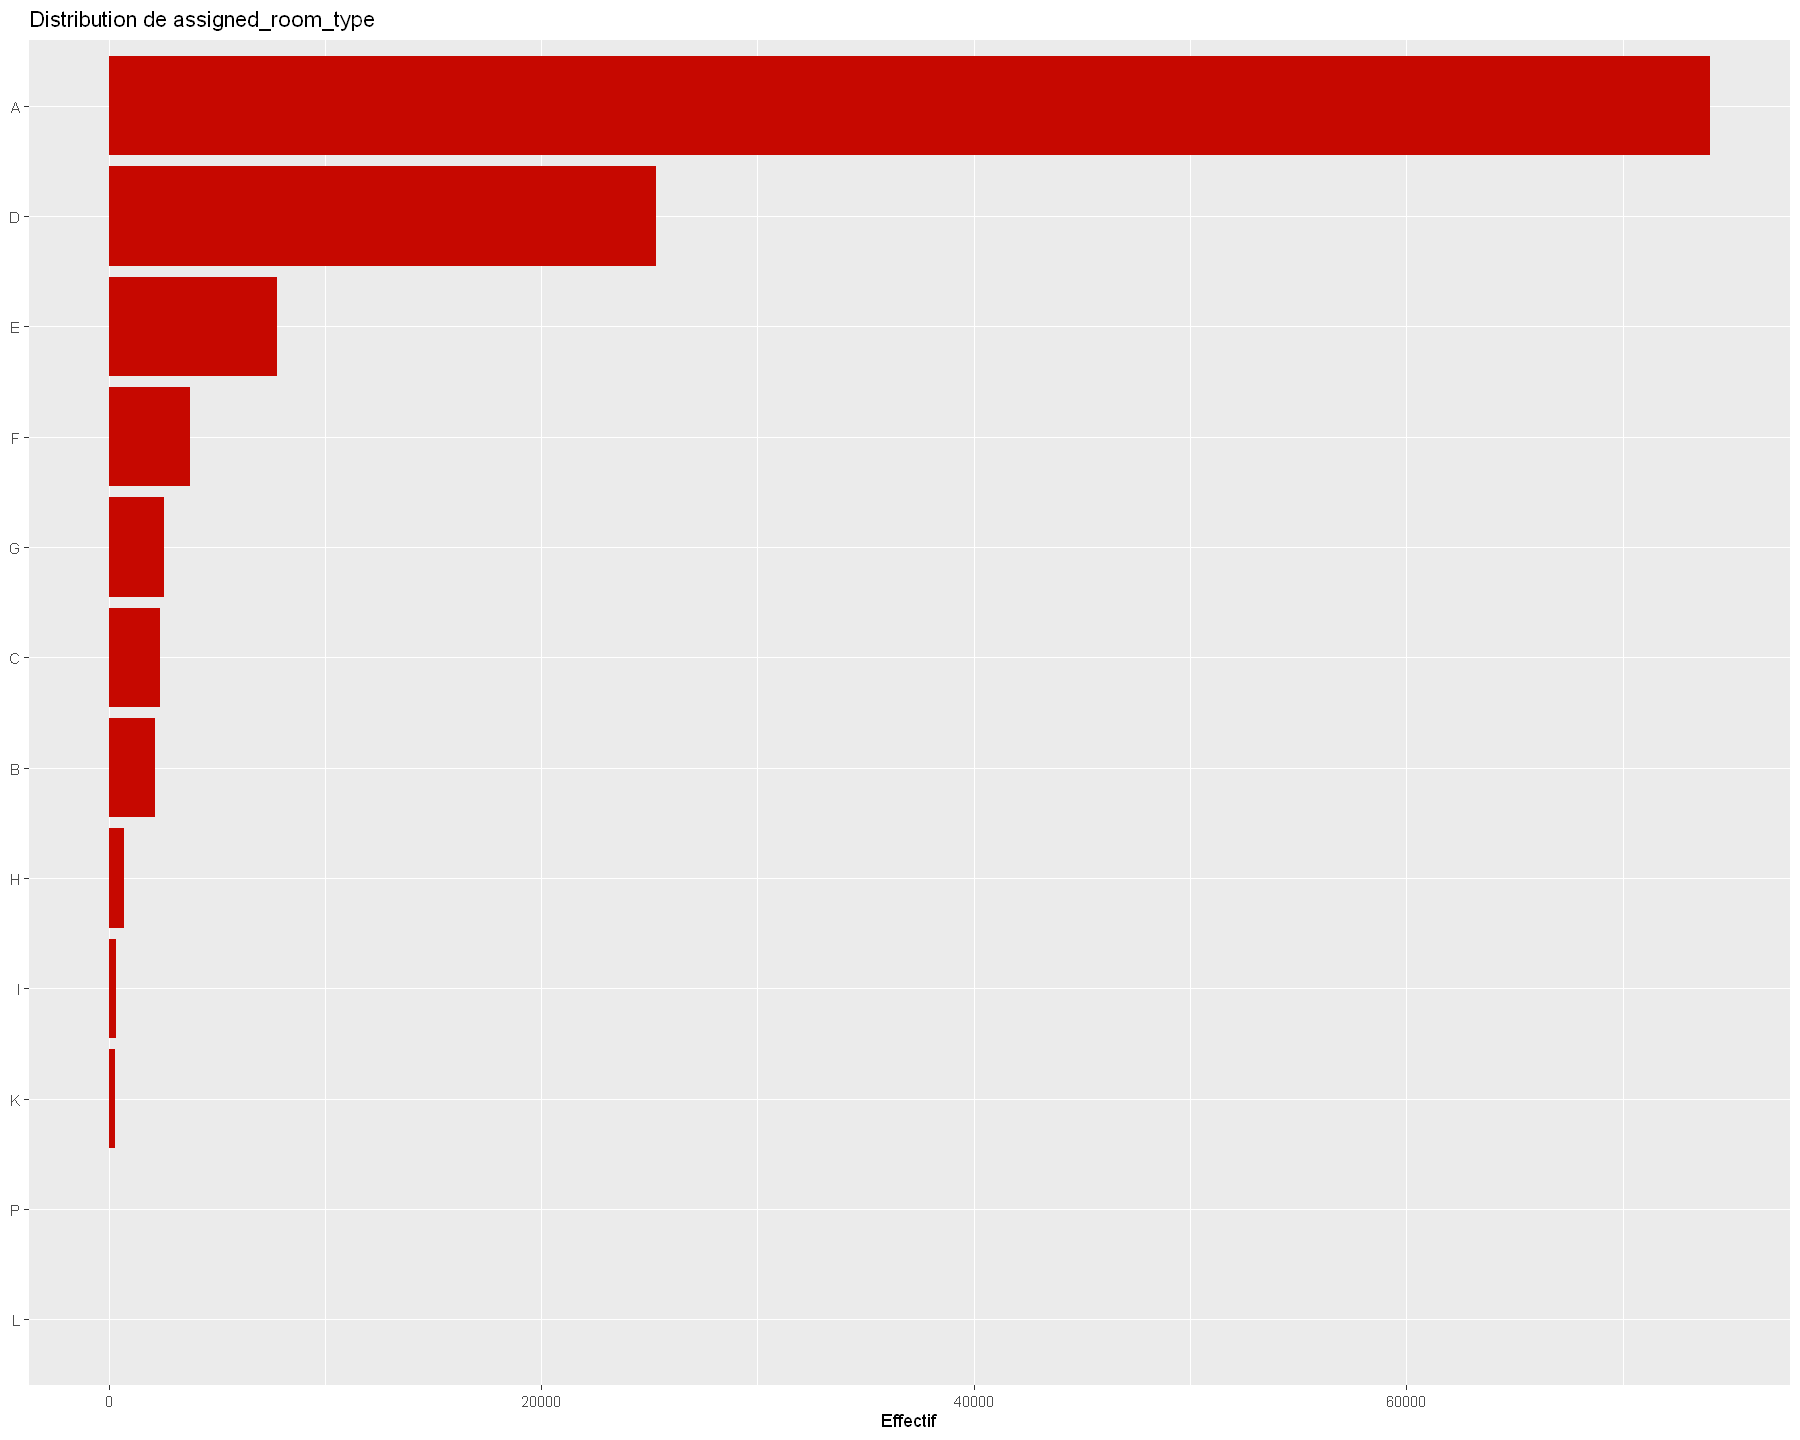


----------------------------------------
Variable : deposit_type 
----------------------------------------
# A tibble: 3 × 3
  modalite   effectif pourcentage
  <chr>         <int>       <dbl>
1 No Deposit   104641       87.6 
2 Non Refund    14587       12.2 
3 Refundable      162        0.14


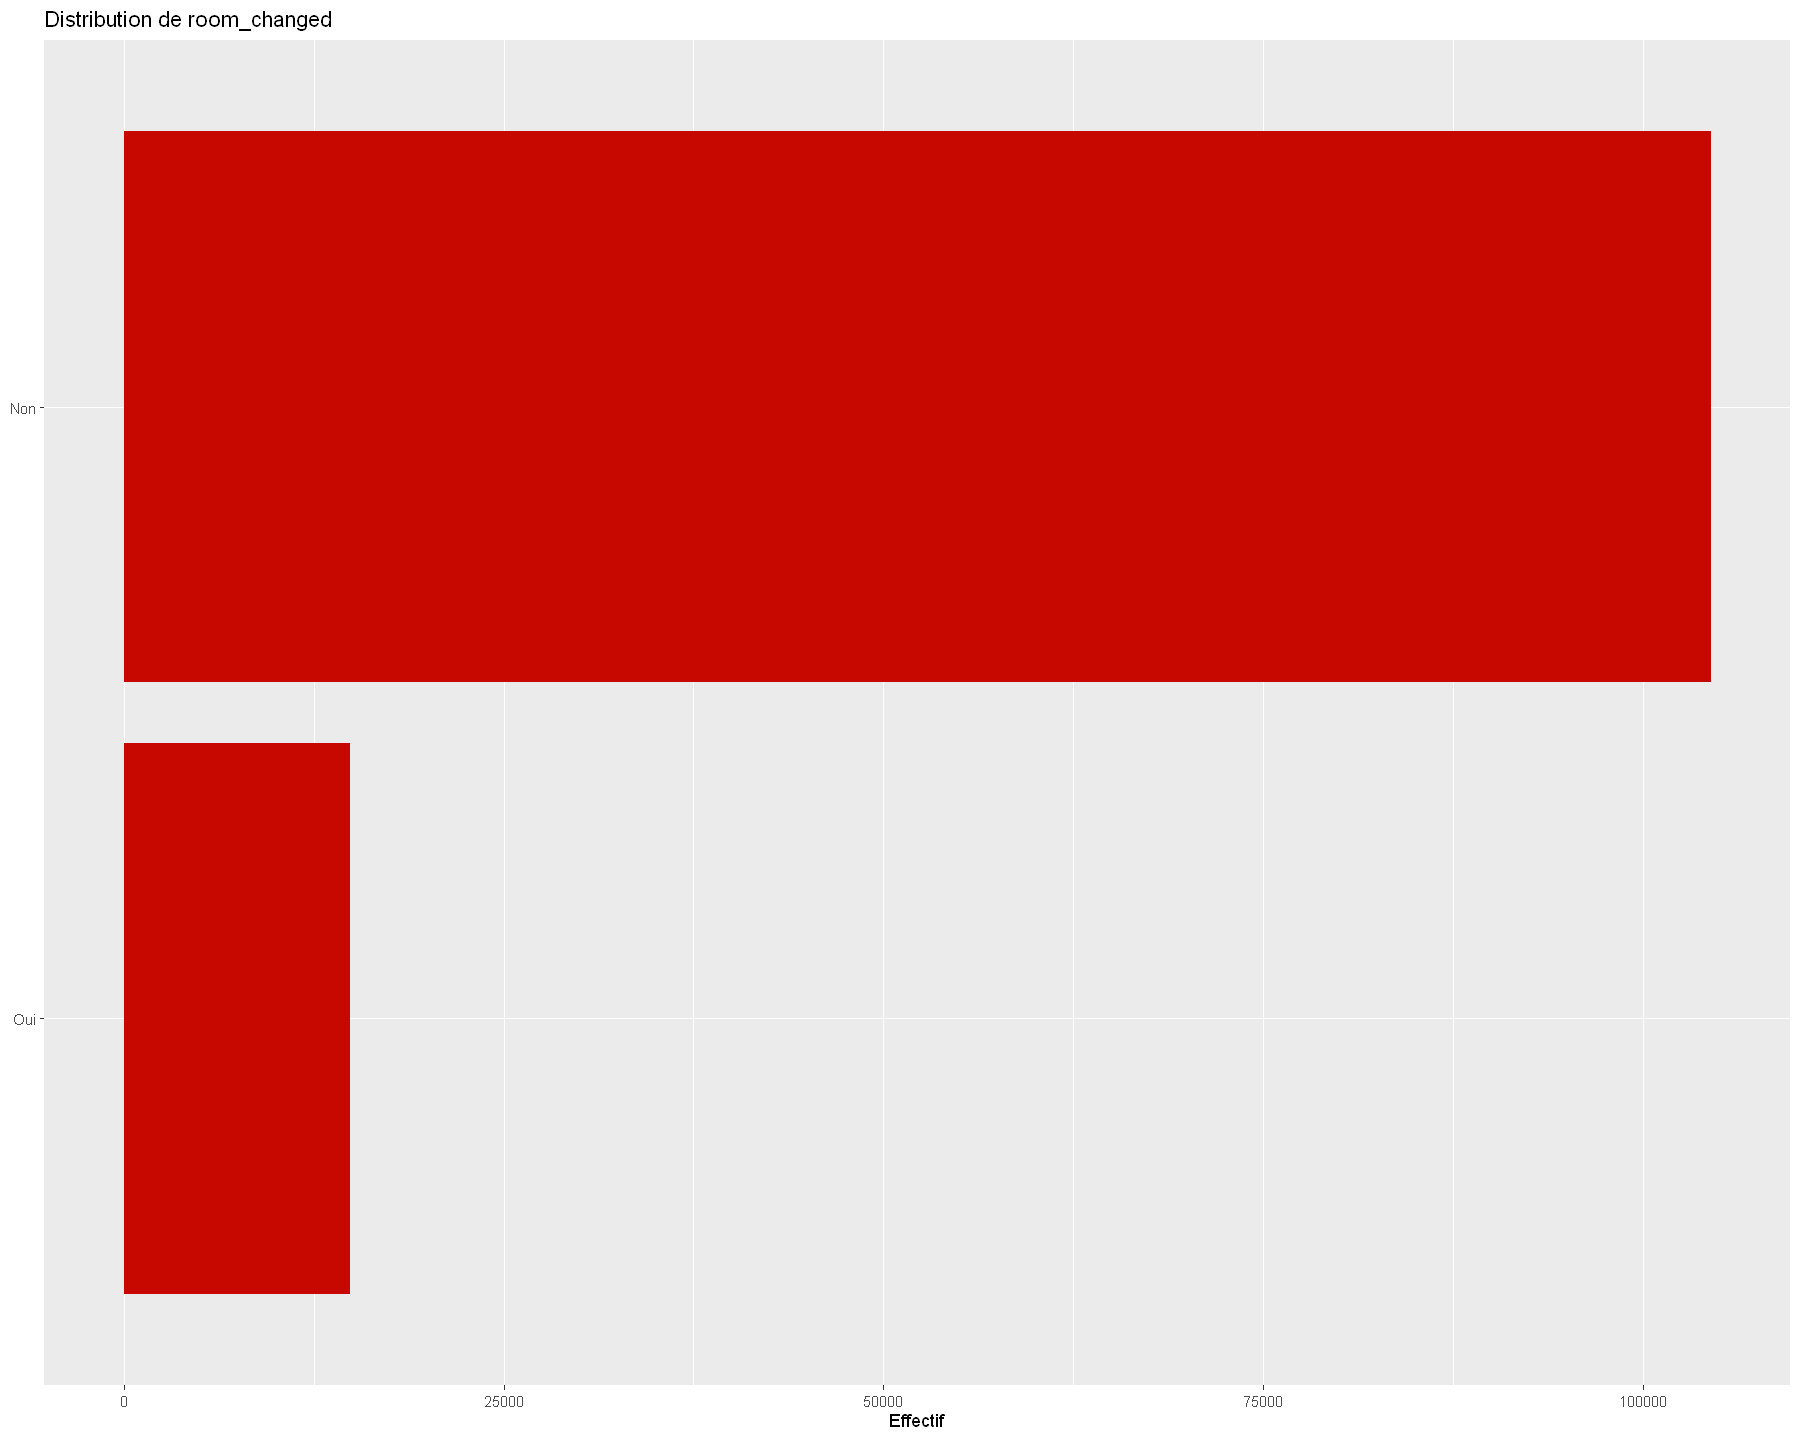


----------------------------------------
Variable : has_agent 
----------------------------------------
# A tibble: 1 × 3
  modalite effectif pourcentage
  <chr>       <int>       <dbl>
1 Oui        119390         100


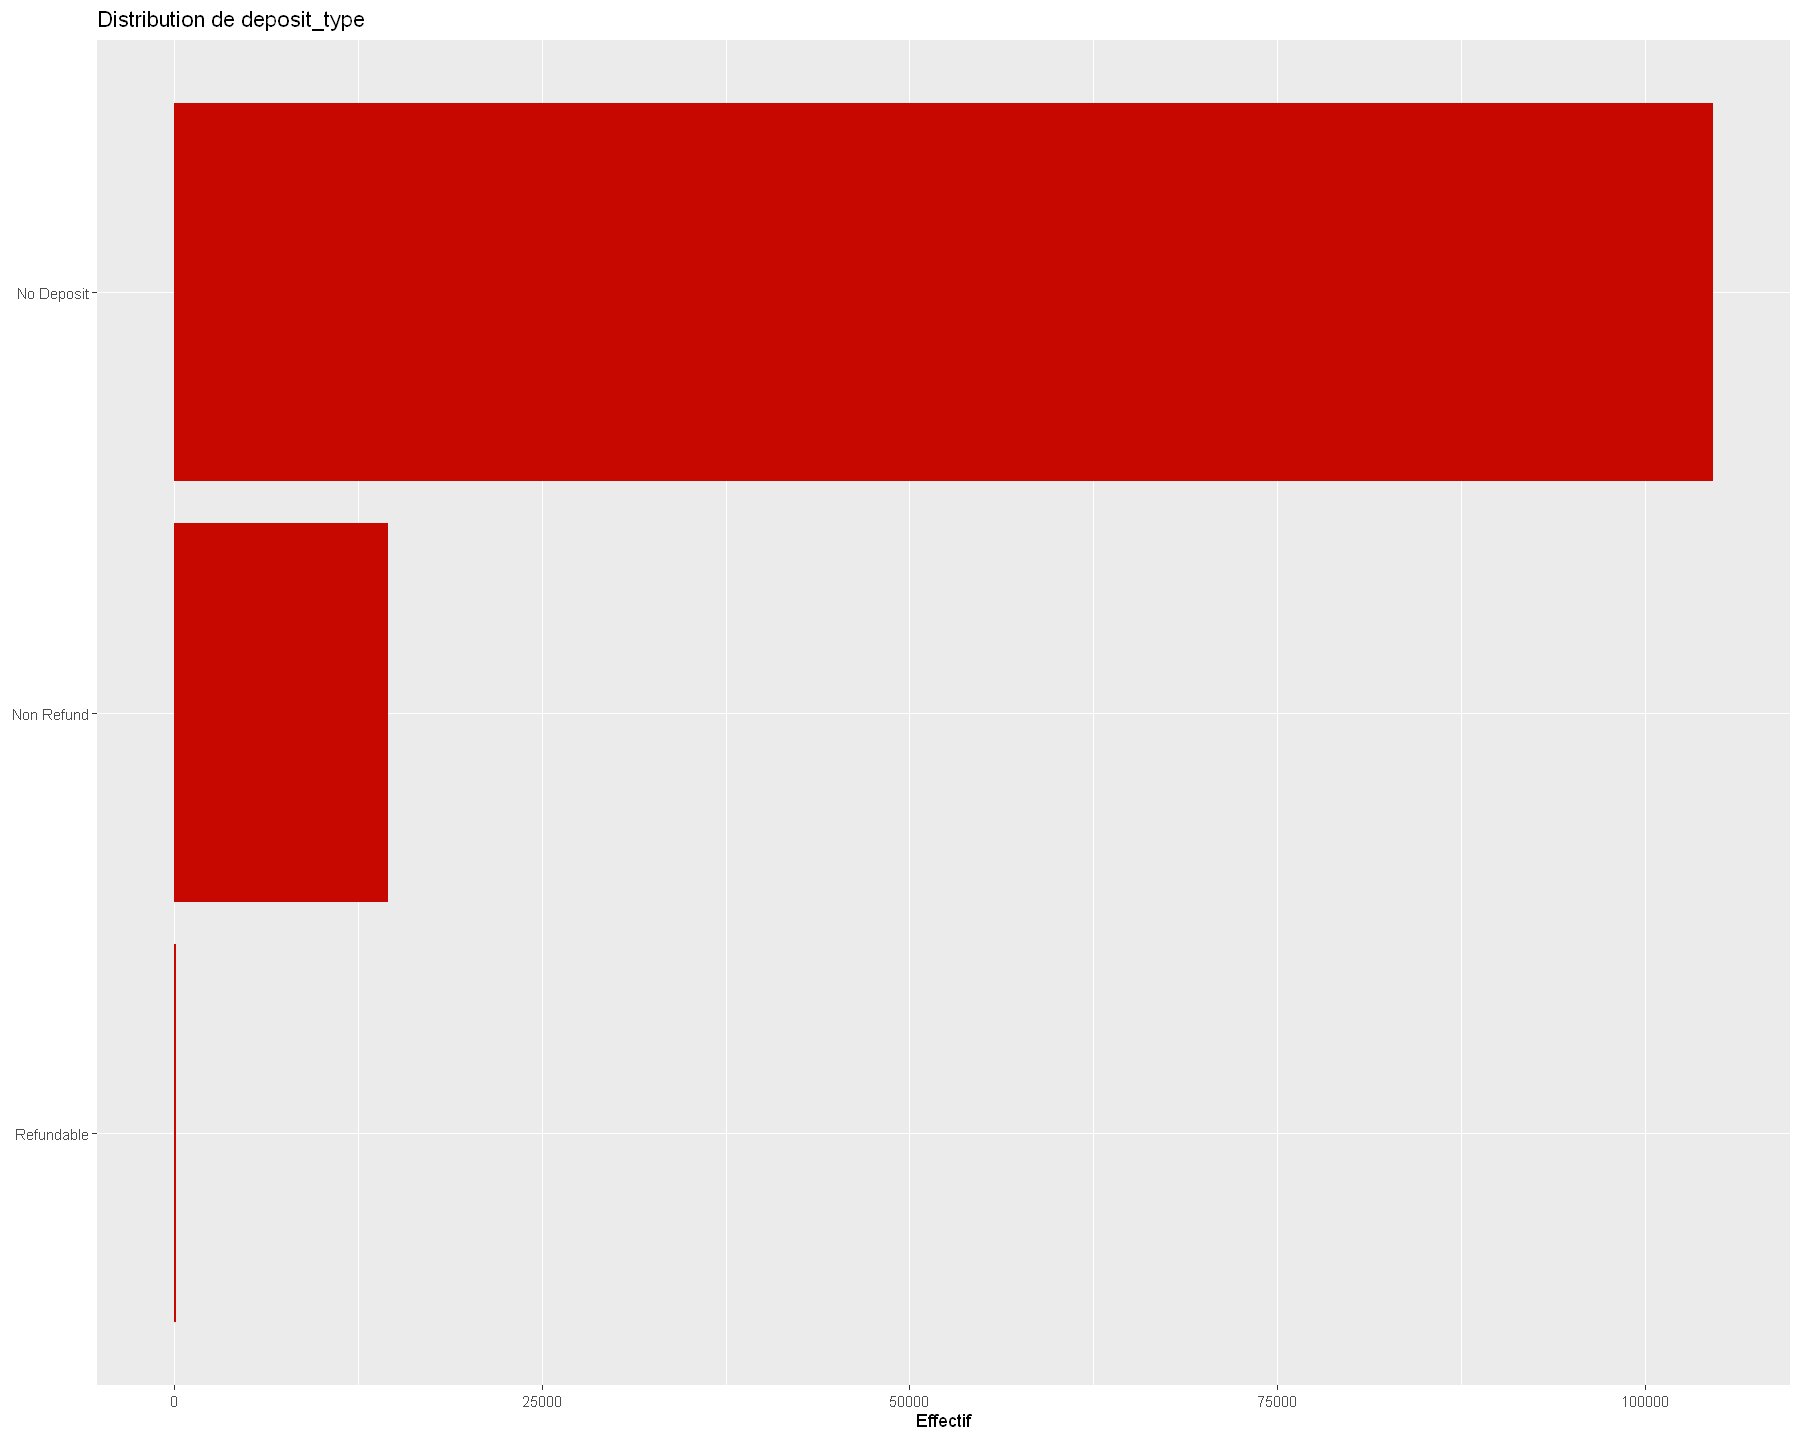


----------------------------------------
Variable : has_company 
----------------------------------------
# A tibble: 1 × 3
  modalite effectif pourcentage
  <chr>       <int>       <dbl>
1 Oui        119390         100


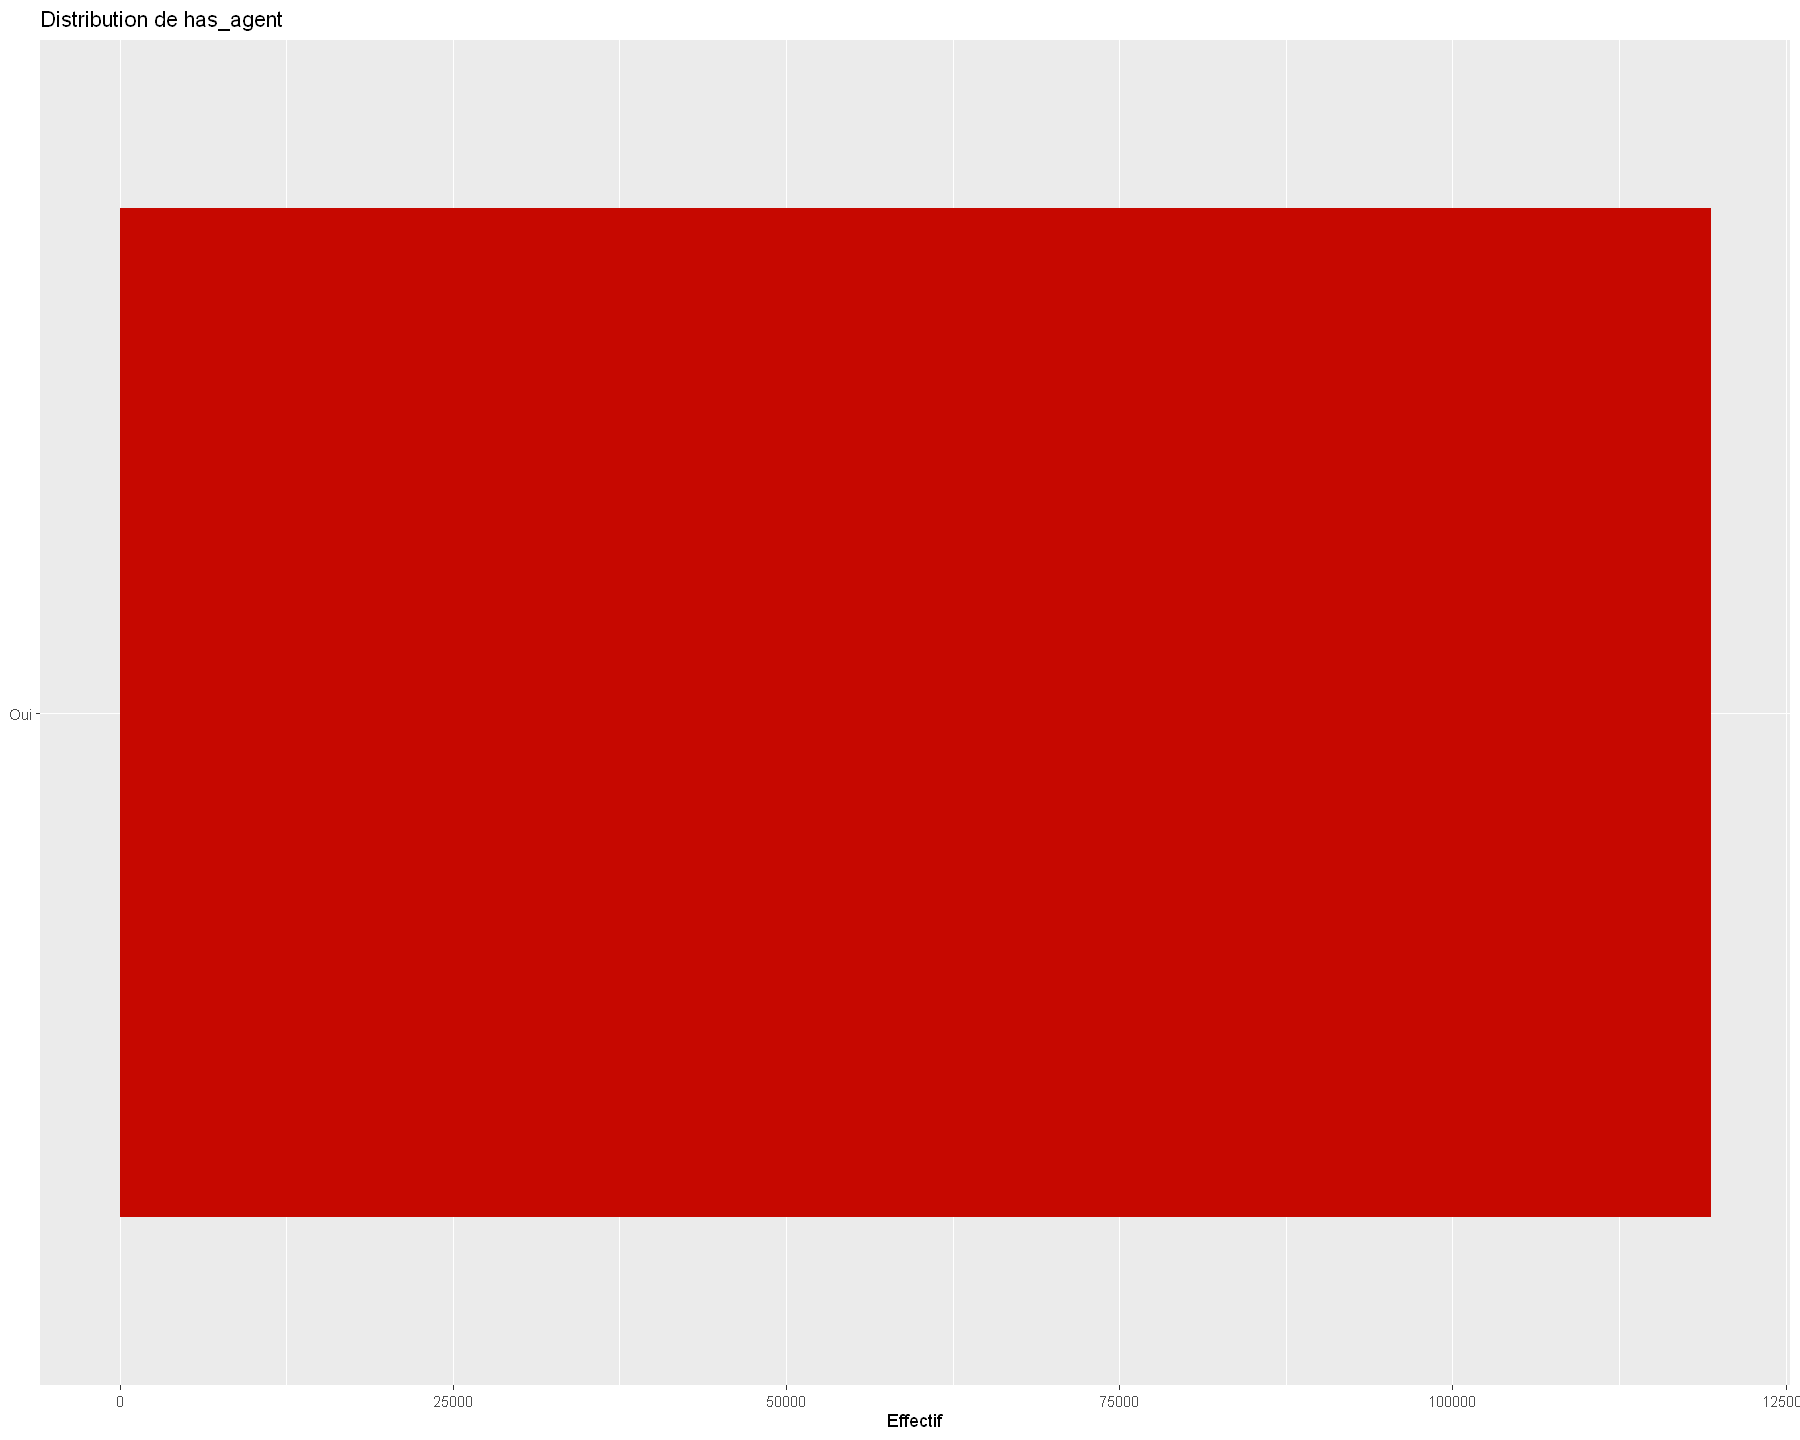


----------------------------------------
Variable : customer_type 
----------------------------------------
# A tibble: 4 × 3
  modalite        effectif pourcentage
  <chr>              <int>       <dbl>
1 Transient          89613       75.1 
2 Transient-Party    25124       21.0 
3 Contract            4076        3.41
4 Group                577        0.48


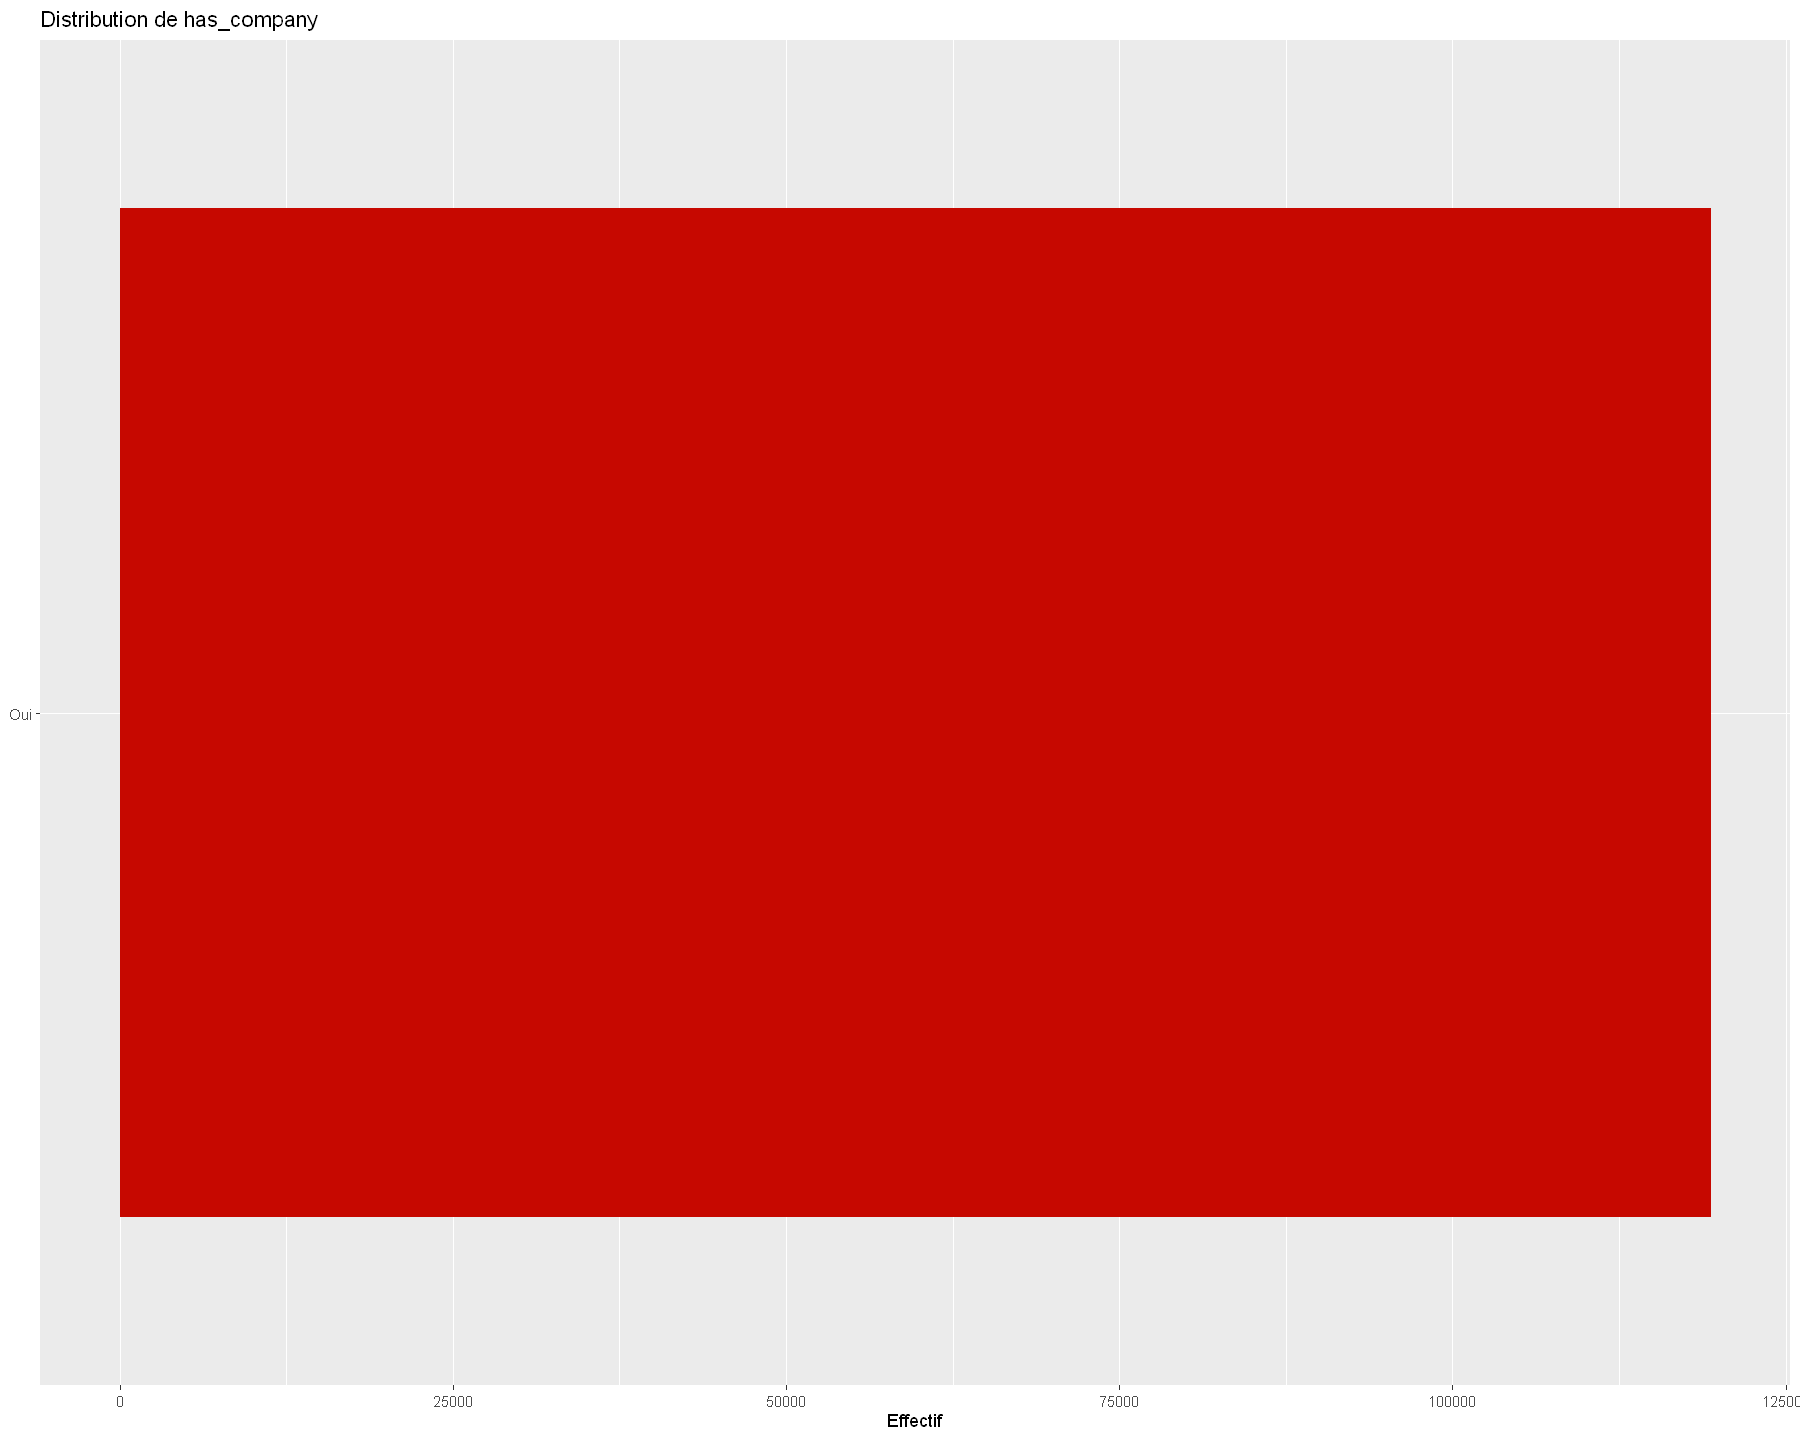


----------------------------------------
Variable : has_children 
----------------------------------------
# A tibble: 2 × 3
  modalite effectif pourcentage
  <chr>       <int>       <dbl>
1 Non        110058       92.2 
2 Oui          9332        7.82


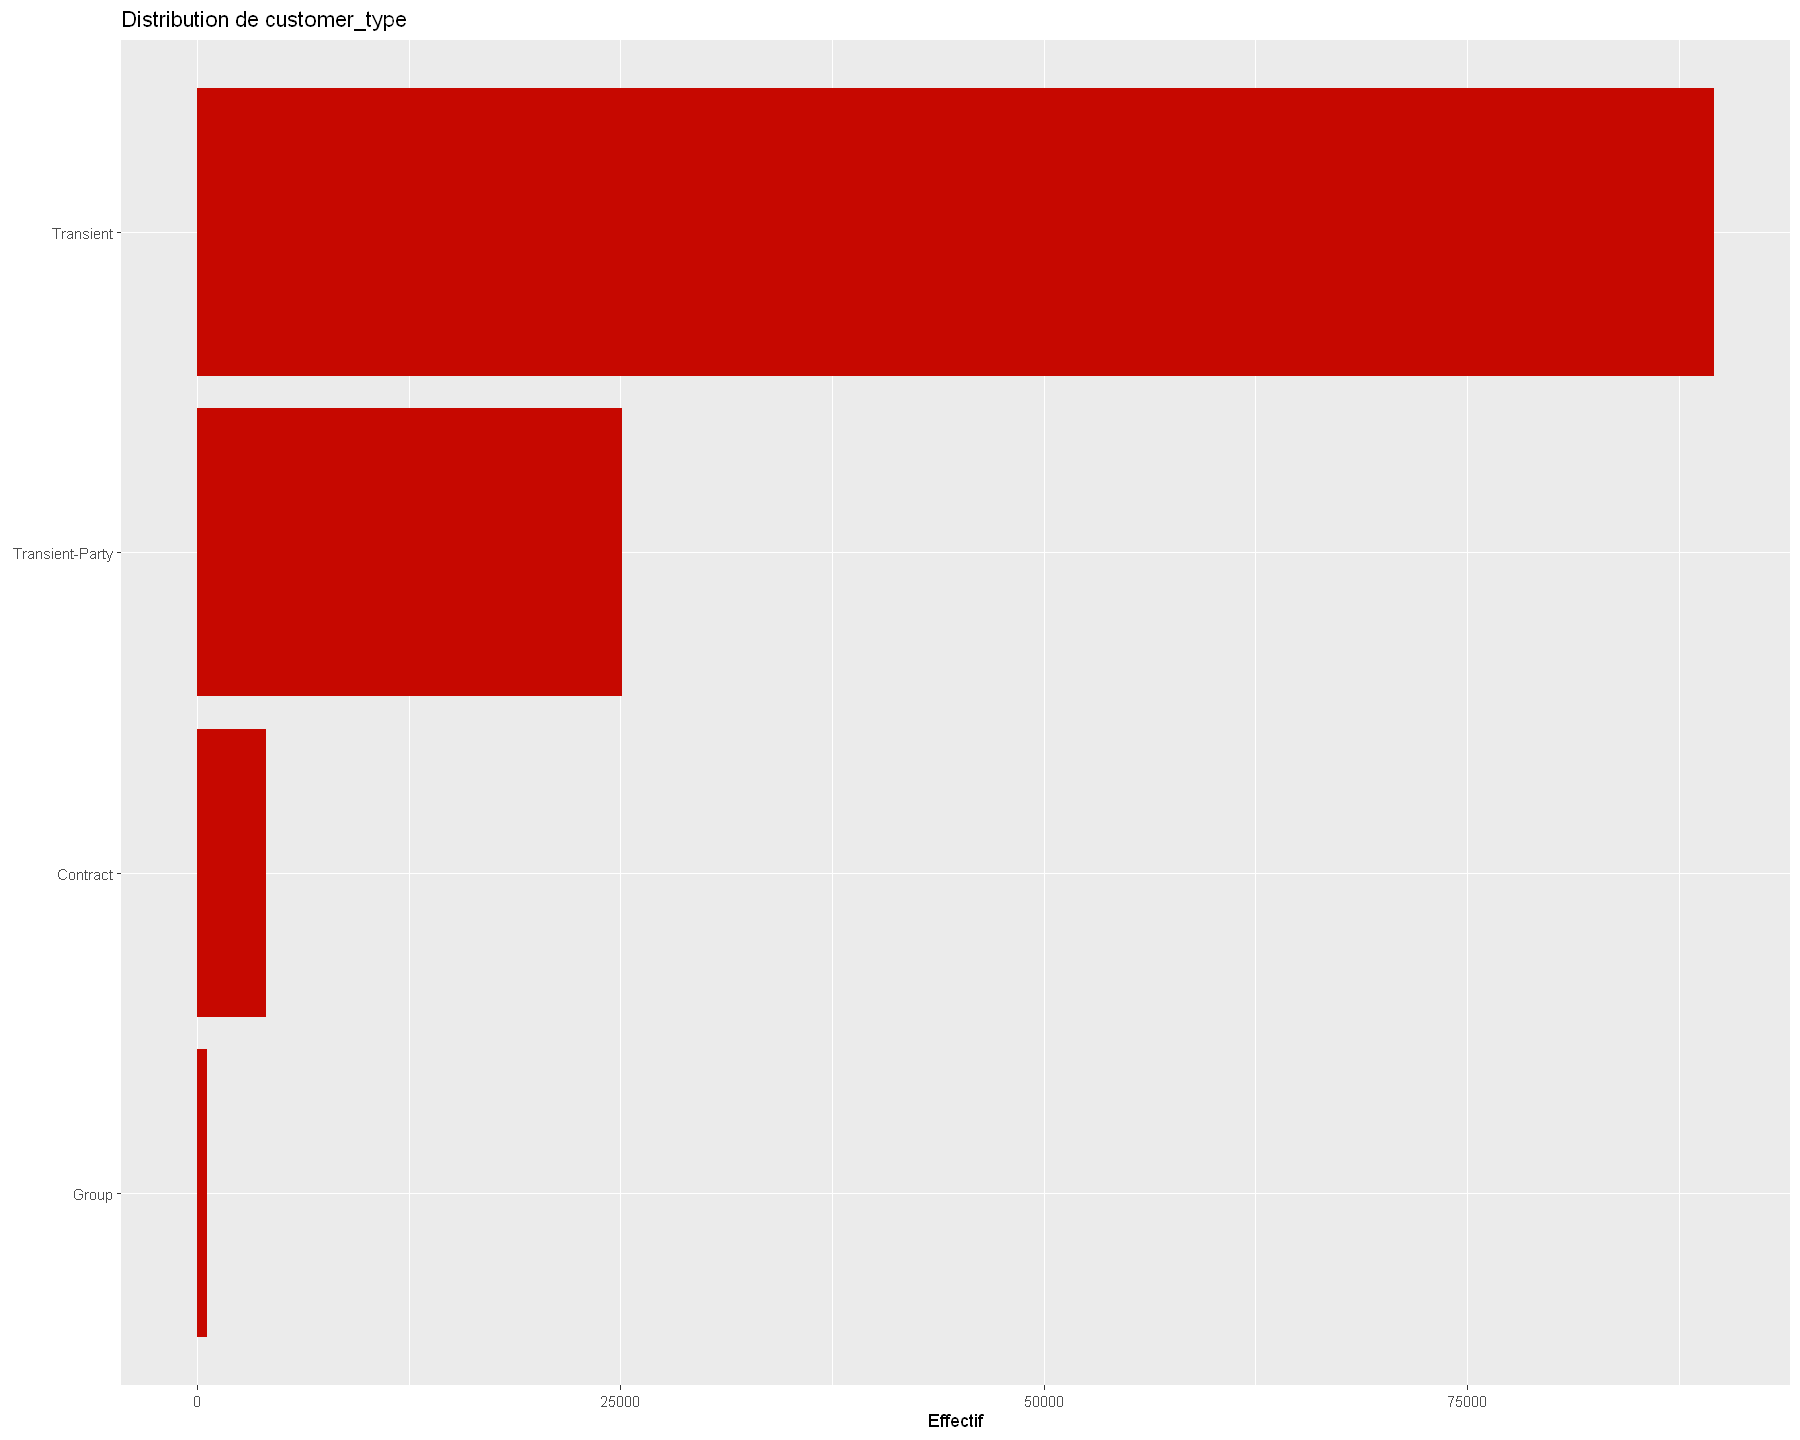

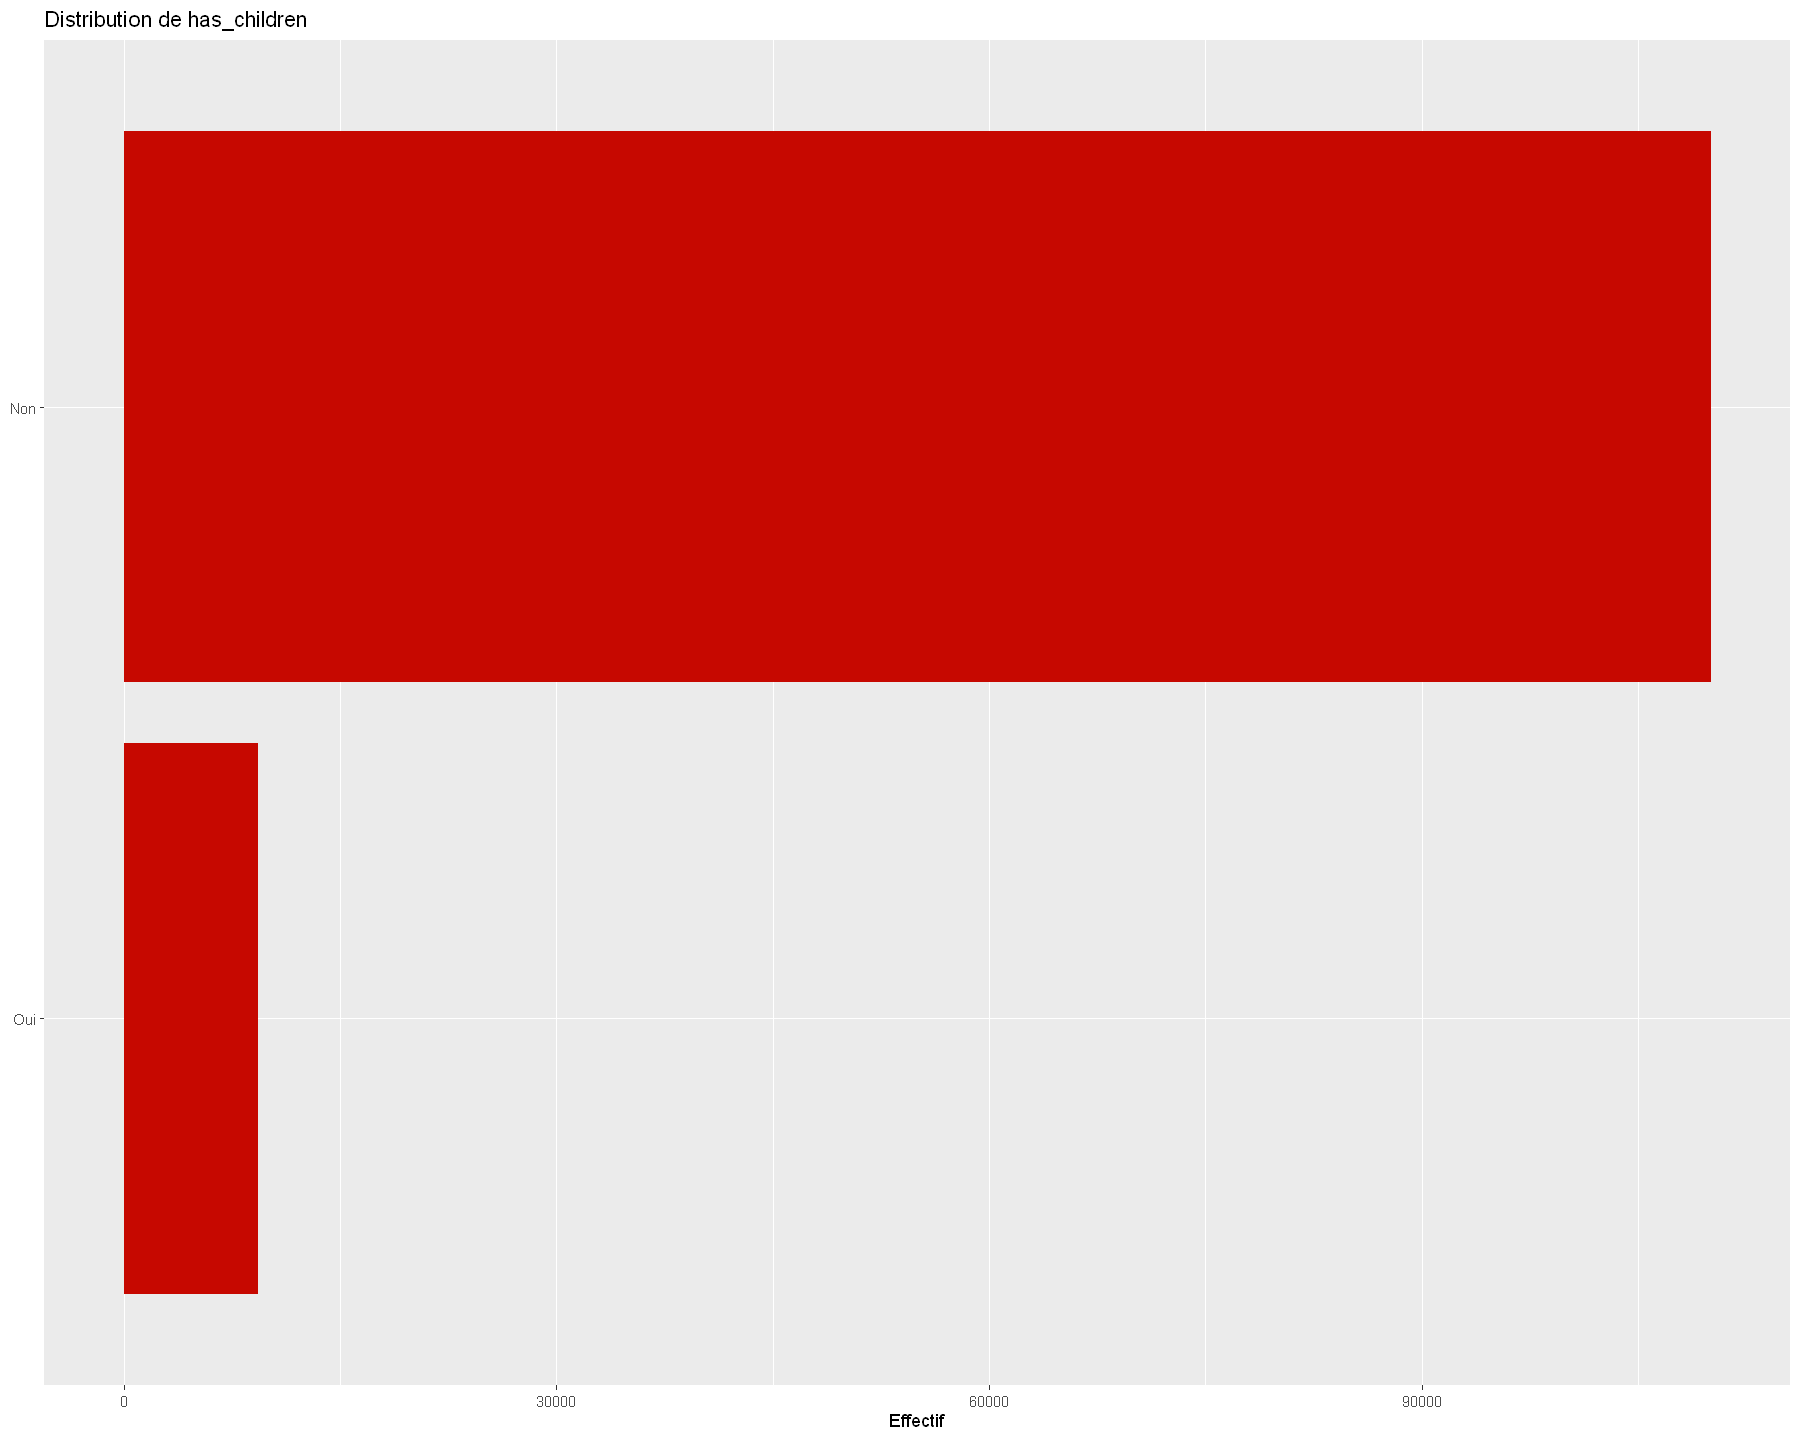

In [40]:
library(tidyverse)

# ---- 1. Tableau de synthèse global des variables qualitatives ----
resume_quali <- map_dfr(vars_quali, function(v) {
  freq <- hotels %>%
    count(modalite = .data[[v]], name = "effectif") %>%
    arrange(desc(effectif)) %>%
    mutate(pourcentage = round(effectif / sum(effectif) * 100, 2))
  
  tibble(
    variable = v,
    n_modalites = n_distinct(hotels[[v]]),
    n_manquants = sum(is.na(hotels[[v]])),
    mode = as.character(freq$modalite[1]),
    pct_mode = freq$pourcentage[1]
  )
})

cat("\n=== SYNTHÈSE DES VARIABLES QUALITATIVES ===\n")
print(resume_quali, n = Inf)


# ---- 2. Détail et graphiques pour chaque variable qualitative ----
for (v in vars_quali) {
  cat("\n----------------------------------------\n")
  cat("Variable :", v, "\n")
  cat("----------------------------------------\n")
  
  # Tableau des fréquences trié
  freq <- hotels %>%
    count(modalite = .data[[v]], name = "effectif") %>%
    mutate(pourcentage = round(effectif / sum(effectif) * 100, 2)) %>%
    arrange(desc(effectif))
  
  print(freq, n = Inf)
  
  # Préparation du graphique (tri par effectif sauf si le facteur est ordonné)
  freq_plot <- freq
  if (!is.ordered(hotels[[v]])) {
    freq_plot <- freq_plot %>%
      mutate(modalite = fct_reorder(as.factor(modalite), effectif))
  }
  
  # Affichage du graphique en barres
  p <- ggplot(freq_plot, aes(x = modalite, y = effectif)) +
    geom_col(fill = "#C60800") +
    coord_flip() +
    labs(title = paste("Distribution de", v), x = NULL, y = "Effectif")
  
  print(p)
}

Variables qualitatives:

**hotel** — City Hotel 66,5 %, Resort Hotel 33,5 % : l'activité est dominée par l'hôtel de ville, deux fois plus de réservations que le resort.

**is_canceled (la cible)** — 37,04 % d'annulations : un taux élevé, et une cible assez équilibrée pour être étudiée sans problème de rareté.

**arrival_date_month** — Pic estival : août 11,6 %, juillet 10,6 %, creux en hiver (janvier ~5 %) ; la répartition reste étalée (entropie proche du maximum) : il y a une saisonnalité, pas une mono-saison.

**saison** — Été 31,4 %, puis les trois autres saisons se partagent le reste de façon assez égale : confirme le pic d'été sans effacer le reste de l'année.

**meal** — BB (petit-déjeuner seul) écrase tout : 77,3 % ; HB 12,1 %, SC 8,9 %, FB marginal (0,67 %) et 0,98 % « Undefined » — une modalité fourre-tout à noter. L'offre de restauration est basique.

**country** — 177 pays, mais une concentration forte : le Portugal seul fait 40,7 %, puis Royaume-Uni 10,2 %, France 8,7 %, Espagne 7,2 %, Allemagne 6,1 % — les 5 premiers pays font ~73 % des réservations. La clientèle est d'abord domestique, puis européenne proche. 488 valeurs manquantes (0,4 %).

**country_group** — Après regroupement au seuil de 0,5 % : 21 modalités, PRT inchangé à 40,7 %, le reste du monde fondu dans « Other » — la lecture devient possible sans perdre l'essentiel.

**market_segment** — Online TA 47,3 %, Offline TA/TO 20,3 %, Groups 16,6 %, Direct seulement 10,6 %, Corporate 4,4 %. L'intermédiation domine : près de 7 réservations sur 10 passent par une agence.

**distribution_channel** — Encore plus concentré : TA/TO 82 %, Direct 12,3 %, Corporate 5,6 %, GDS anecdotique (0,16 %). La distribution directe est minoritaire.

**is_repeated_guest** — 3,2 % seulement de clients déjà venus : une clientèle presque entièrement nouvelle, ou un historique mal relié entre réservations.

**reserved_room_type** — Domination du type A (72 %), puis D (16,1 %) ; les 8 autres types se partagent le reste : l'offre réellement vendue tient en deux catégories.

**assigned_room_type** — A redescend à 62 %, D monte à 21,2 %, et la distribution s'étale vers les autres types : à l'arrivée, l'hôtel réattribue une partie des chambres.

**room_changed** — 12,5 % des réservations n'ont pas la chambre réservée : un phénomène opérationnel réel, pas du bruit — un client sur huit est déplacé.

**deposit_type** — La variable la plus déséquilibrée : No Deposit 87,7 %, Non Refund 12,2 %, Refundable 0,14 % (162 réservations). La politique commerciale est massivement « sans acompte ».

**agent** — 333 identifiants, manquant à 13,7 % ; l'agent 9 concentre à lui seul 26,8 % des réservations avec agent — un canal dominant, probablement la plateforme principale.

**has_agent** — 86,3 % des réservations passent par un agent : cohérent avec la domination des canaux TA/TO.

**company** — Manquante à 94,3 % : les réservations d'entreprise identifiée sont exceptionnelles.

**has_company** — 5,7 % seulement : confirme que le B2B identifié est marginal face aux particuliers et aux agences.

**customer_type** — Transient 75,1 %, Transient-Party 21 %, Contract 3,4 %, Group 0,5 % : une clientèle d'individuels, très peu de groupes constitués.

**reservation_status** — Check-Out 63 %, Canceled 36 %, No-Show 1 %. Petit écart avec la cible : 1 % de « No-Show » (le client ne s'est pas présenté) sont comptés comme non annulés dans is_canceled — les deux variables se ressemblent sans être identiques.

**reservation_status_date (la date)** — 119 390 statuts, du 17 octobre 2014 au 14 septembre 2017 (1 063 jours, 926 dates distinctes, médiane le 7 août 2016) : la couverture temporelle est complète et sans trou majeur.

### BIVARIÉ QUALITATIF : chaque variable explicative x is_canceled

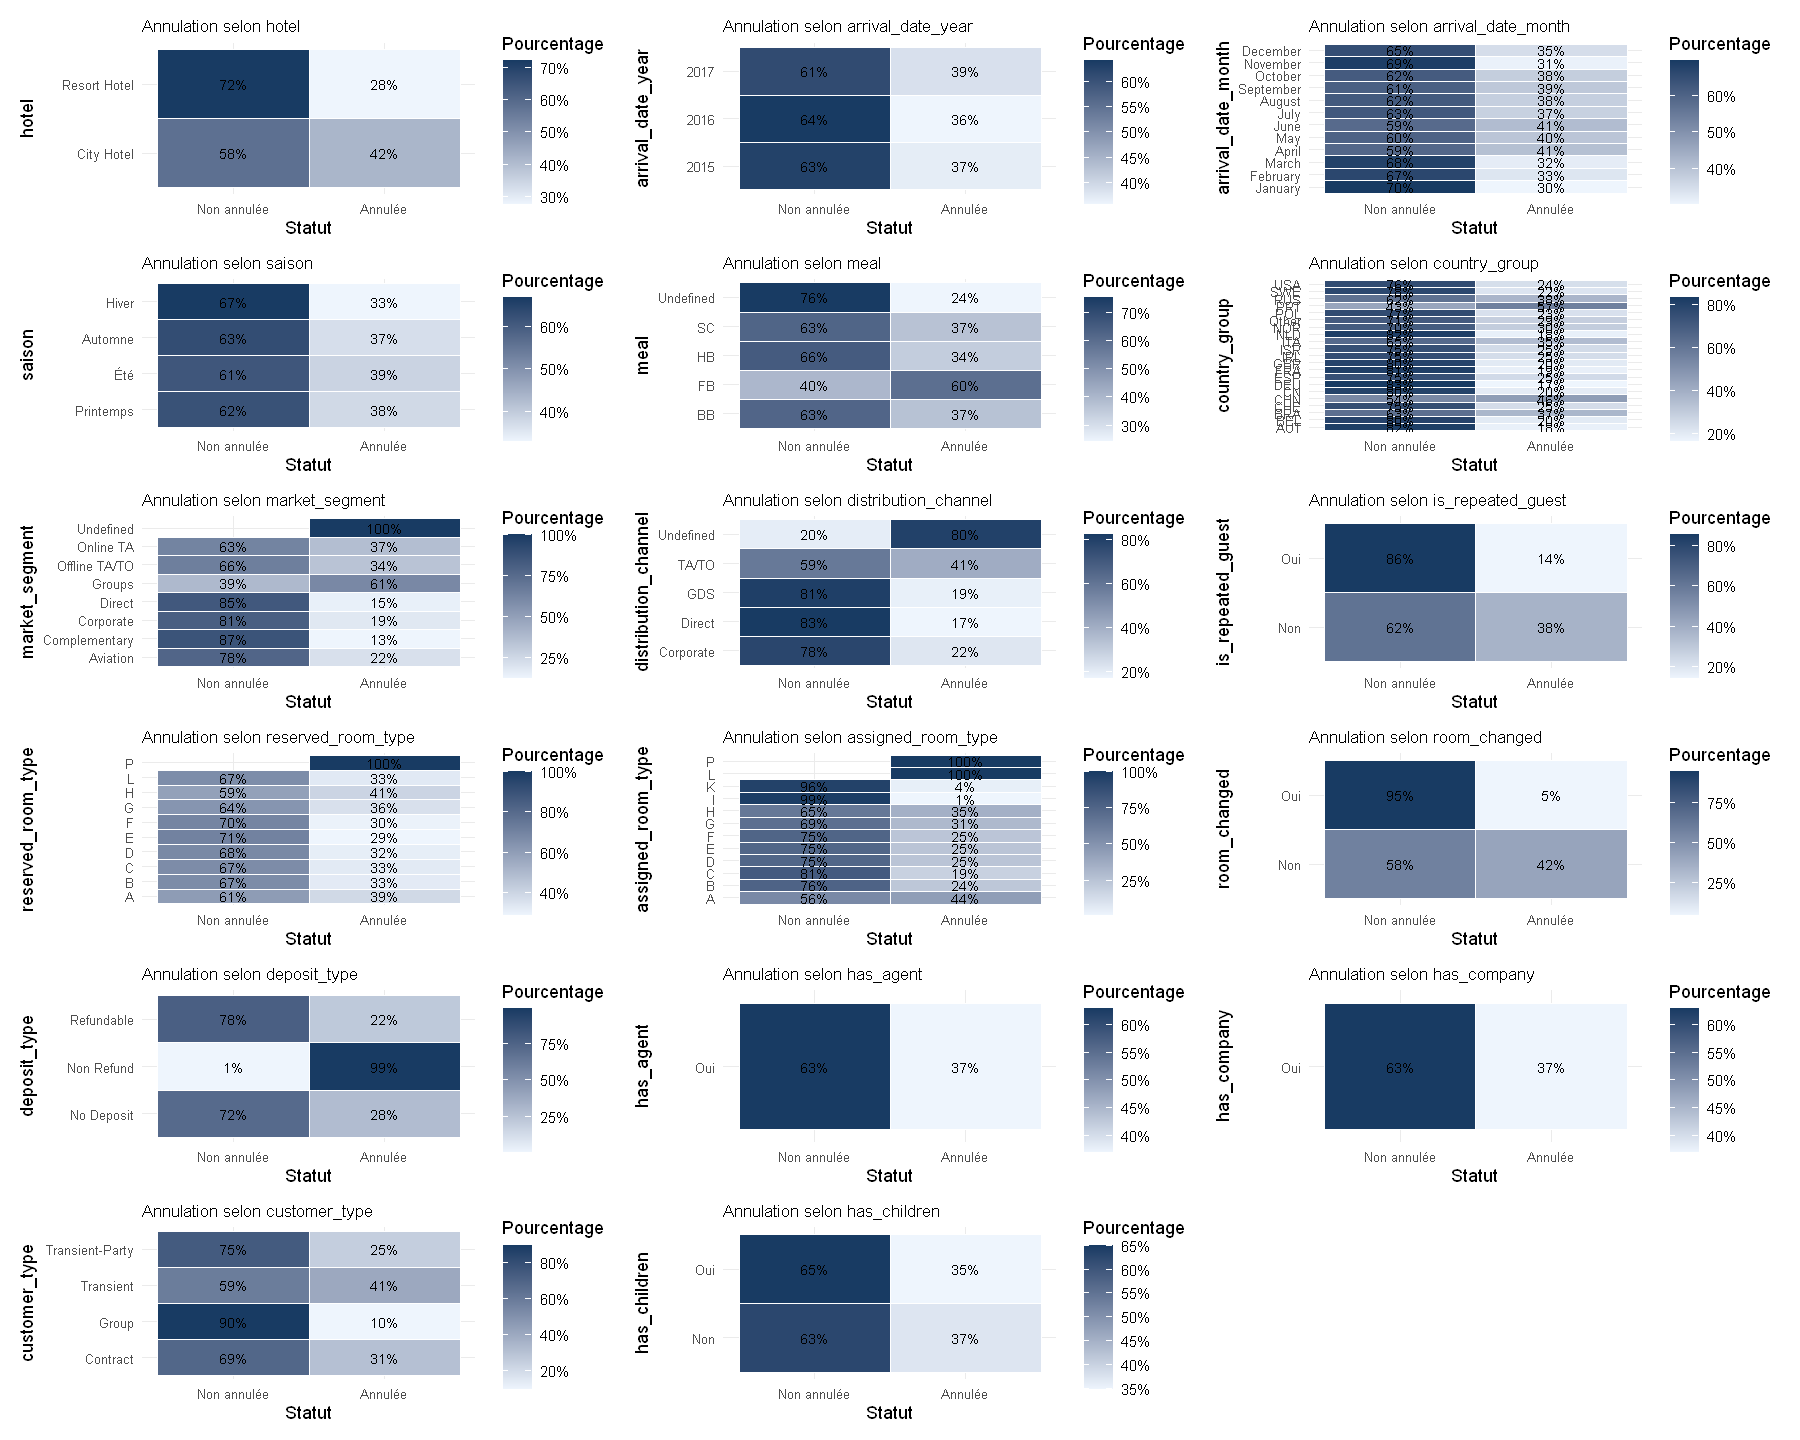

In [32]:
# BIVARIÉ QUALITATIF : chaque variable explicative x is_canceled
options(repr.plot.width = 15, repr.plot.height = 12)
plots <- list()

for (x in vars_quali) {
  
  # Calcul des pourcentages par groupe
  resume <- hotels |>
    group_by(.data[[x]]) |>
    count(is_canceled, name = "effectif") |>
    mutate(pourcentage = effectif / sum(effectif)) |>
    ungroup()

  # Création du graphique (Heatmap)
  p <- ggplot(resume, aes(x = is_canceled, y = .data[[x]], fill = pourcentage)) +
    geom_tile(color = "white") +
    geom_text(aes(label = scales::percent(pourcentage, accuracy = 1)), size = 3) +
    scale_fill_gradient(
      low = "#eef5fd",
      high = "#183b63",
      labels = scales::percent
    ) +
    labs(
      title = paste("Annulation selon", x),
      x = "Statut",
      y = x,
      fill = "Pourcentage"
    ) +
    theme_minimal() +
    theme(
      plot.title = element_text(size = 10),
      axis.text = element_text(size = 8)
    )

  # Stockage dans la liste
  plots[[x]] <- p
}

# Affichage de tous les graphiques rassemblés (3 par ligne)
wrap_plots(plots, ncol = 3)

**hotel** — Écart net et lisible : City Hotel annule à 41,7 %, Resort Hotel à 27,8 %. Près de 14 points d'écart : le type d'hôtel est lié à l'annulation, la clientèle urbaine annule nettement plus que la clientèle de resort.

**arrival_date_month** — Heatmap presque uniforme : les taux vont de 30,5 % (janvier) à 41,5 % (juin), avec un léger creux en hiver (janvier, novembre, mars ~30-32 %) et un léger pic au printemps/début d'été (avril-juin ~41 %). Il y a une saisonnalité de l'annulation, mais faible — aucun mois ne se détache franchement.

**meal** — BB (37,4 %), SC (37,2 %) et HB (34,5 %) sont collées au taux global : la formule repas ne différencie presque rien. Deux exceptions à manier avec prudence : FB à 59,9 % mais sur 798 réservations seulement, et « Undefined » à 24,5 % — des modalités trop petites pour conclure.

**market_segment** — Un des contrastes les plus forts : Groups annule à 61,1 %, contre 36,7 % (Online TA) et 34,3 % (Offline TA/TO) au centre, et un bas de tableau très différent — Direct 15,3 %, Corporate 18,7 %, Complementary 13,1 %. Les réservations de groupes sont massivement plus fragiles ; les canaux engagés (direct, corporate) annulent deux à quatre fois moins. Le « Undefined » à 100 % porte sur 2 lignes : à ignorer.

**distribution_channel** — Même histoire vue par le canal : TA/TO 41 % contre Direct 17,5 %, Corporate 22,1 %, GDS 19,2 %. Réserver via une agence plus que double le taux d'annulation par rapport au direct. (« Undefined » à 80 % = 5 lignes, artefact.)

**is_repeated_guest** — Contraste propre et interprétable : les clients déjà venus annulent à 14,5 %, les nouveaux à 37,8 %. La fidélité divise le risque d'annulation par plus de deux — c'est un des signaux les plus nets de tes heatmaps.

**reserved_room_type** — Heatmap quasi plate : de 29,3 % (E) à 40,8 % (H), avec A à 39,1 % et D à 31,8 %. Aucun type de chambre ne se détache vraiment ; le « P » à 100 % est un artefact (12 réservations). Relation probablement faible, le khi-deux le confirmera ou non, mais visuellement il n'y a pas de signal.

**deposit_type** — La heatmap la plus spectaculaire : Non Refund = 99,4 % d'annulation, contre No Deposit 28,4 % et Refundable 22,2 %. Une ligne presque entièrement sombre d'un côté, claire de l'autre. C'est LA relation dominante des variables qualitatives — contre-intuitive (on attendrait l'inverse : un dépôt non remboursable devrait retenir le client), elle suggère que ce type de tarif est choisi pour des réservations déjà incertaines, ou annulé quasi systématiquement par construction de l'offre.

**customer_type** — Gradient clair : Transient (individuels) 40,8 %, Contract 31 %, Transient-Party 25,4 %, Group 10,2 %. Plus la réservation est individuelle et flexible, plus elle annule ; les groupes constitués, très engagés, annulent peu. À ne pas confondre avec le segment Groups (61 %) : le « Group » de customer_type ne compte que 577 réservations très encadrées, là où le segment Groups (19 811) passe par les agences.

**has_agent** — Écart modéré : avec agent 39 %, sans agent 25 %. Le passage par un agent va avec davantage d'annulations — cohérent avec TA/TO : l'intermédiation rend l'annulation plus facile ou moins engageante.

**has_company** — Relation inverse de la précédente : avec entreprise identifiée 18 %, sans 38 %. Les réservations rattachées à une entreprise sont deux fois plus stables — un engagement professionnel, pas une réservation d'impulsion.

**country_group** — Vraie dispersion entre pays : le Portugal, pourtant 40,7 % des réservations, annule le plus à 56,6 % — la clientèle domestique, qui réserve facilement et sans frais, annule massivement. À l'autre extrême, l'Allemagne (16,7 %), les Pays-Bas (18,4 %), la France (18,6 %) et le Royaume-Uni (20,2 %) annulent peu : des clientèles internationales qui s'engagent (voyage organisé, transport) annulent trois fois moins. La Chine ressort à 46,3 % mais sur ~1 000 lignes.

**En synthèse** : les heatmaps font apparaître trois niveaux. Des relations fortes et structurantes — deposit_type (99,4 % !), market_segment et distribution_channel (l'intermédiation), is_repeated_guest, country_group. Des relations modérées — hotel, customer_type, has_agent, has_company. Et des relations faibles ou nulles visuellement — arrival_date_month, meal, reserved_room_type, où les lignes se ressemblent toutes. C'est exactement ce que tes khi-deux et V de Cramér devraient retrouver ; si un V contredit une heatmap très contrastée, ce sera presque toujours une histoire de petits effectifs (Undefined, P, FB).

### Validation par le test du Chi-deux d'indépendance

In [34]:
# Création d'un dataframe pour stocker les résultats du Chi-2
resultats_chi2 <- data.frame(
  Variable = character(),
  Statistique_Chi2 = numeric(),
  p_value = numeric(),
  Significatif = character(),
  stringsAsFactors = FALSE
)

for (x in vars_quali) {
  # 1. Table de contingence entre la variable x et is_canceled
  tbl <- table(hotels[[x]], hotels$is_canceled)
  
  # 2. Réalisation du test du Chi-2
  test <- chisq.test(tbl)
  
  # 3. Stockage des résultats
  resultats_chi2 <- rbind(resultats_chi2, data.frame(
    Variable = x,
    Statistique_Chi2 = round(test$statistic, 2),
    p_value = format.pval(test$p.value, digits = 3),
    Significatif = ifelse(test$p.value < 0.05, "Oui (p < 0.05)", "Non")
  ))
}

# Affichage du tableau recapitulatif des tests
print(resultats_chi2)

Warning message in chisq.test(tbl):
"Chi-squared approximation may be incorrect"
Warning message in chisq.test(tbl):
"Chi-squared approximation may be incorrect"
Warning message in chisq.test(tbl):
"Chi-squared approximation may be incorrect"
Warning message in chisq.test(tbl):
"Chi-squared approximation may be incorrect"


                        Variable Statistique_Chi2  p_value   Significatif
X-squared                  hotel          2224.92   <2e-16 Oui (p < 0.05)
X-squared1     arrival_date_year            81.63   <2e-16 Oui (p < 0.05)
X-squared2    arrival_date_month           588.69   <2e-16 Oui (p < 0.05)
X-squared3                saison           194.00   <2e-16 Oui (p < 0.05)
X-squared4                  meal           304.24   <2e-16 Oui (p < 0.05)
X-squared5         country_group         14676.48   <2e-16 Oui (p < 0.05)
X-squared6        market_segment          8497.22   <2e-16 Oui (p < 0.05)
X-squared7  distribution_channel          3745.79   <2e-16 Oui (p < 0.05)
X-squared8     is_repeated_guest           857.41   <2e-16 Oui (p < 0.05)
X-squared9    reserved_room_type           647.84   <2e-16 Oui (p < 0.05)
X-squared10   assigned_room_type          4918.69   <2e-16 Oui (p < 0.05)
X-squared11         room_changed          7327.82   <2e-16 Oui (p < 0.05)
X-squared12         deposit_type      

* **Significativité ($p$-value) :** Pour l'ensemble des 12 variables qualitatives, la $p$-value est extrêmement faible ($p < 2 \times 10^{-16}$). L'hypothèse nulle d'indépendance ($H_0$) est donc rejetée avec une grande confiance statistique.
* **Hiérarchie de l'impact (selon la statistique $\chi^2$) :**
  1. **`deposit_type` ($\chi^2 = 27\,677,33$) :** De loin la variable qui présente la plus forte dépendance statistique avec le statut d'annulation.
  2. **`country_group` ($\chi^2 = 14\,676,48$)** et **`market_segment` ($\chi^2 = 8\,497,22$) :** Facteurs majeurs influençant la décision d'annulation.
  3. **`distribution_channel` ($\chi^2 = 3\,745,79$), `customer_type` ($\chi^2 = 2\,222,50$) et `hotel` ($\chi^2 = 2\,224,92$) :** Facteurs à impact modéré mais très significatif.
  4. **`meal` ($\chi^2 = 304,24$) et `arrival_date_month` ($\chi^2 = 588,69$) :** Bien que statistiquement significatifs, ils présentent une liaison plus faible.

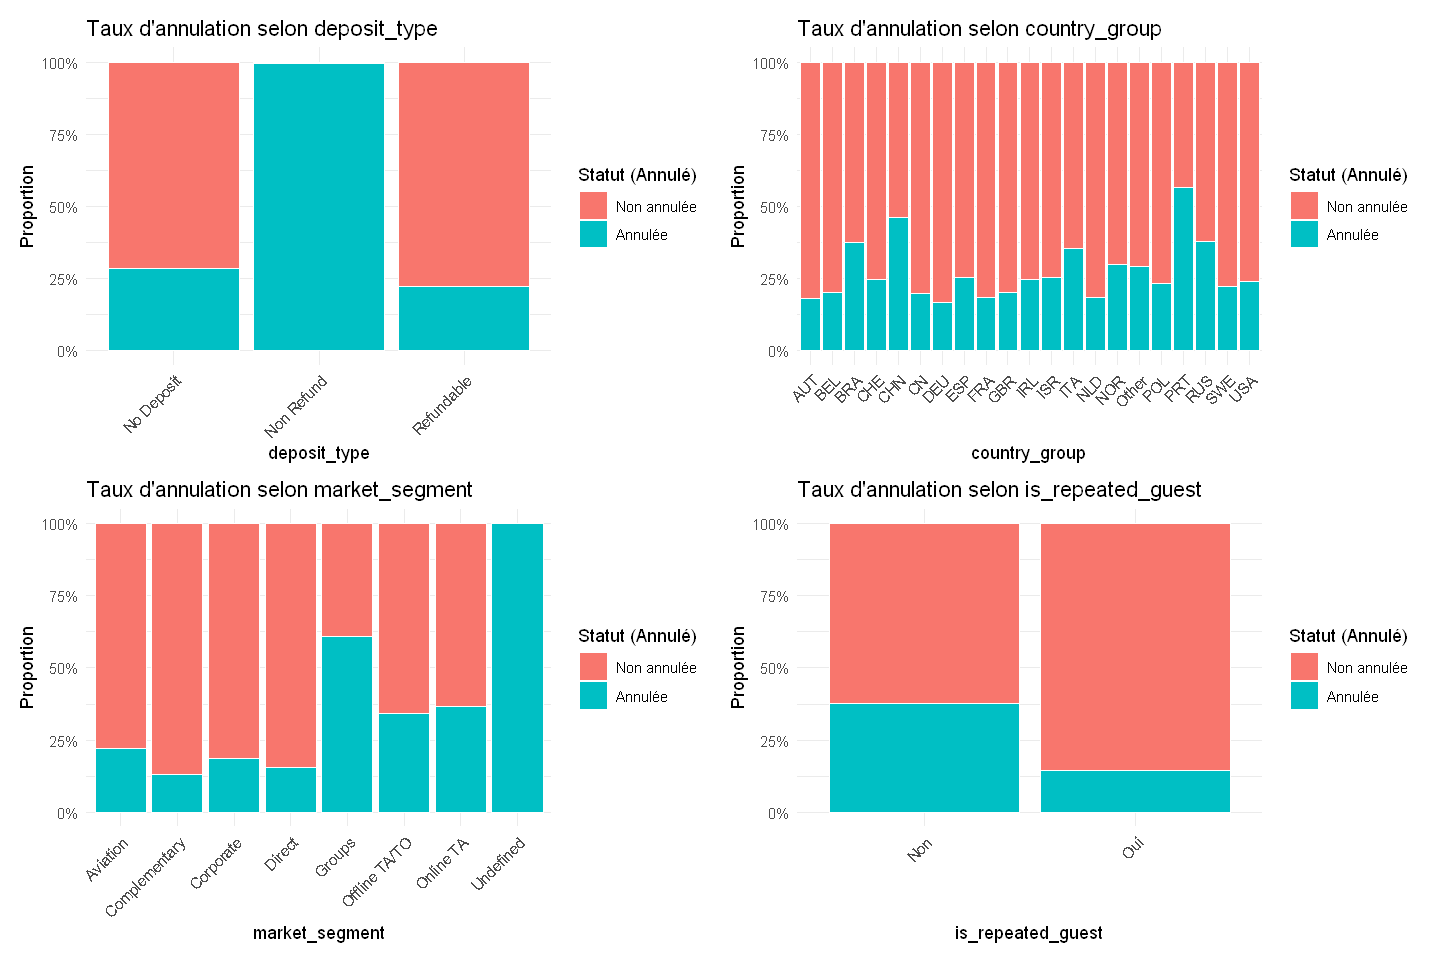

In [41]:
options(repr.plot.width = 12, repr.plot.height = 8)

best_estimator <- c(
  "deposit_type",
  "country_group",
  "market_segment",
  "is_repeated_guest"
)
plots <- list()
for (x in best_estimator) {

  p <- ggplot(hotels, aes(x = .data[[x]], fill = factor(is_canceled))) +
    geom_bar(position = "fill", color = "white", linewidth = 0.2) +
    scale_y_continuous(labels = scales::percent) +
    labs(
      title = paste("Taux d'annulation selon", x),
      x = x,
      y = "Proportion",
      fill = "Statut (Annulé)"
    ) +
    theme_minimal() +
    theme(
      axis.text.x = element_text(angle = 45, hjust = 1)
    )

  plots[[x]] <- p
}

# Affichage : 2 graphiques par ligne
wrap_plots(plots, ncol = 2)

La lecture visuelle des barres empilées confirme que les variables `deposit_type`, `market_segment` et `is_repeated_guest` possèdent les variations de hauteurs les plus marquées. Elles constituent les prédicteurs les plus puissants à prioriser dans les futurs modèles prédictifs.

### BIVARIÉ QUANTITATIF : chaque variable explicative x is_canceled

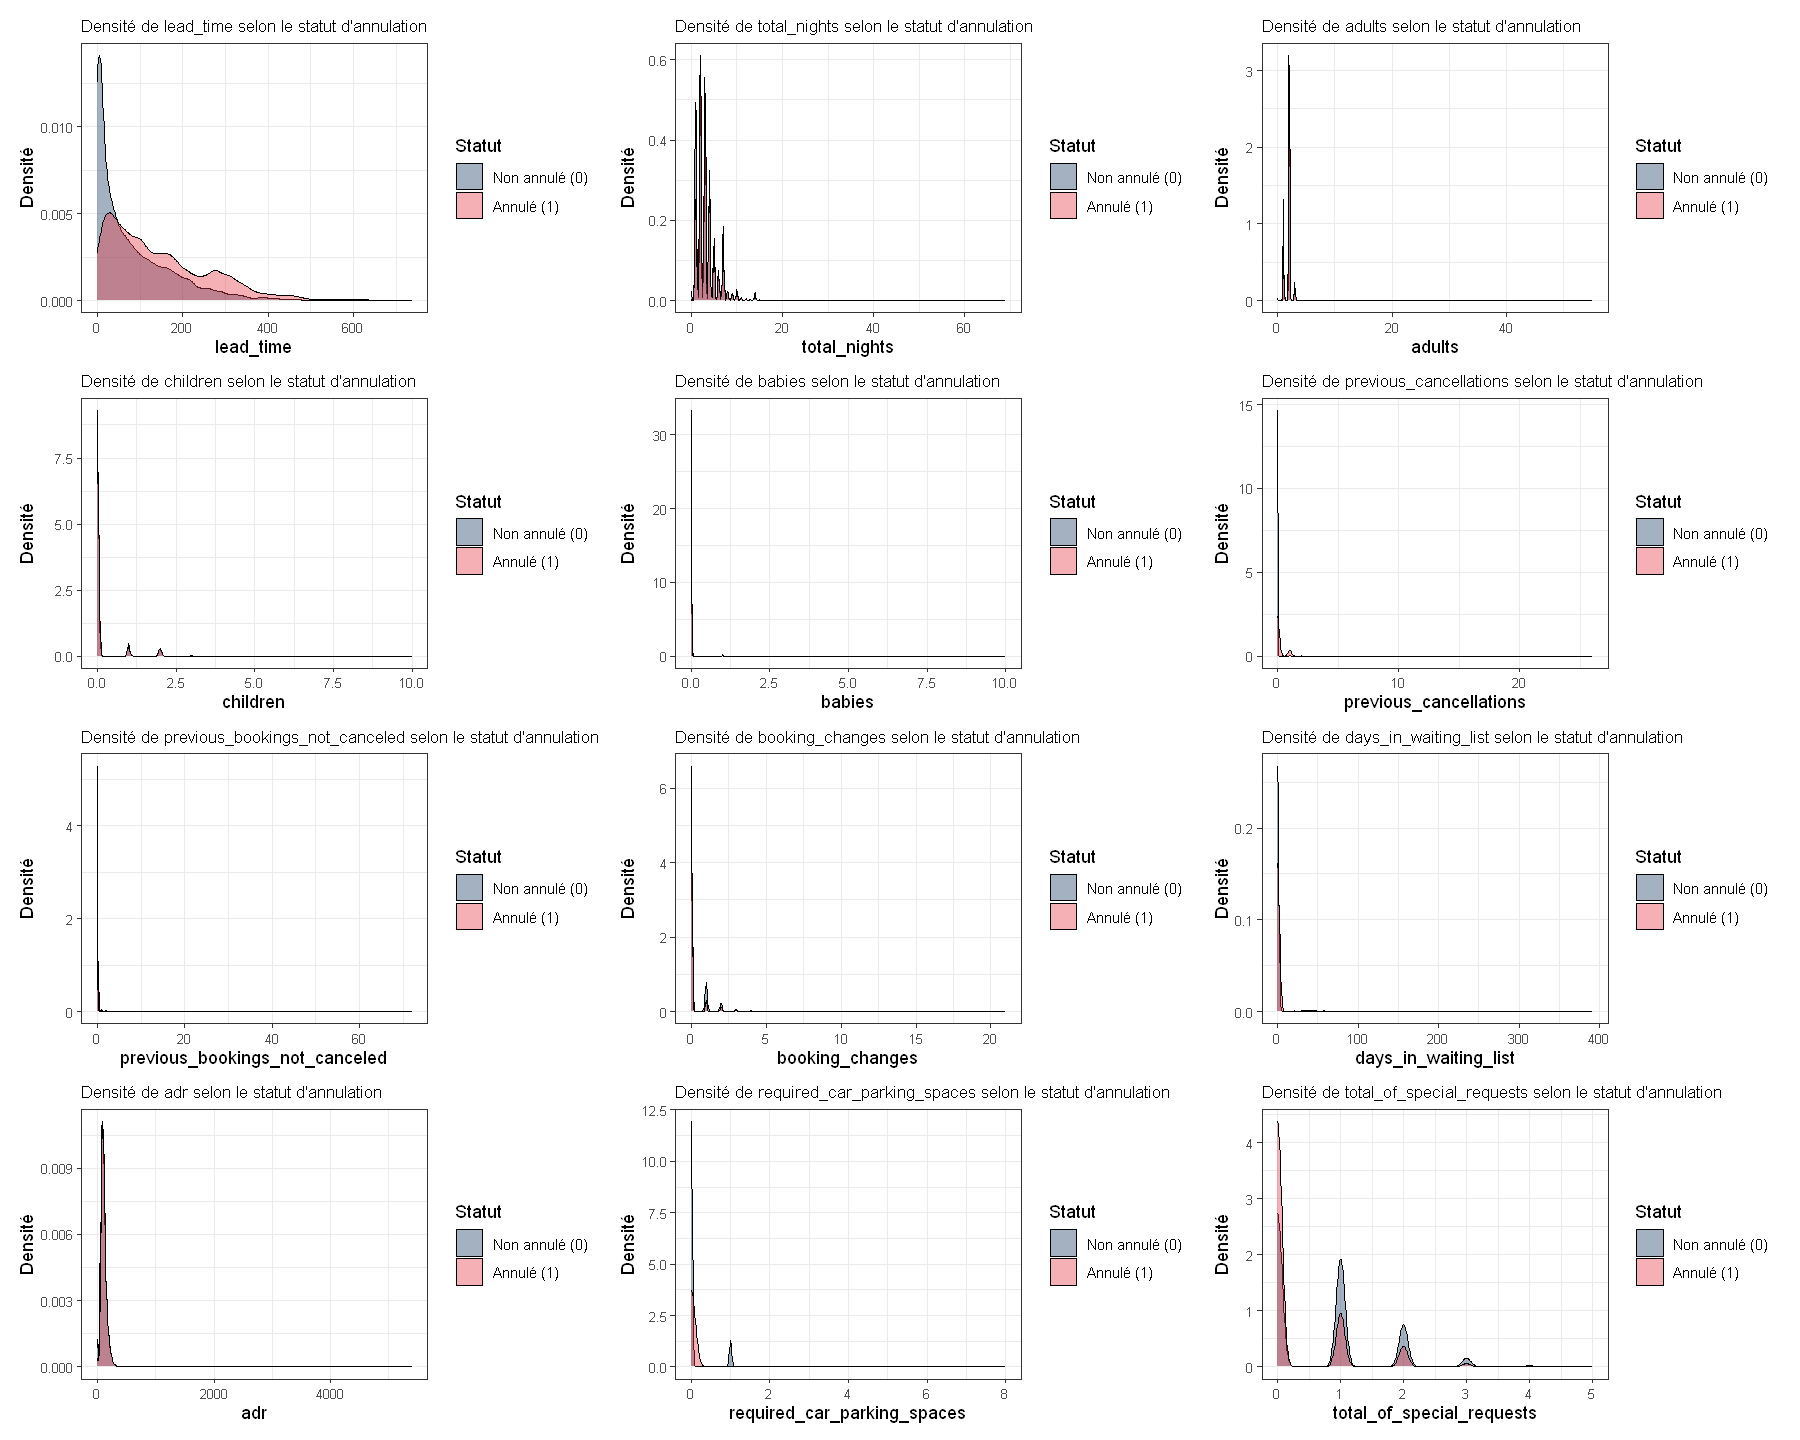

In [42]:
options(repr.plot.width = 15, repr.plot.height = 12)
vars_quanti <- c(
  "lead_time",
  "total_nights",
  "adults",
  "children",
  "babies",
  "previous_cancellations",
  "previous_bookings_not_canceled",
  "booking_changes",
  "days_in_waiting_list",
  "adr",
  "required_car_parking_spaces",
  "total_of_special_requests"
)
plots <- list()
for (x in vars_quanti) {
  p <- ggplot(hotels, aes(x = .data[[x]], fill = factor(is_canceled))) +
    geom_density(alpha = 0.4, na.rm = TRUE) +
    scale_fill_manual(
      values = c("#183b63", "#e63946"),
      labels = c("Non annulé (0)", "Annulé (1)")
    ) +
    labs(
      title = paste("Densité de", x, "selon le statut d'annulation"),
      x = x,
      y = "Densité",
      fill = "Statut"
    ) +
    theme_bw() +
    theme(
      plot.title = element_text(size = 10),
      axis.text = element_text(size = 8)
    )

  plots[[x]] <- p
}
# Affichage de 3 graphiques par ligne
wrap_plots(plots, ncol = 3)

**lead_time** — La séparation la plus nette des 12 graphiques. Les non-annulées (en sombre) forment un pic aigu près de 0 : elles réservent à la dernière minute. Les annulées (en rose) sont étalées vers la droite, avec des bosses vers 200-400 jours. C'est visible à l'œil nu et ça correspond aux chiffres : médiane 113 jours pour les annulées contre 45 pour les non-annulées. Réserver tôt = annuler plus.

**total_nights** — Les deux courbes sont presque superposées, avec les mêmes pics sur 2, 3, 4 nuits. Les annulées sont à peine plus concentrées sur les courts séjours. Visuellement : pas de relation marquée, la durée du séjour ne distingue pas vraiment les annulations.

**adults** — Un pic unique et identique sur 2 adultes pour les deux groupes. Aucune séparation : le nombre d'adultes ne dit rien sur l'annulation.

**children** — Pic massif à 0 des deux côtés. On distingue de petites bosses à 1 et 2 enfants légèrement plus hautes chez les non-annulées : la présence d'enfants va avec un peu moins d'annulations, mais l'effet est faible et noyé dans le pic de zéro.

**babies** — Un seul pic à 0, rien d'autre. Variable inexploitable visuellement : 99,2 % de zéros des deux côtés, aucune interprétation possible.

**previous_cancellations** — Petit graphique, vrai signal : le pic à 0 domine partout, mais les bosses à 1, 2, 3 annulations passées sont nettement plus présentes chez les annulées (moyenne 0,21 contre 0,02). Les clients qui ont déjà annulé annulent à nouveau — un comportement qui se répète.

**previous_bookings_not_canceled** — Pic à 0 quasi total des deux côtés ; la queue de distribution (clients avec un historique de réservations honorées) est un peu plus épaisse chez les non-annulées. Signal faible, dans le sens attendu : un passé de réservations tenues va avec moins d'annulations.

**booking_changes** — Séparation discrète mais réelle : les non-annulées ont des bosses visibles à 1, 2, 3 modifications, les annulées restent collées à 0 (moyennes 0,29 contre 0,10). Modifier sa réservation, c'est s'y engager — ceux qui ajustent leur séjour sont ceux qui le gardent.

**days_in_waiting_list** — Deux pics à 0 superposés, rien d'autre de lisible (96,9 % de zéros). Aucune interprétation visuelle possible ; seul le test statistique pourra dire s'il se passe quelque chose dans la minuscule minorité concernée.

**adr** — Les deux courbes se recouvrent presque parfaitement autour du pic 50-150 € ; les annulées sont très légèrement décalées vers la droite (moyennes 105 contre 100). Relation très faible. Note le piège visuel : l'axe s'étire jusqu'à 5 400 à cause de la valeur aberrante vue en univarié, ce qui écrase tout le graphique sur la gauche.

**required_car_parking_spaces** — Le contraste est dans la petite bosse à 1 : elle est nette chez les non-annulées, presque absente chez les annulées (moyenne 0,099 contre ~0,00). Demander une place de parking — un geste d'engagement concret, souvent lié à venir en voiture — va avec quasiment aucune annulation.

**total_of_special_requests** — La deuxième séparation la plus claire : les annulées sont massées à 0 demande, les non-annulées se déplacent vers 1, 2, 3 demandes (moyennes 0,33 contre 0,71). Chaque demande spéciale est un investissement dans le séjour — et ça se voit directement sur les courbes.

**Synthèse**
Trois groupes se dégagent. Signal fort et visible : lead_time (dans un sens) et total_of_special_requests (dans l'autre) — l'anticipation pousse à annuler, l'engagement retient. Signal modéré mais cohérent : booking_changes, previous_cancellations, required_car_parking_spaces — toutes des variables d'engagement ou d'historique. Pas de signal lisible : adults, babies, days_in_waiting_list, total_nights, et un adr à peine décalé. Deux limites à garder en tête pour ton interprétation écrite : ces densités sont difficiles à lire pour les variables de comptage écrasées à zéro (le graphique seul ne suffit pas, d'où les tests), et plusieurs effets réels sont petits en valeur absolue même quand les courbes se séparent — ce sont les tailles d'effet du bilan qui trancheront.

### Validation par le test de student

In [44]:
# Dataframe pour stocker les résultats du test de Student
resultats_tests_quanti <- data.frame(
  Variable = character(),
  Statistique_t = numeric(),
  p_value = character(),
  Significatif = character(),
  stringsAsFactors = FALSE
)

for (x in vars_quanti) {
  
  # 1. Réalisation du test de Student
  test_t <- t.test(hotels[[x]] ~ hotels$is_canceled)
  
  # 2. Stockage des résultats
  resultats_tests_quanti <- rbind(resultats_tests_quanti, data.frame(
    Variable = x,
    Statistique_t = round(test_t$statistic, 2),
    p_value = format.pval(test_t$p.value, digits = 3),
    Significatif = ifelse(test_t$p.value < 0.05, "Oui (p < 0.05)", "Non")
  ))
}

# Affichage du tableau récapitulatif dans le notebook
print(resultats_tests_quanti)

                          Variable Statistique_t  p_value   Significatif
t                        lead_time        -99.07   <2e-16 Oui (p < 0.05)
t1                    total_nights         -6.18 6.47e-10 Oui (p < 0.05)
t2                          adults        -19.34   <2e-16 Oui (p < 0.05)
t3                        children         -1.72   0.0852            Non
t4                          babies         12.91   <2e-16 Oui (p < 0.05)
t5          previous_cancellations        -30.03   <2e-16 Oui (p < 0.05)
t6  previous_bookings_not_canceled         24.19   <2e-16 Oui (p < 0.05)
t7                 booking_changes         56.75   <2e-16 Oui (p < 0.05)
t8            days_in_waiting_list        -17.09   <2e-16 Oui (p < 0.05)
t9                             adr        -16.17   <2e-16 Oui (p < 0.05)
t10    required_car_parking_spaces         89.80   <2e-16 Oui (p < 0.05)
t11      total_of_special_requests         88.89   <2e-16 Oui (p < 0.05)


Le tableau récapitulatif des tests de Student met en évidence le rôle clé de la quasi-totalité des variables quantitatives dans la prédiction des annulations :

* **Le prédicateur majeur — Délai de réservation (`lead_time`, $t = -99{,}07$, $p < 2 \times 10^{-16}$) :** C'est la variable quantitative la plus discriminante. Les réservations annulées affichent un délai d'anticipation considérablement plus élevé. Plus une réservation est effectuée tôt, plus le risque d'annulation augmente.
* **Les facteurs d'engagement du client :**
  * **Demandes de parking (`required_car_parking_spaces`, $t = 89{,}80$) et Demandes spéciales (`total_of_special_requests`, $t = 88{,}89$) :** Ces deux variables affichent une relation fortement positive avec le maintien de la réservation. Un client qui formule des requêtes particulières ou réserve une place de parking démontre un engagement fort, ce qui réduit drastiquement la probabilité d'annulation.
  * **Modifications de réservation (`booking_changes`, $t = 56{,}75$) :** Les clients qui modifient les paramètres de leur dossier avant leur arrivée annulent nettement moins, traduisant une intention de séjour stable.
* **L'historique et le profil des voyageurs :**
  * **Réservations passées honorées (`previous_bookings_not_canceled`, $t = 24{,}19$) vs. Annulations passées (`previous_cancellations`, $t = -30{,}03$) :** L'historique du client constitue un excellent indicateur de fiabilité ou de risque.
  * **Nombre d'adultes (`adults`, $t = -19{,}34$) et Bébés (`babies`, $t = 12{,}91$) :** La composition du groupe de voyageurs exerce une influence statistiquement avérée.
  * **Durée totale du séjour (`total_nights`, $t = -6{,}18$, $p = 6{,}47 \times 10^{-10}$) :** La variable synthétique combinant nuits de semaine et de week-end montre un effet significatif, confirmant que la longueur de l'engagement pèse dans la décision finale.
* **Variable non significative :**
  * **Nombre d'enfants (`children`, $p = 0{,}0852$) :** Avec une $p$-value supérieure au seuil de $0{,}05$, la présence d'enfants ne présente pas de différence de moyenne statistiquement significative entre les deux groupes et n'influence pas directement le risque d'annulation.

> **Synthèse méthodologique :** À l'exception du nombre d'enfants, l'ensemble des variables quantitatives sélectionnées démontre une réelle valeur explicative et constituera un socle solide pour l'élaboration d'un  modèle de prédiction.